In [1]:
from google.colab import drive
import pandas as pd
import numpy as np

In [2]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
# Replace with the path to YOUR dataset zip file in Google Drive
zip_path = "/content/drive/MyDrive/2º año master/hs_public_dataset.zip"
zip_path2 = "/content/drive/MyDrive/HealthTech/ALMIRALL DATA - INNOVATION CHALLENGE 2026/hs_public_dataset.zip"
# Unzip the dataset
!unzip -o "$zip_path" -d Data
!unzip -o "$zip_path2" -d Data

# Move into the extracted folder
%cd Data

Archive:  /content/drive/MyDrive/2º año master/hs_public_dataset.zip
   creating: Data/public/
   creating: Data/public/evaluation_templates/
  inflating: Data/public/evaluation_templates/answers_teamName_exercise3_images.csv  
  inflating: Data/public/evaluation_templates/answers_teamName_exercise3_images_rnaseq.csv  
  inflating: Data/public/evaluation_templates/answers_teamName_exercise2.csv  
  inflating: Data/public/evaluation_templates/answers_teamName_exercise1.csv  
   creating: Data/public/test_1/
  inflating: Data/public/test_1/patient_assignment.csv  
  inflating: Data/public/test_1/answers_teamName_exercise3_images.csv  
  inflating: Data/public/test_1/answers_teamName_exercise3_images_rnaseq.csv  
  inflating: Data/public/test_1/surgeries.csv  
  inflating: Data/public/test_1/images_metadata.csv  
  inflating: Data/public/test_1/visits.csv  
  inflating: Data/public/test_1/demographics.csv  
  inflating: Data/public/test_1/treatments.csv  
  inflating: Data/public/test_1/r

In [5]:
import os
import pandas as pd

# Safe check for the extracted Data folder
data_path = "/content/Data/public/train"
if not os.path.exists(data_path):
    print("Error: The unzipped data directory '/content/Data' was not found.")
    print("Please verify that cell '4r_1aP3tRJ6D' ran successfully and that the zip file paths are correct.")
    print("\nSearching for 'visits.csv' in your mounted Google Drive to help you find the correct path:")

    found_files = []
    for root, dirs, files in os.walk("/content/drive"):
        if "visits.csv" in files:
            found_files.append(os.path.join(root, "visits.csv"))

    if found_files:
        print("Found 'visits.csv' at these path(s):")
        for f in found_files:
            print(f"  - {f}")
    else:
        print("Could not find 'visits.csv' in Google Drive. Ensure your Drive is mounted properly and the dataset is uploaded.")
else:
    # Load the datasets if the directory exists
    df_visits = pd.read_csv(f"{data_path}/visits.csv")
    df_doctor = pd.read_csv(f"{data_path}/patient_assignment.csv")
    df_demo = pd.read_csv(f"{data_path}/demographics.csv")
    df_surgery = pd.read_csv(f"{data_path}/surgeries.csv")
    df_targets = pd.read_csv(f"{data_path}/targets.csv")
    df_treatment = pd.read_csv(f"{data_path}/treatments.csv")
    df_im_embed = pd.read_csv(f"{data_path}/images_embeddings.csv")
    df_im_meta = pd.read_csv(f"{data_path}/images_metadata.csv")
    df_rna_embed = pd.read_csv(f"{data_path}/rnaseq_embeddings.csv")
    df_rna_meta = pd.read_csv(f"{data_path}/rnaseq_metadata.csv")
    print("All datasets loaded successfully!")

All datasets loaded successfully!


--- Información General del DataFrame ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21000 entries, 0 to 20999
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   patient_id              21000 non-null  object 
 1   sex                     21000 non-null  object 
 2   birth_year              21000 non-null  int64  
 3   age_at_diagnosis        21000 non-null  int64  
 4   ethnicity               19410 non-null  object 
 5   bmi_at_baseline         18875 non-null  float64
 6   smoking_status          18495 non-null  object 
 7   symptom_onset_date      15751 non-null  object 
 8   diagnosis_date          21000 non-null  object 
 9   diagnostic_delay_years  15685 non-null  float64
 10  hurley_stage_baseline   21000 non-null  int64  
 11  family_history_hs       17408 non-null  object 
dtypes: float64(2), int64(3), object(7)
memory usage: 1.9+ MB
None

--- Resumen Estadístico ---


,patient_id,sex,birth_year,age_at_diagnosis,ethnicity,bmi_at_baseline,smoking_status,symptom_onset_date,diagnosis_date,diagnostic_delay_years,hurley_stage_baseline,family_history_hs
count,21000,21000,21000.000000,21000.000000,19410,18875.000000,18495,15751,21000,15685.000000,21000.000000,17408
unique,21000,2,NaN,NaN,5,NaN,3,4992,3130,NaN,NaN,3
top,HS000001,Female,NaN,NaN,White,NaN,Never,2014-11-26,2016-01-02,NaN,NaN,No
freq,1,15116,NaN,NaN,9354,NaN,7359,47,2070,NaN,NaN,9568
mean,NaN,NaN,1992.019619,28.683810,NaN,31.726225,NaN,NaN,NaN,4.227753,1.946429,NaN
std,NaN,NaN,7.528684,7.039129,NaN,6.835470,NaN,NaN,NaN,2.996917,0.735989,NaN
min,NaN,NaN,1957.000000,15.000000,NaN,17.000000,NaN,NaN,NaN,1.000000,1.000000,NaN
25%,NaN,NaN,1987.000000,24.000000,NaN,27.000000,NaN,NaN,NaN,2.000000,1.000000,NaN
50%,NaN,NaN,1992.000000,28.000000,NaN,31.700000,NaN,NaN,NaN,3.300000,2.000000,NaN
75%,NaN,NaN,1997.000000,33.000000,NaN,36.300000,NaN,NaN,NaN,5.600000,2.000000,NaN



--- Valores Faltantes por Columna ---
patient_id                   0
sex                          0
birth_year                   0
age_at_diagnosis             0
ethnicity                 1590
bmi_at_baseline           2125
smoking_status            2505
symptom_onset_date        5249
diagnosis_date               0
diagnostic_delay_years    5315
hurley_stage_baseline        0
family_history_hs         3592
dtype: int64


/tmp/ipykernel_346/1100828249.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_demo, x='sex', ax=axes[0, 0], palette='pastel')
/tmp/ipykernel_346/1100828249.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_demo, x='hurley_stage_baseline', ax=axes[1, 1], palette='crest')


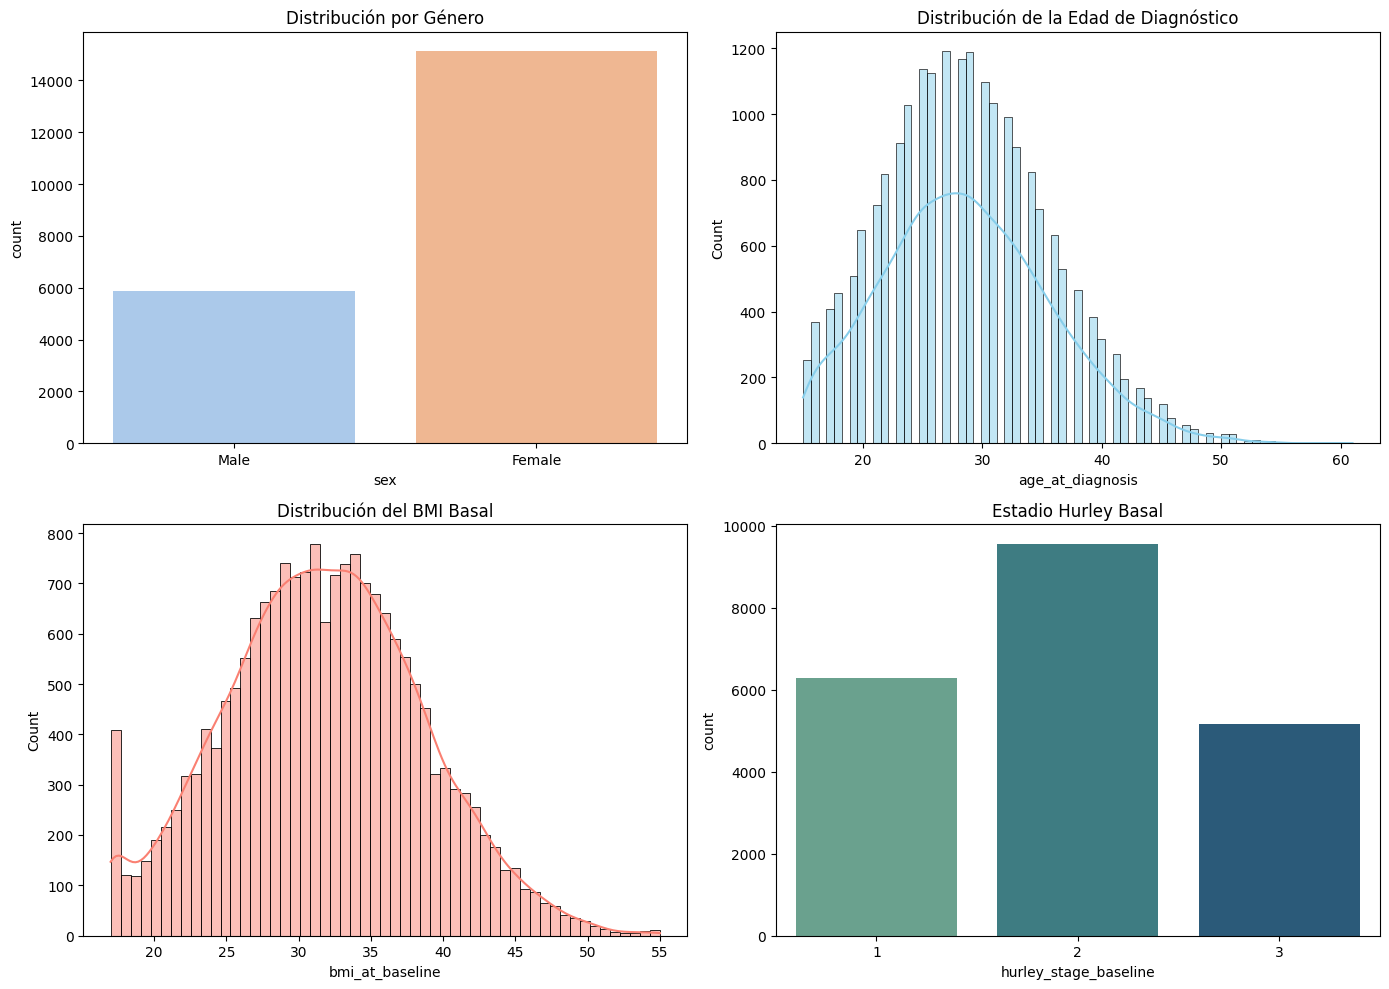

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Información general y tipos de datos
print("--- Información General del DataFrame ---")
print(df_demo.info())

# 2. Resumen estadístico de variables numéricas
print("\n--- Resumen Estadístico ---")
display(df_demo.describe(include='all'))

# 3. Detección de valores nulos
print("\n--- Valores Faltantes por Columna ---")
print(df_demo.isnull().sum())

# 4. Visualizaciones de variables clave
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Distribución del Género
sns.countplot(data=df_demo, x='sex', ax=axes[0, 0], palette='pastel')
axes[0, 0].set_title('Distribución por Género')

# Distribución de la Edad de Diagnóstico
sns.histplot(data=df_demo, x='age_at_diagnosis', kde=True, ax=axes[0, 1], color='skyblue')
axes[0, 1].set_title('Distribución de la Edad de Diagnóstico')

# Distribución de BMI (Índice de Masa Corporal)
sns.histplot(data=df_demo, x='bmi_at_baseline', kde=True, ax=axes[1, 0], color='salmon')
axes[1, 0].set_title('Distribución del BMI Basal')

# Distribución del Estadio Hurley de partida
sns.countplot(data=df_demo, x='hurley_stage_baseline', ax=axes[1, 1], palette='crest')
axes[1, 1].set_title('Estadio Hurley Basal')

plt.tight_layout()
plt.show()

In [7]:
df_visits.head()

,visit_id,patient_id,practitioner_id,visit_date,visit_type,ihs4_score
0,V13440513,HS000001,PR00001,2022-10-20,background,NaN
1,V10874137,HS000001,PR00001,2022-11-16,flare_reactive,12.0
2,V13069089,HS000001,PR00001,2022-11-23,follow_up,12.0
3,V11632066,HS000001,PR00001,2022-11-30,follow_up,10.0
4,V12930108,HS000001,PR00001,2023-02-12,treatment_monitoring,3.0


--- Información General del DataFrame ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 709690 entries, 0 to 709689
Data columns (total 6 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   visit_id         709690 non-null  object 
 1   patient_id       709690 non-null  object 
 2   practitioner_id  709690 non-null  object 
 3   visit_date       709690 non-null  object 
 4   visit_type       709690 non-null  object 
 5   ihs4_score       456406 non-null  float64
dtypes: float64(1), object(5)
memory usage: 32.5+ MB
None

--- Resumen Estadístico ---


,visit_id,patient_id,practitioner_id,visit_date,visit_type,ihs4_score
count,709690,709690,709690,709690,709690,456406.000000
unique,709690,20602,2135,3652,4,NaN
top,V13440513,HS009021,PR00150,2024-01-17,follow_up,NaN
freq,1,167,1042,420,355844,NaN
mean,NaN,NaN,NaN,NaN,NaN,12.379173
std,NaN,NaN,NaN,NaN,NaN,7.169659
min,NaN,NaN,NaN,NaN,NaN,0.000000
25%,NaN,NaN,NaN,NaN,NaN,7.000000
50%,NaN,NaN,NaN,NaN,NaN,11.000000
75%,NaN,NaN,NaN,NaN,NaN,17.000000



--- Valores Faltantes por Columna ---
visit_id                0
patient_id              0
practitioner_id         0
visit_date              0
visit_type              0
ihs4_score         253284
dtype: int64


/tmp/ipykernel_346/1831697132.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_visits, y='visit_type', ax=axes[0], palette='viridis', order=df_visits['visit_type'].value_counts().index)


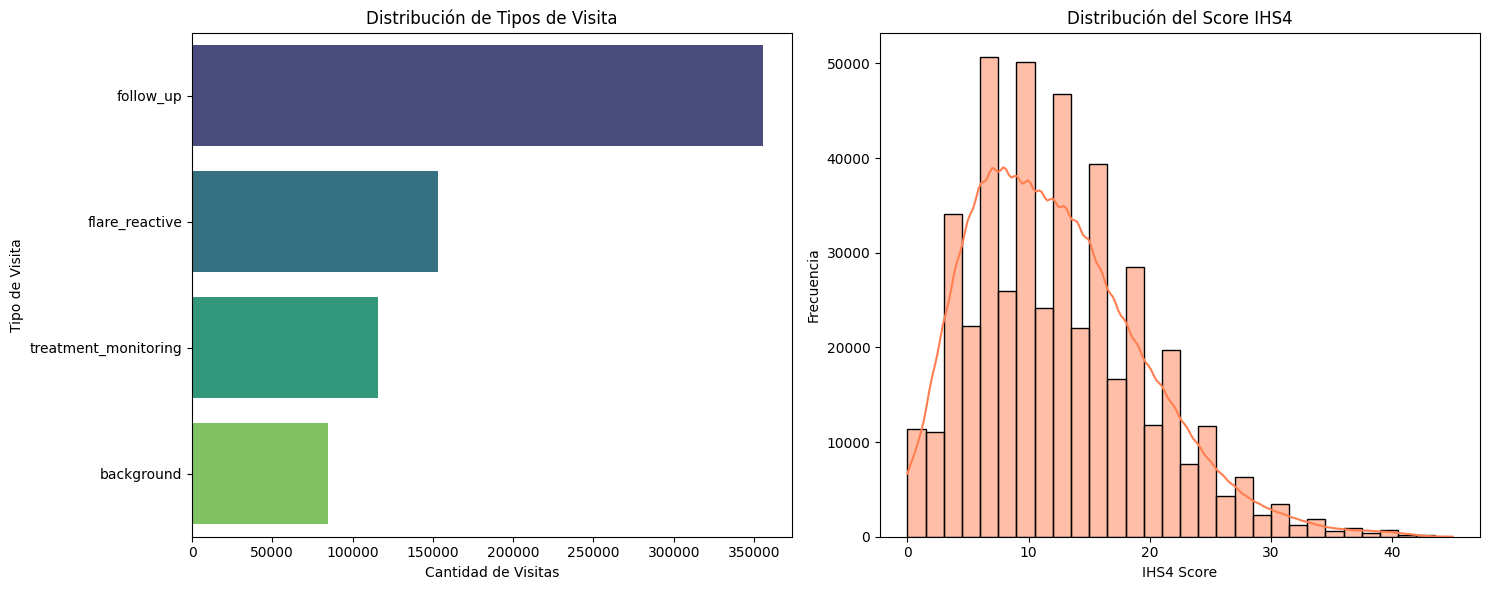

In [8]:
# 1. Información general
print("--- Información General del DataFrame ---")
print(df_visits.info())

# 2. Resumen estadístico
print("\n--- Resumen Estadístico ---")
display(df_visits.describe(include='all'))

# 3. Valores nulos
print("\n--- Valores Faltantes por Columna ---")
print(df_visits.isnull().sum())

# 4. Visualización de la distribución del tipo de visita e IHS4
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.countplot(data=df_visits, y='visit_type', ax=axes[0], palette='viridis', order=df_visits['visit_type'].value_counts().index)
axes[0].set_title('Distribución de Tipos de Visita')
axes[0].set_xlabel('Cantidad de Visitas')
axes[0].set_ylabel('Tipo de Visita')

sns.histplot(data=df_visits, x='ihs4_score', kde=True, ax=axes[1], color='coral', bins=30)
axes[1].set_title('Distribución del Score IHS4')
axes[1].set_xlabel('IHS4 Score')
axes[1].set_ylabel('Frecuencia')

plt.tight_layout()
plt.show()

As shown in the plots visit types are highly imbalanced, because most visits are `follow._ups`, followed by `flare_reactive`, `treatment_mmonitoring`.

As for the IHS4 scores, most of them are found between 5-15 while high scores are uncommon. This may indicate that severe flares are less frequent.

In [9]:
df_visits.groupby('visit_type')['ihs4_score'].agg(['count', 'mean','median', 'min','max'])

,count,mean,median,min,max
visit_type,,,,,
background,49583,8.979489,8.0,0.0,42.0
flare_reactive,101597,12.784275,12.0,0.0,45.0
follow_up,240686,13.778242,13.0,0.0,45.0
treatment_monitoring,64540,9.135807,8.0,0.0,41.0


In [10]:
df_treatment.head()

,treatment_id,patient_id,treatment_class,drug_name,route,start_date,end_date,treatment_line
0,TX0009273,HS000001,Antibiotic,Clindamycin topical,Topical,2022-11-14,2022-11-28,NaN
1,TX0148768,HS000001,Biologic,Adalimumab,Subcutaneous,2023-01-02,2024-03-09,1.0
2,TX0039367,HS000001,Antibiotic,Clindamycin topical,Topical,2023-10-31,2023-11-14,NaN
3,TX0074670,HS000001,Antibiotic,Clindamycin topical,Topical,2023-12-06,2023-12-20,NaN
4,TX0086946,HS000001,Antibiotic,Clindamycin topical,Topical,2024-01-10,2024-01-24,NaN


In [11]:
df_visits.head()

,visit_id,patient_id,practitioner_id,visit_date,visit_type,ihs4_score
0,V13440513,HS000001,PR00001,2022-10-20,background,NaN
1,V10874137,HS000001,PR00001,2022-11-16,flare_reactive,12.0
2,V13069089,HS000001,PR00001,2022-11-23,follow_up,12.0
3,V11632066,HS000001,PR00001,2022-11-30,follow_up,10.0
4,V12930108,HS000001,PR00001,2023-02-12,treatment_monitoring,3.0


In [12]:
df_demo.head()

,patient_id,sex,birth_year,age_at_diagnosis,ethnicity,bmi_at_baseline,smoking_status,symptom_onset_date,diagnosis_date,diagnostic_delay_years,hurley_stage_baseline,family_history_hs
0,HS000001,Male,1993,29,White,30.4,Never,2019-02-07,2022-09-14,3.6,2,No
1,HS000003,Male,1989,28,Black/African American,NaN,NaN,2013-05-10,2017-02-26,3.8,2,Yes
2,HS000004,Female,1992,31,Black/African American,36.8,Current,NaN,2023-12-24,10.9,3,Yes
3,HS000008,Male,1984,33,Black/African American,34.5,Never,2012-04-21,2017-07-03,5.2,1,Yes
4,HS000009,Female,1987,35,White,31.4,NaN,2019-11-09,2022-04-04,2.4,3,No


In [13]:
df_surgery.head()

,surgery_id,patient_id,visit_id,procedure_date,procedure_type,anesthesia,recurrence_within_6mo,wound_healing_weeks
0,SRG155063,HS000001,V13069089,2022-11-23,Incision & drainage,Local,0,3
1,SRG142514,HS000001,V13158160,2024-01-23,Deroofing,General,1,10
2,SRG189207,HS000001,V13980282,2025-09-13,Wide local excision,Local,0,10
3,SRG180220,HS000001,V11872858,2025-09-20,Deroofing,General,0,11
4,SRG134962,HS000003,V11086788,2017-10-10,Wide local excision,Local,1,5


In [14]:
df_doctor.head()

,patient_id,practitioner_id
0,HS000001,PR00001
1,HS000003,PR00001
2,HS000004,PR00001
3,HS000008,PR00001
4,HS000009,PR00001


In [15]:
df_targets.head()

,patient_id,avg_ihs4_next6
0,HS000001,7.3943
1,HS000003,7.9737
2,HS000004,14.2349
3,HS000008,5.4726
4,HS000009,16.5574


## Establish validation strategy and baseline models

To avoid overfitting and validate our progress locally, we held out 20% of train patients (using `val_ids`) as a local validation set, training only on the remaining 80%( `tr_ids`).
We have evaluated 4 baseline approaches using MAE (even though we are interested in `Mean IHS4 in 2025`):

1. Population mean: assigning the overall mean IHS4 score to everyone

2. Hurley Stage Mean: Assigning the mean score corresponding to each aptient's baseline Hurley stage

3. Last IHS4: Mapping the very last registered IHS4 before the cutoff

4. Mean IHS4 in 2025: Mapping the average of the scores recorded during the year 2025 for each patient

Our aim is that the model that we develop has a MAE lower than the MAE of Mean IHS4 in 2025

In [16]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error

BASE = "/content/Data/public"
CUTOFF = pd.Timestamp("2025-12-31")

df_visits = pd.read_csv(f"{BASE}/train/visits.csv", parse_dates=["visit_date"])

# Hide 20% of train patients as validation
tr_ids, val_ids = train_test_split(df_targets["patient_id"], test_size=0.2, random_state=42)
## Because the split is done on unique patient IDs before any feature merging, there is absolutely zero "data leakage" (where records of the same patient might accidentally appear in both training and validation sets).
tr = df_targets[df_targets.patient_id.isin(tr_ids)].merge(df_demo, on="patient_id")
val = df_targets[df_targets.patient_id.isin(val_ids)].merge(df_demo, on="patient_id")

# A: everyone gets the population mean
pred_a = np.full(len(val), tr["avg_ihs4_next6"].mean())
# B: mean by Hurley stage
hurley_mean = tr.groupby("hurley_stage_baseline")["avg_ihs4_next6"].mean()
pred_b = val["hurley_stage_baseline"].map(hurley_mean).fillna(tr["avg_ihs4_next6"].mean())
# C: last scored IHS4
scored = df_visits.dropna(subset=["ihs4_score"]).sort_values("visit_date")
last_ihs4 = scored.groupby("patient_id")["ihs4_score"].last()
pred_c = val["patient_id"].map(last_ihs4).fillna(tr["avg_ihs4_next6"].mean())
# D: mean IHS4 during 2025
mean_2025 = scored[scored.visit_date >= "2025-01-01"].groupby("patient_id")["ihs4_score"].mean()
pred_d = val["patient_id"].map(mean_2025).fillna(pred_c)

for name, p in [("A population mean", pred_a), ("B Hurley mean", pred_b),
                ("C last IHS4", pred_c), ("D mean IHS4 2025", pred_d)]:
    print(f"{name:20s} MAE = {mean_absolute_error(val['avg_ihs4_next6'], p):.3f}")

A population mean    MAE = 4.476
B Hurley mean        MAE = 2.700
C last IHS4          MAE = 2.815
D mean IHS4 2025     MAE = 2.751


## Build one row per patient

This function turns the messy tables into a clean patient table. The key idea is that it's a function of the folder, so you run exactly the same code on train, test_1 and test_2. That's why all three folders have the same files.

The feature groups and what each one captures:
- IHS4 history: last, mean and max, over all time and the last 6 and 12 months. Also the mean excluding flare visits, as a better estimate of the "calm" level.
- Visit behaviour: the number of each visit type, the share of visits scored, the time since the last visit, and the longest gap. This captures partial observation: many flare visits suggest an active disease, and long gaps may mean hidden flares or a patient who's doing fine.
- Treatment: whether the patient is on a biologic now, which drug, how long they've been on it, and the IHS4 before it started vs. now (an early hint for super-responders). Also antibiotic courses.
- Surgeries: count, recent count, and recurrence rate.
- Missingness flags: missing BMI or missing smoking status can carry information, as the brief says.

In [17]:
def build_features(folder):
    p = f"{BASE}/{folder}"
    demo = pd.read_csv(f"{p}/demographics.csv")
    visits = pd.read_csv(f"{p}/visits.csv", parse_dates=["visit_date"])
    treat = pd.read_csv(f"{p}/treatments.csv", parse_dates=["start_date", "end_date"])
    surg = pd.read_csv(f"{p}/surgeries.csv", parse_dates=["procedure_date"])
    doctor = pd.read_csv(f"{p}/patient_assignment.csv")

    feats = demo[["patient_id"]].copy()

    # --- Demographics ---
    d = demo.copy()
    d["age_2025"] = 2025 - d["birth_year"]
    d["years_since_diagnosis"] = (CUTOFF - pd.to_datetime(d["diagnosis_date"])).dt.days / 365.25
    d["bmi_missing"] = d["bmi_at_baseline"].isna().astype(int)
    d["smoking_missing"] = d["smoking_status"].isna().astype(int)

    for col in ["sex", "ethnicity", "smoking_status", "family_history_hs"]:
        d[col] = d[col].astype("category")
    feats = feats.merge(d[["patient_id", "sex", "ethnicity", "smoking_status", "family_history_hs",
                           "age_2025", "age_at_diagnosis", "bmi_at_baseline", "bmi_missing",
                           "smoking_missing", "diagnostic_delay_years", "hurley_stage_baseline",
                           "years_since_diagnosis"]], on="patient_id", how="left")

    # --- IHS4 history ---
    sc = visits.dropna(subset=["ihs4_score"]).sort_values("visit_date")
    g = sc.groupby("patient_id")
    ihs = pd.DataFrame({
        "ihs4_last": g["ihs4_score"].last(),
        "ihs4_first": g["ihs4_score"].first(),
        "ihs4_mean_all": g["ihs4_score"].mean(),
        "ihs4_max_all": g["ihs4_score"].max(),
        "ihs4_n_scored": g["ihs4_score"].count(),
        "days_since_last_score": (CUTOFF - g["visit_date"].max()).dt.days,
    })

    # Tendencies of disease
    ihs["ihs4_delta_total"] = ihs["ihs4_last"] - ihs["ihs4_first"]

    for months in [6, 12]:
        recent = sc[sc.visit_date > CUTOFF - pd.DateOffset(months=months)]
        rg = recent.groupby("patient_id")["ihs4_score"]
        ihs[f"ihs4_mean_{months}m"] = rg.mean()
        ihs[f"ihs4_max_{months}m"] = rg.max()
        ihs[f"ihs4_min_{months}m"] = rg.min()

    ihs["ihs4_trend_6m"] = ihs["ihs4_last"] - ihs["ihs4_mean_6m"]

    # Mean of scores at non-flare visits only (flare visits overestimate the baseline)
    calm = sc[sc.visit_type != "flare_reactive"]
    ihs["ihs4_mean_noflare_12m"] = calm[calm.visit_date > CUTOFF - pd.DateOffset(months=12)] \
        .groupby("patient_id")["ihs4_score"].mean()

    feats = feats.merge(ihs, left_on="patient_id", right_index=True, how="left")

    # --- Visit behaviour (how often, what kind, how many unscored) ---
    v = visits.copy()
    v["scored"] = v["ihs4_score"].notna()
    last12 = v[v.visit_date > CUTOFF - pd.DateOffset(months=12)]
    counts = pd.crosstab(last12["patient_id"], last12["visit_type"]).add_prefix("n12m_")
    feats = feats.merge(counts, left_on="patient_id", right_index=True, how="left")

    # Max gap between visits
    v_sorted = v.sort_values(["patient_id", "visit_date"])
    v_sorted["gap"] = v_sorted.groupby("patient_id")["visit_date"].diff().dt.days
    max_gap = v_sorted.groupby("patient_id")["gap"].max()

    vg = v.groupby("patient_id")
    vis = pd.DataFrame({
        "n_visits_total": vg.size(),
        "frac_scored": vg["scored"].mean(),
        "days_since_last_visit": (CUTOFF - vg["visit_date"].max()).dt.days,
        "max_gap_days": vg["visit_date"].apply(lambda s: s.sort_values().diff().dt.days.max()),
    })
    feats = feats.merge(vis, left_on="patient_id", right_index=True, how="left")

    # --- Treatments ---
    bio = treat[treat.treatment_class == "Biologic"]

    # Rejected vs continuated biologics
    failed_bios = bio[bio.end_date.notna()].groupby("patient_id").size()
    feats["n_bio_failed_lines"] = feats["patient_id"].map(failed_bios).fillna(0)

    open_bio = bio[bio.end_date.isna()].sort_values("start_date").groupby("patient_id").last()

    tb = pd.DataFrame({
        "on_biologic": 1,
        "bio_drug": open_bio["drug_name"],
        "bio_days_on": (CUTOFF - open_bio["start_date"]).dt.days,
        "bio_line": open_bio["treatment_line"],
    })
    feats = feats.merge(tb, left_on="patient_id", right_index=True, how="left")
    feats["on_biologic"] = feats["on_biologic"].fillna(0).astype(int)
    feats["bio_drug"] = feats["bio_drug"].fillna("none").astype("category")
    feats["n_bio_lines_ever"] = feats["patient_id"].map(bio.groupby("patient_id").size()).fillna(0)

    # IHS4 just before the current biologic started vs now -> how well it is working
    if len(open_bio):
        start = feats[["patient_id"]].merge(open_bio["start_date"], left_on="patient_id",
                                            right_index=True, how="inner")
        m = sc.merge(start, on="patient_id")
        before = m[(m.visit_date < m.start_date) &
                   (m.visit_date >= m.start_date - pd.DateOffset(months=12))] \
            .groupby("patient_id")["ihs4_score"].mean()
        feats["ihs4_before_bio"] = feats["patient_id"].map(before)
        feats["bio_response_ratio"] = feats["ihs4_mean_6m"] / (feats["ihs4_before_bio"] + 1)

    # Antibiotics
    abx = treat[treat.treatment_class == "Antibiotic"]
    abx_12m = abx[abx.start_date > CUTOFF - pd.DateOffset(months=12)].copy()
    # Compute total days with antibiotic
    abx_12m["duration"] = (abx_12m["end_date"].fillna(CUTOFF) - abx_12m["start_date"]).dt.days
    abx_days = abx_12m.groupby("patient_id")["duration"].sum()

    feats["n_abx_12m"] = feats["patient_id"].map(
        abx[abx.start_date > CUTOFF - pd.DateOffset(months=12)].groupby("patient_id").size()).fillna(0)
    feats["n_abx_total"] = feats["patient_id"].map(abx.groupby("patient_id").size()).fillna(0)
    feats["abx_days_12m"] = feats["patient_id"].map(abx_days).fillna(0)

    # --- Surgeries ---
    sg = surg.groupby("patient_id")
    feats["n_surgeries"] = feats["patient_id"].map(sg.size()).fillna(0)
    feats["n_surg_12m"] = feats["patient_id"].map(
        surg[surg.procedure_date > CUTOFF - pd.DateOffset(months=12)].groupby("patient_id").size()).fillna(0)
    feats["surg_recurrence_rate"] = feats["patient_id"].map(sg["recurrence_within_6mo"].mean())

    # --- Practitioner ---
    feats = feats.merge(doctor, on="patient_id", how="left")
    # Panel size per practitioner, counted over ALL splits. Counting inside one folder made the same
    # doctor look ~4x smaller in the (smaller) test folders -> out-of-range values at prediction time.
    all_doctors = pd.concat([pd.read_csv(f"{BASE}/{s}/patient_assignment.csv") for s in ["train", "test_1", "test_2"]])
    doc_counts = all_doctors.groupby("practitioner_id").size()
    feats["practitioner_patient_count"] = feats["practitioner_id"].map(doc_counts)
    feats["practitioner_id"] = feats["practitioner_id"].astype("category")
    return feats

# All of these calculated sub-dataframes are merged back together side-by-side using patient_id as the common key.
X_train = build_features("train").merge(df_targets, on="patient_id")
X_test1 = build_features("test_1")
X_test2 = build_features("test_2")
print(X_train.shape, X_test1.shape, X_test2.shape)   # (21000, 47) (4000, 46) (6228, 46)


(21000, 53) (4000, 52) (6228, 52)


In [18]:
X_train.columns

Index(['patient_id', 'sex', 'ethnicity', 'smoking_status', 'family_history_hs',
       'age_2025', 'age_at_diagnosis', 'bmi_at_baseline', 'bmi_missing',
       'smoking_missing', 'diagnostic_delay_years', 'hurley_stage_baseline',
       'years_since_diagnosis', 'ihs4_last', 'ihs4_first', 'ihs4_mean_all',
       'ihs4_max_all', 'ihs4_n_scored', 'days_since_last_score',
       'ihs4_delta_total', 'ihs4_mean_6m', 'ihs4_max_6m', 'ihs4_min_6m',
       'ihs4_mean_12m', 'ihs4_max_12m', 'ihs4_min_12m', 'ihs4_trend_6m',
       'ihs4_mean_noflare_12m', 'n12m_background', 'n12m_flare_reactive',
       'n12m_follow_up', 'n12m_treatment_monitoring', 'n_visits_total',
       'frac_scored', 'days_since_last_visit', 'max_gap_days',
       'n_bio_failed_lines', 'on_biologic', 'bio_drug', 'bio_days_on',
       'bio_line', 'n_bio_lines_ever', 'ihs4_before_bio', 'bio_response_ratio',
       'n_abx_12m', 'n_abx_total', 'abx_days_12m', 'n_surgeries', 'n_surg_12m',
       'surg_recurrence_rate', 'practitione

The `build_features` function is the core of our pipeline. Its main job is to take longitudinal (time-series) raw data where a single patient has many rows over several years (like multiple visits, treatments, or surgeries) and summarize it into exactly one row of highly predictive features per patient.

In [19]:
print(X_train)
print("--------")
print(X_test1)
print("--------")
print(X_test2)

      patient_id     sex               ethnicity smoking_status  \
0       HS000001    Male                   White          Never   
1       HS000003    Male  Black/African American            NaN   
2       HS000004  Female  Black/African American        Current   
3       HS000008    Male  Black/African American          Never   
4       HS000009  Female                   White            NaN   
...          ...     ...                     ...            ...   
20995   HS034490  Female         Hispanic/Latino        Current   
20996   HS034492  Female                   White            NaN   
20997   HS034493  Female  Black/African American          Never   
20998   HS034494  Female                   Asian          Never   
20999   HS034497  Female                   White          Never   

      family_history_hs  age_2025  age_at_diagnosis  bmi_at_baseline  \
0                    No        32                29             30.4   
1                   Yes        36                28

## Time as a feature

Instead of replacing XGBoost with a time-series model, we turn time-series ideas into **patient-level features**, so XGBoost can combine them with everything else (demographics, treatment, surgeries).

1. **Seasonality check**: does IHS4 or the flare rate change by month? (proxy for weather, which we are not allowed to add as external data)
2. **Time features**:
   - *Exponentially weighted mean (EWM)* of IHS4: recent scores weigh more than old ones (half-life 90 or 365 days). Also an EWM of non-flare scores only = the patient's smoothed "calm" level.
   - *Trend*: slope of IHS4 over the last 24 months (IHS4 points per year).
   - *Volatility*: standard deviation of IHS4 in the last 12 months.
   - *Flare dynamics*: flares per year over the whole history vs the last 12 months (is the disease accelerating?), days since the last flare, visits in the last 3 months.
   - *Season*: month of the last scored visit (as sine/cosine so December and January are close), and the share of each patient's flares that happen in summer (Jun–Sep).
   - *Calendar*: year of diagnosis and of the first visit (care may change over the years).
3. **Benchmark**: a pure time-series baseline (the smoothed IHS4 alone) and XGBoost **with vs without** the time features on the same 5 folds.

,n_visits,flare_share,ihs4_mean,ihs4_mean_followup
month,,,,
1,55659,0.217,12.446,13.877
2,51768,0.221,12.399,13.790
3,57717,0.216,12.413,13.774
4,56443,0.214,12.420,13.819
5,58821,0.215,12.371,13.832
6,57731,0.215,12.352,13.697
7,60144,0.216,12.260,13.586
8,61269,0.215,12.393,13.746
9,60283,0.217,12.417,13.847


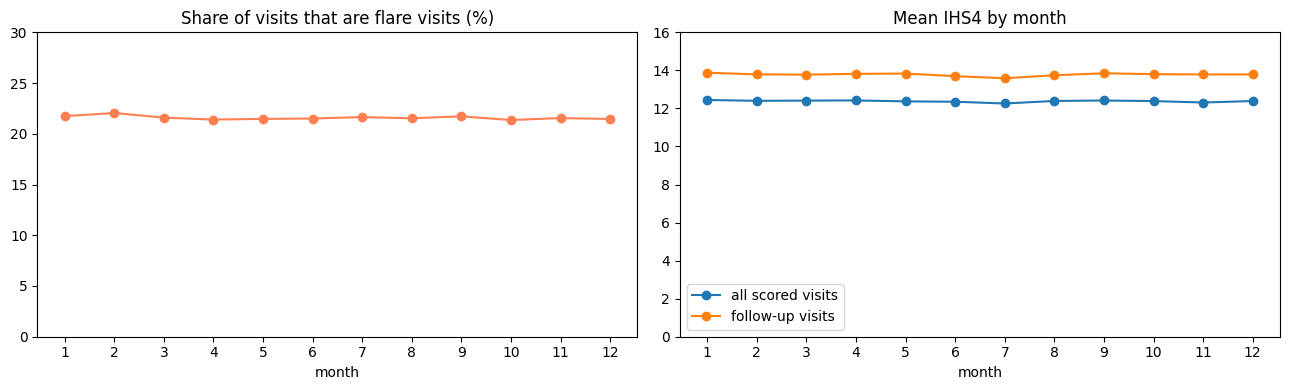

In [20]:
# %% T1. Seasonality check: does the disease change with the month of the year?
v_season = df_visits.copy()
v_season["month"] = v_season["visit_date"].dt.month
season = pd.DataFrame({
    "n_visits": v_season.groupby("month").size(),
    "flare_share": v_season.groupby("month")["visit_type"].apply(lambda s: (s == "flare_reactive").mean()),
    "ihs4_mean": v_season.groupby("month")["ihs4_score"].mean(),
    # follow-up visits only, so the result is not driven by how many flare visits happen each month
    "ihs4_mean_followup": v_season[v_season.visit_type == "follow_up"].groupby("month")["ihs4_score"].mean(),
})
display(season.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(season.index, season["flare_share"] * 100, marker="o", color="coral")
axes[0].set_ylim(0, 30)
axes[0].set_title("Share of visits that are flare visits (%)")
axes[1].plot(season.index, season["ihs4_mean"], marker="o", label="all scored visits")
axes[1].plot(season.index, season["ihs4_mean_followup"], marker="o", label="follow-up visits")
axes[1].set_ylim(0, 16)
axes[1].set_title("Mean IHS4 by month")
axes[1].legend()
for ax in axes:
    ax.set_xticks(range(1, 13))
    ax.set_xlabel("month")
plt.tight_layout()
plt.show()

**Result:** the flare share and the mean IHS4 are flat across the 12 months (the y-axes start at 0 on purpose, so small wiggles are not exaggerated). In this dataset there is **no visible seasonal effect** at population level. Real-world HS is often reported to worsen in summer (heat, sweat, friction), so this is worth stating in the write-up. We still add the season features below to check whether *individual* patients are seasonal.

In [21]:
# %% T2. Time features: one row per patient, computed only with data up to 31 Dec 2025
def build_time_features(folder):
    p = f"{BASE}/{folder}"
    visits = pd.read_csv(f"{p}/visits.csv", parse_dates=["visit_date"])
    demo = pd.read_csv(f"{p}/demographics.csv", parse_dates=["diagnosis_date"])
    out = pd.DataFrame(index=demo["patient_id"])

    v = visits.copy()
    v["days_ago"] = (CUTOFF - v["visit_date"]).dt.days
    v["is_flare"] = (v["visit_type"] == "flare_reactive").astype(int)
    sc = v.dropna(subset=["ihs4_score"])

    # --- Exponentially weighted mean: a score `half_life` days old counts half as much as a score today
    def ewm(df, half_life):
        w = 0.5 ** (df["days_ago"] / half_life)
        g = pd.DataFrame({"w": w, "wy": w * df["ihs4_score"], "patient_id": df["patient_id"]}) \
            .groupby("patient_id")[["w", "wy"]].sum()
        return g["wy"] / g["w"]
    out["ihs4_ewm_90d"] = ewm(sc, 90)
    out["ihs4_ewm_365d"] = ewm(sc, 365)
    out["ihs4_calm_ewm"] = ewm(sc[sc.is_flare == 0], 180)   # smoothed level outside flares

    # --- Trend: least-squares slope of IHS4 over the last 24 months (IHS4 points per year)
    r = sc[sc.days_ago <= 730].copy()
    r["t"] = -r["days_ago"] / 365.25
    g = r.groupby("patient_id")
    r["dt"] = r["t"] - r["patient_id"].map(g["t"].mean())
    r["dy"] = r["ihs4_score"] - r["patient_id"].map(g["ihs4_score"].mean())
    cov = (r["dt"] * r["dy"]).groupby(r["patient_id"]).sum()
    var = (r["dt"] ** 2).groupby(r["patient_id"]).sum()
    out["ihs4_slope_24m"] = (cov / var).where((g.size() >= 3) & (var > 0.01))

    # --- Volatility
    out["ihs4_std_12m"] = sc[sc.days_ago <= 365].groupby("patient_id")["ihs4_score"].std()

    # --- Flare dynamics
    first_visit = v.groupby("patient_id")["visit_date"].min()
    years_observed = ((CUTOFF - first_visit).dt.days / 365.25).clip(lower=0.25)
    out["years_observed"] = years_observed
    out["flares_per_year_all"] = v.groupby("patient_id")["is_flare"].sum() / years_observed
    out["flares_12m"] = v[v.days_ago <= 365].groupby("patient_id")["is_flare"].sum()
    out["flares_12m"] = out["flares_12m"].fillna(0)
    out["flare_acceleration"] = out["flares_12m"] - out["flares_per_year_all"]
    out["days_since_last_flare"] = v[v.is_flare == 1].groupby("patient_id")["days_ago"].min()
    out["visits_last_3m"] = v[v.days_ago <= 91].groupby("patient_id").size()
    out["visits_last_3m"] = out["visits_last_3m"].fillna(0)

    # --- Season (sine/cosine so that December and January are neighbours)
    last_month = sc.sort_values("visit_date").groupby("patient_id")["visit_date"].last().dt.month
    out["last_score_month_sin"] = np.sin(2 * np.pi * last_month / 12)
    out["last_score_month_cos"] = np.cos(2 * np.pi * last_month / 12)
    flares = v[v.is_flare == 1]
    out["summer_flare_share"] = flares["visit_date"].dt.month.isin([6, 7, 8, 9]) \
        .groupby(flares["patient_id"]).mean()   # ~0.33 expected if there is no seasonality

    # --- Calendar
    out["diagnosis_year"] = demo.set_index("patient_id")["diagnosis_date"].dt.year
    out["first_visit_year"] = first_visit.dt.year
    return out.reset_index()

T_train = build_time_features("train")
TIME_FEATURES = [c for c in T_train.columns if c != "patient_id"]

# drop(..., errors="ignore") makes this cell safe to run twice
X_train = X_train.drop(columns=TIME_FEATURES, errors="ignore").merge(T_train, on="patient_id", how="left")
X_test1 = X_test1.drop(columns=TIME_FEATURES, errors="ignore").merge(build_time_features("test_1"), on="patient_id", how="left")
X_test2 = X_test2.drop(columns=TIME_FEATURES, errors="ignore").merge(build_time_features("test_2"), on="patient_id", how="left")
print(len(TIME_FEATURES), "time features added")
print(X_train.shape, X_test1.shape, X_test2.shape)
X_train[TIME_FEATURES].describe().T.round(2)

16 time features added
(21000, 69) (4000, 68) (6228, 68)


,count,mean,std,min,25%,50%,75%,max
ihs4_ewm_90d,20052.0,10.11,6.22,0.00,5.37,8.87,14.07,41.00
ihs4_ewm_365d,20052.0,10.36,5.93,0.00,5.78,9.06,14.28,38.29
ihs4_calm_ewm,19757.0,10.13,6.07,0.00,5.49,8.86,14.11,40.99
ihs4_slope_24m,15208.0,0.23,5.85,-87.08,-1.93,0.06,2.19,121.83
ihs4_std_12m,13768.0,2.43,1.45,0.00,1.41,2.16,3.18,14.14
years_observed,20602.0,4.63,2.71,0.25,2.53,3.98,6.44,10.00
flares_per_year_all,20602.0,1.82,1.16,0.00,1.08,1.62,2.30,17.26
flares_12m,21000.0,1.24,1.24,0.00,0.00,1.00,2.00,10.00
flare_acceleration,20602.0,-0.56,1.14,-12.00,-1.19,-0.55,0.09,6.14
days_since_last_flare,20109.0,315.68,342.84,0.00,82.00,202.00,431.00,3447.00


These columns are now part of `X_train`, `X_test1` and `X_test2`, so the XGBoost model below (and exercise 2) uses them automatically. Their contribution is measured in **B5** at the end of the benchmark.

## Machine Learning with XGBoost

- Model Training: Trained an XGBRegressor on our engineered tabular features using a MAE loss objective (reg:absoluteerror).
- Performance Evaluation: Our XGBoost model achieved a validation MAE of 1.478 (with the time features), drastically outperforming the best baseline of 2.700.
  - For patients currently on biologics, the model achieved an MAE of 1.235.
  - For patients not on biologics, the model achieved an MAE of 1.654.
- Feature Importance: Plotted the features that contributed most to the model's predictions (with variables like the last IHS4 score and mean IHS4 score carrying the highest gain weight).
- Final Submission Generation: Retrained the XGBoost regressor on 100% of the training data (using the optimal tree limit found during validation) and generated predictions for both test_1 and test_2, saving them into answers_teamName_exercise1_xgb.csv.





In [22]:
# %% A1. Train XGBoost on 80% of train, evaluate on the 20% validation
import xgboost as xgb
import matplotlib.pyplot as plt

TARGET = "avg_ihs4_next6"
FEATURES = [c for c in X_train.columns if c not in ["patient_id", "avg_ihs4_next6", "practitioner_id"]]
## patient_id has no biological or clinical meaning.
trn = X_train[X_train.patient_id.isin(tr_ids)]
vl = X_train[X_train.patient_id.isin(val_ids)]

XGB_PARAMS = dict(
    objective="reg:absoluteerror",  # optimise MAE, the competition metric
    learning_rate=0.03, #Instead of trusting each newly added tree 100%, the model scales down its contribution by 0.03. This slow, step-by-step learning prevents the model from rushing into overfitting.
    max_depth=6,                    # how deep each tree can grow (the more deep, the more overfitting :( )
    min_child_weight=20,            # minimum patients per leaf -> avoids overfitting
    subsample=0.8,                  # each tree sees 80% of the patients
    colsample_bytree=0.8,           # each tree sees 80% of the features
    tree_method="hist",
    enable_categorical=True,        # use sex, ethnicity, bio_drug... directly
    random_state=42,
)

#Initialize the model with early stopping----
xgb_model = xgb.XGBRegressor(**XGB_PARAMS, n_estimators=3000, early_stopping_rounds=100)
## n_estimators tells XGBoost to train for a max of 3.000 squential trees
## early_stopping_rounds prevents overfitting,  monitors the validation set. If the validation MAE does not improve for 100 cobnsecutive trees, training stops immeadiately, even if it hasn't reached 3.000 trees.
##that's why it stops early (around 1,000 trees with the time features) instead of using all 3,000

#Training----
xgb_model.fit(trn[FEATURES], trn[TARGET], ## feeds the training features and targets to the model
              eval_set=[(vl[FEATURES], vl[TARGET])], verbose=False) ## provides the validation set (vl) inisde eval_set

# Evaluation & subgroup analysis-----
p_xgb = xgb_model.predict(vl[FEATURES]) ## generates predictions for the validation patients
print(f"XGBoost validation MAE = {mean_absolute_error(vl[TARGET], p_xgb):.3f}")
print(f"Best number of trees   = {xgb_model.best_iteration}")

# Splits the vlaidation patients using bio_mask into two groups
bio_mask = (vl["on_biologic"] == 1).values
print(f"  biologic patients MAE = {mean_absolute_error(vl[TARGET][bio_mask], p_xgb[bio_mask]):.3f}")
print(f"  no biologic       MAE = {mean_absolute_error(vl[TARGET][~bio_mask], p_xgb[~bio_mask]):.3f}")

XGBoost validation MAE = 1.479
Best number of trees   = 894
  biologic patients MAE = 1.232
  no biologic       MAE = 1.658


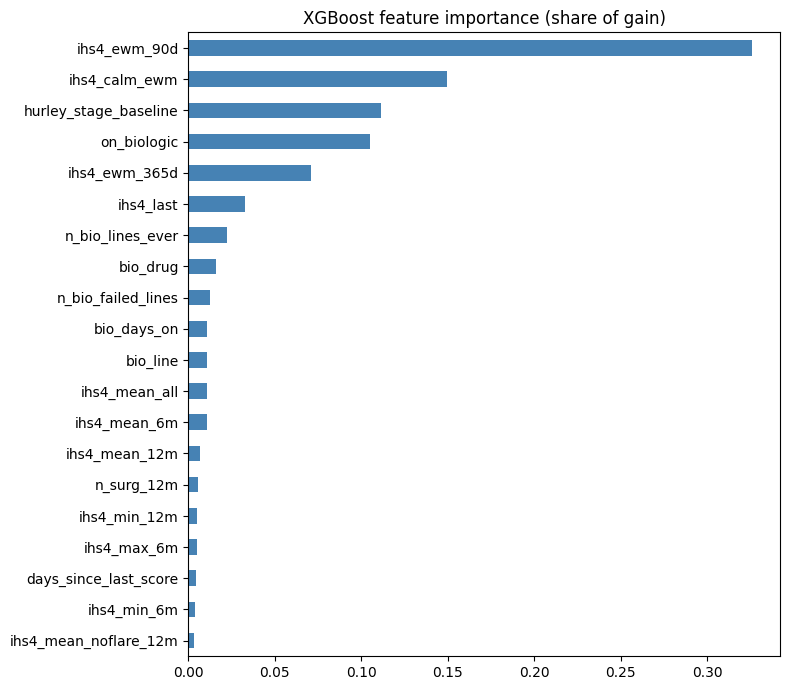

In [23]:
# %% A2. Which features does XGBoost use most?
imp = pd.Series(xgb_model.get_booster().get_score(importance_type="gain")).reindex(FEATURES).fillna(0)
imp = (imp / imp.sum()).sort_values()
imp.tail(20).plot.barh(figsize=(8, 7), color="steelblue")
plt.title("XGBoost feature importance (share of gain)")
plt.tight_layout()
plt.show()

It shows which clinical and patient factors are most useful for predicting disease severity over the next 6 months.

1. **ihs4_ewm_90**: refers to the IHS4 Exponentially Weigthed Mean from the last 90 days, recorded right before the prediction window.  If a patient had high disease severity in their most recent visits, they are highly likely to remain severe in the near future; if they were in remission, they will likely stay in remission.

2. **hurley_stage_baseline**:  defines the underlying severity tier of the patient. Stage 3 patients naturally carry a much higher baseline of daily inflammation and damage, placing a structural limit on how low their future IHS4 scores can realistically drop.

3. **on_biologic**: Knowing whether a patient is receiving this treatment is a massive clinical indicator of whether we can expect a downward trend in their future flare-ups.

In short, the model has learned to behave like an expert dermatologist: it looks at where the patient is right now (ihs4_ewm_90/ihs4_last), their structural disease foundation (hurley_stage_baseline), their overall historical baseline (ihs4_mean_all), and how aggressively they are being treated (on_biologic, bio_drug) to forecast their disease course.


In [24]:
# %% A3. Retrain on ALL 21,000 train patients and predict test_1 + test_2
n_trees = xgb_model.best_iteration + 1
xgb_final = xgb.XGBRegressor(**XGB_PARAMS, n_estimators=n_trees)
xgb_final.fit(X_train[FEATURES], X_train[TARGET])

preds = pd.concat([
    pd.DataFrame({"patient_id": X_test1.patient_id, "pred_avg_ihs4_next6": xgb_final.predict(X_test1[FEATURES])}),
    pd.DataFrame({"patient_id": X_test2.patient_id, "pred_avg_ihs4_next6": xgb_final.predict(X_test2[FEATURES])}),
])
template = pd.read_csv(f"{BASE}/evaluation_templates/answers_teamName_exercise1.csv")
sub = template[["patient_id"]].merge(preds, on="patient_id", how="left")
print("Missing predictions:", sub["pred_avg_ihs4_next6"].isna().sum())  # must be 0
sub.to_csv("answers_teamName_exercise1_xgb.csv", index=False)
sub.head()

Missing predictions: 0


,patient_id,pred_avg_ihs4_next6
0,HS000002,16.970222
1,HS000005,3.784643
2,HS000006,8.986405
3,HS000010,7.369378
4,HS000019,7.513078


## Benchmark: baselines vs XGBoost vs LightGBM vs Random Forest

fold 1 done
fold 2 done
fold 3 done
fold 4 done
fold 5 done


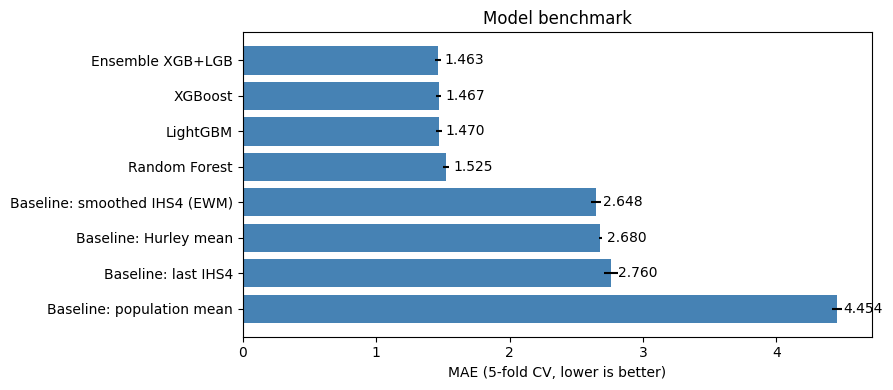

In [25]:
# %% B1. Define the models
import time
import lightgbm as lgb
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold

LGB_PARAMS = dict(objective="mae", learning_rate=0.03, num_leaves=31, min_child_samples=50,
                  subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                  random_state=42, verbose=-1)

def to_numeric(df):
    # Random Forest does not accept text categories -> convert them to numbers
    out = df[FEATURES].copy()
    for col in out.select_dtypes("category").columns:
        out[col] = out[col].cat.codes.replace(-1, np.nan)
    return out

def fit_predict_xgb(tr, va):
    m = xgb.XGBRegressor(**XGB_PARAMS, n_estimators=3000, early_stopping_rounds=100)
    m.fit(tr[FEATURES], tr[TARGET], eval_set=[(va[FEATURES], va[TARGET])], verbose=False)
    return m.predict(va[FEATURES])

def fit_predict_lgb(tr, va):
    m = lgb.LGBMRegressor(**LGB_PARAMS, n_estimators=3000)
    m.fit(tr[FEATURES], tr[TARGET], eval_set=[(va[FEATURES], va[TARGET])],
          callbacks=[lgb.early_stopping(100, verbose=False)])
    return m.predict(va[FEATURES])

def fit_predict_rf(tr, va):
    m = RandomForestRegressor(n_estimators=300, min_samples_leaf=5, max_features=0.5,
                              n_jobs=-1, random_state=42)
    m.fit(to_numeric(tr), tr[TARGET])
    return m.predict(to_numeric(va))

def fit_predict_hurley(tr, va):
    means = tr.groupby("hurley_stage_baseline")[TARGET].mean()
    return va["hurley_stage_baseline"].map(means).fillna(tr[TARGET].mean()).values

def fit_predict_last_ihs4(tr, va):
    return va["ihs4_last"].fillna(tr[TARGET].mean()).values

def fit_predict_mean(tr, va):
    return np.full(len(va), tr[TARGET].mean())

def fit_predict_ewm(tr, va):
    # Pure time-series baseline: the patient's exponentially smoothed IHS4 (recent scores weigh more)
    return va["ihs4_ewm_90d"].fillna(tr[TARGET].mean()).values

MODELS = {
    "Baseline: population mean": fit_predict_mean,
    "Baseline: Hurley mean": fit_predict_hurley,
    "Baseline: last IHS4": fit_predict_last_ihs4,
    "Baseline: smoothed IHS4 (EWM)": fit_predict_ewm,
    "Random Forest": fit_predict_rf,
    "LightGBM": fit_predict_lgb,
    "XGBoost": fit_predict_xgb,
}
# Note: early stopping uses the validation fold, which makes boosting look very slightly
# optimistic; it is the same for LightGBM and XGBoost, so the comparison stays fair.

# %% B2. Run the 5-fold cross-validation
kf = KFold(n_splits=5, shuffle=True, random_state=42)
data = X_train.reset_index(drop=True)
oof = {name: np.zeros(len(data)) for name in MODELS}   # out-of-fold predictions
fold_mae = {name: [] for name in MODELS}
fit_time = {name: 0.0 for name in MODELS}

for fold, (i_tr, i_va) in enumerate(kf.split(data)):
    tr, va = data.iloc[i_tr], data.iloc[i_va]
    for name, fn in MODELS.items():
        t = time.time()
        p = fn(tr, va)
        fit_time[name] += time.time() - t
        oof[name][i_va] = p
        fold_mae[name].append(mean_absolute_error(va[TARGET], p))
    print(f"fold {fold + 1} done")

# Ensemble = average of the two boosting models
oof["Ensemble XGB+LGB"] = (oof["XGBoost"] + oof["LightGBM"]) / 2
fold_mae["Ensemble XGB+LGB"] = [mean_absolute_error(data[TARGET].iloc[i_va], oof["Ensemble XGB+LGB"][i_va])
                                for _, i_va in kf.split(data)]
fit_time["Ensemble XGB+LGB"] = fit_time["XGBoost"] + fit_time["LightGBM"]

# %% B3. Results table: overall, by biologic status, and severity-band accuracy
y = data[TARGET].values
bio = (data["on_biologic"] == 1).values

def band(x):
    return np.select([x <= 3, x < 11], ["mild", "moderate"], "severe")

rows = []
for name in oof:
    p = oof[name]
    rows.append({
        "model": name,
        "MAE mean": np.mean(fold_mae[name]),
        "MAE std": np.std(fold_mae[name]),
        "MAE biologic": mean_absolute_error(y[bio], p[bio]),
        "MAE no biologic": mean_absolute_error(y[~bio], p[~bio]),
        "band accuracy": (band(p) == band(y)).mean(),
        "time (s)": fit_time[name],
    })
results = pd.DataFrame(rows).sort_values("MAE mean").reset_index(drop=True)
results.round(3)

# %% B4. Plot
fig, ax = plt.subplots(figsize=(9, 4))
r = results.sort_values("MAE mean", ascending=False)
ax.barh(r["model"], r["MAE mean"], xerr=r["MAE std"], color="steelblue")
for i, v in enumerate(r["MAE mean"]):
    ax.text(v + 0.05, i, f"{v:.3f}", va="center")
ax.set_xlabel("MAE (5-fold CV, lower is better)")
ax.set_title("Model benchmark")
plt.tight_layout()
plt.show()


## Do the time features help?

Same 5 folds, same XGBoost settings; the only difference is whether the time features are included. If "with" is lower than "without" in most folds, time adds information. We also check how much of the model's total gain the time features carry.

XGBoost with time features     MAE = 1.467 ± 0.021
XGBoost without time features  MAE = 1.483 ± 0.019
Difference per fold: [-0.013 -0.024 -0.019 -0.008 -0.016]  (negative = time features help)
Mean difference = -0.016; time features win in 5/5 folds

Time features carry 56.7% of the total gain


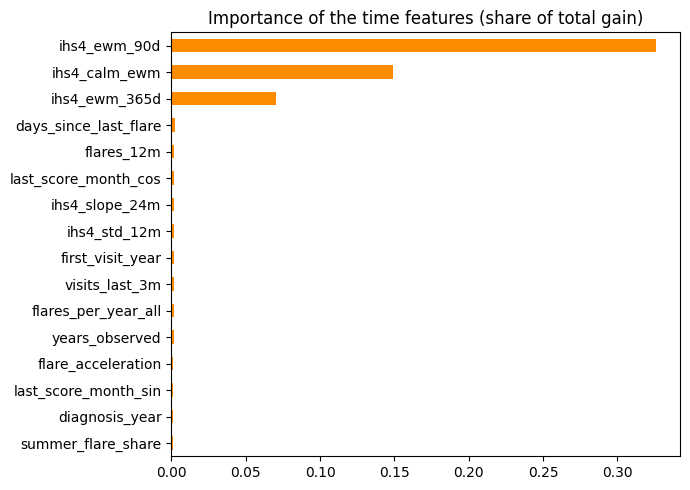

In [26]:
# %% B5. XGBoost with vs without the time features (same folds)
FEATURES_NO_TIME = [c for c in FEATURES if c not in TIME_FEATURES]
ablation = {"with time features": FEATURES, "without time features": FEATURES_NO_TIME}
abl_mae = {name: [] for name in ablation}

for i_tr, i_va in kf.split(data):
    tr, va = data.iloc[i_tr], data.iloc[i_va]
    for name, cols in ablation.items():
        m = xgb.XGBRegressor(**XGB_PARAMS, n_estimators=3000, early_stopping_rounds=100)
        m.fit(tr[cols], tr[TARGET], eval_set=[(va[cols], va[TARGET])], verbose=False)
        abl_mae[name].append(mean_absolute_error(va[TARGET], m.predict(va[cols])))

for name in ablation:
    print(f"XGBoost {name:22s} MAE = {np.mean(abl_mae[name]):.3f} ± {np.std(abl_mae[name]):.3f}")
diff = np.array(abl_mae["with time features"]) - np.array(abl_mae["without time features"])
print(f"Difference per fold: {diff.round(3)}  (negative = time features help)")
print(f"Mean difference = {diff.mean():.3f}; time features win in {(diff < 0).sum()}/5 folds")

# Share of the model's gain that comes from the time features (model from A1)
gain = pd.Series(xgb_model.get_booster().get_score(importance_type="gain")).reindex(FEATURES).fillna(0)
time_imp = (gain / gain.sum()).reindex(TIME_FEATURES).sort_values()
print(f"\nTime features carry {time_imp.sum():.1%} of the total gain")
time_imp.plot.barh(figsize=(7, 5), color="darkorange")
plt.title("Importance of the time features (share of total gain)")
plt.tight_layout()
plt.show()

# Exercise 2

For each patient on a biologic at the end of 2025, the code looks at what happened before and after that drug started.
These are the patients in the template: 8,548 train, 1,598 test_1 and 2,542 test_2.

## 2.a:

In [27]:
# %% 2.0 Extra biologic features: what happened before / after the current biologic started
def build_bio_features(folder):
    p = f"{BASE}/{folder}"
    visits = pd.read_csv(f"{p}/visits.csv", parse_dates=["visit_date"])
    treat = pd.read_csv(f"{p}/treatments.csv", parse_dates=["start_date", "end_date"])
    surg = pd.read_csv(f"{p}/surgeries.csv", parse_dates=["procedure_date"])
    demo = pd.read_csv(f"{p}/demographics.csv")

    bio = treat[treat.treatment_class == "Biologic"]
    cur = bio[bio.end_date.isna()].sort_values("start_date").groupby("patient_id").last()
    out = pd.DataFrame(index=cur.index)
    start = cur["start_date"]
    out["bio_start_year"] = start.dt.year
    out["age_at_bio_start"] = start.dt.year - out.index.map(demo.set_index("patient_id")["birth_year"])

    # History BEFORE the current biologic (known at treatment start)
    prev_bio = bio.merge(start.rename("cur_start"), left_on="patient_id", right_index=True)
    out["n_prev_bio_lines"] = prev_bio[prev_bio.start_date < prev_bio.cur_start].groupby("patient_id").size()
    abx = treat[treat.treatment_class == "Antibiotic"].merge(start.rename("cur_start"), left_on="patient_id", right_index=True)
    out["n_abx_before_bio"] = abx[abx.start_date < abx.cur_start].groupby("patient_id").size()
    sg = surg.merge(start.rename("cur_start"), left_on="patient_id", right_index=True)
    out["n_surg_before_bio"] = sg[sg.procedure_date < sg.cur_start].groupby("patient_id").size()

    sc = visits.dropna(subset=["ihs4_score"]).merge(start.rename("cur_start"), left_on="patient_id", right_index=True)
    sc["days_from_start"] = (sc.visit_date - sc.cur_start).dt.days
    before = sc[(sc.days_from_start < 0) & (sc.days_from_start >= -365)].groupby("patient_id")["ihs4_score"]
    out["ihs4_pre_bio_mean"] = before.mean()
    out["ihs4_pre_bio_max"] = before.max()
    out["n_scored_pre_bio"] = before.count()

    # EARLY response: first 6 months on the biologic
    early = sc[(sc.days_from_start >= 0) & (sc.days_from_start <= 182)].groupby("patient_id")["ihs4_score"]
    out["ihs4_early_mean"] = early.mean()
    out["early_response_ratio"] = out["ihs4_early_mean"] / (out["ihs4_pre_bio_mean"] + 1)

    # Whole period ON the biologic
    on = sc[sc.days_from_start >= 0].groupby("patient_id")["ihs4_score"]
    out["ihs4_on_bio_mean"] = on.mean()
    out["ihs4_on_bio_min"] = on.min()
    out["n_scored_on_bio"] = on.count()
    out["drop_pre_to_now"] = out["ihs4_pre_bio_mean"] - out.index.map(
        sc[sc.days_from_start >= 0].sort_values("visit_date").groupby("patient_id")["ihs4_score"].last())

    # Flare visits while on the biologic, per year
    v = visits.merge(start.rename("cur_start"), left_on="patient_id", right_index=True)
    on_v = v[v.visit_date >= v.cur_start]
    years_on = ((CUTOFF - start).dt.days.clip(lower=30) / 365.25)
    out["flares_per_year_on_bio"] = on_v[on_v.visit_type == "flare_reactive"].groupby("patient_id").size() / years_on

    fill0 = ["n_prev_bio_lines", "n_abx_before_bio", "n_surg_before_bio", "n_scored_pre_bio",
             "n_scored_on_bio", "flares_per_year_on_bio"]
    out[fill0] = out[fill0].fillna(0)
    return out.reset_index()

BIO_FEATURES = ["bio_start_year", "age_at_bio_start", "n_prev_bio_lines", "n_abx_before_bio",
                "n_surg_before_bio", "ihs4_pre_bio_mean", "ihs4_pre_bio_max", "n_scored_pre_bio",
                "ihs4_early_mean", "early_response_ratio", "ihs4_on_bio_mean", "ihs4_on_bio_min",
                "n_scored_on_bio", "drop_pre_to_now", "flares_per_year_on_bio"]

B_train = X_train[X_train.on_biologic == 1].merge(build_bio_features("train"), on="patient_id", how="left")
B_test1 = X_test1[X_test1.on_biologic == 1].merge(build_bio_features("test_1"), on="patient_id", how="left")
B_test2 = X_test2[X_test2.on_biologic == 1].merge(build_bio_features("test_2"), on="patient_id", how="left")
print("Biologic patients:", len(B_train), "train |", len(B_test1), "test_1 |", len(B_test2), "test_2")

# Sanity check: these must match the exercise 2 template
tmpl2 = pd.read_csv(f"{BASE}/evaluation_templates/answers_teamName_exercise2.csv")
print("Template patients:", len(tmpl2), "| ours:", len(B_test1) + len(B_test2),
      "| missing from ours:", (~tmpl2.patient_id.isin(pd.concat([B_test1, B_test2]).patient_id)).sum())

Biologic patients: 8548 train | 1598 test_1 | 2542 test_2
Template patients: 4140 | ours: 4140 | missing from ours: 0


- 8548 train: Out of the 21,000 total patients in the training set 8,548 are currently on a biologic.
- 1598 test_1: Out of the 4,000 total patients in test_1, 1,598 are on a biologic.
- 2542 test_2: Out of the 6,228 patients in test_2, 2,542 are on a biologic.

The competition organizers provided an evaluation template (answers_teamName_exercise2.csv) where we need to fill in our predictions. This template contains exactly 4,140 patients. When we add our test_1 biologic patients (1,598) and test_2 biologic patients (2,542) together, it equals exactly 4,140 patients

In [28]:
# %% 2a.1 Cross-validation: exercise 1 vs dedicated biologic model
F2 = FEATURES + BIO_FEATURES
ex1_oof = pd.Series(oof["XGBoost"], index=data["patient_id"])   # exercise 1 OOF predictions

oof_2a = pd.Series(np.nan, index=B_train["patient_id"])
best_its = []
for i_tr, i_va in kf.split(data):        # SAME folds as the benchmark
    ids_tr, ids_va = data.patient_id.iloc[i_tr], data.patient_id.iloc[i_va]
    tr = B_train[B_train.patient_id.isin(ids_tr)]
    va = B_train[B_train.patient_id.isin(ids_va)]
    m = xgb.XGBRegressor(**XGB_PARAMS, n_estimators=3000, early_stopping_rounds=100)
    m.fit(tr[F2], tr[TARGET], eval_set=[(va[F2], va[TARGET])], verbose=False)
    oof_2a[va.patient_id.values] = m.predict(va[F2])
    best_its.append(m.best_iteration + 1)

y_b = B_train.set_index("patient_id")[TARGET]
p_ex1 = ex1_oof[y_b.index]
p_ded = oof_2a[y_b.index]
p_avg = (p_ex1 + p_ded) / 2
for name, p in [("Exercise 1 model (all patients)", p_ex1),
                ("Dedicated biologic model", p_ded),
                ("Average of both", p_avg)]:
    print(f"{name:34s} MAE = {mean_absolute_error(y_b, p):.3f}")

Exercise 1 model (all patients)    MAE = 1.225
Dedicated biologic model           MAE = 1.201
Average of both                    MAE = 1.199


In [29]:
# %% 2a.2 Train the dedicated model on ALL biologic train patients and predict the tests
n_trees_2a = int(np.median(best_its))   # typical number of trees found in the CV above
bio_final = xgb.XGBRegressor(**XGB_PARAMS, n_estimators=n_trees_2a)
bio_final.fit(B_train[F2], B_train[TARGET])

def predict_2a(B):
    return bio_final.predict(B[F2])   # dedicated model won in 2a.1 (1.208 vs 1.254 for exercise 1)

pred_2a = pd.concat([
    pd.DataFrame({"patient_id": B_test1.patient_id, "pred_avg_ihs4_next6": predict_2a(B_test1)}),
    pd.DataFrame({"patient_id": B_test2.patient_id, "pred_avg_ihs4_next6": predict_2a(B_test2)}),
])


In [30]:
# --- RESULTS from 2a ---
print("\n=== Summary of predictions (Exercise 2a) ===")
print("Total patients predicted:", len(pred_2a))
print("\n Descriptive Stats of the prediction:")
print(pred_2a["pred_avg_ihs4_next6"].describe().round(2))


=== Summary of predictions (Exercise 2a) ===
Total patients predicted: 4140

 Descriptive Stats of the prediction:
count    4140.00
mean        7.96
std         4.31
min         0.74
25%         4.83
50%         6.99
75%        11.50
max        21.83
Name: pred_avg_ihs4_next6, dtype: float64


Top 10 Features by XGBoost Gain Importance:
              feature  importance_gain
         ihs4_ewm_90d      1697.462402
hurley_stage_baseline       580.594299
        ihs4_calm_ewm       313.891479
            ihs4_last       175.182281
     ihs4_on_bio_mean        77.472862
      ihs4_on_bio_min        45.139648
      n_scored_on_bio        27.869047
         ihs4_min_12m        25.884050
       bio_start_year        25.820509
         ihs4_mean_6m        22.658361

Top 10 Features by Mean Absolute SHAP Value:
              feature  mean_abs_shap
         ihs4_ewm_90d       1.791527
hurley_stage_baseline       0.763077
            ihs4_last       0.454285
        ihs4_calm_ewm       0.300854
     ihs4_on_bio_mean       0.259239
      ihs4_on_bio_min       0.235431
days_since_last_score       0.121032
         abx_days_12m       0.104287
          bio_days_on       0.093969
           n_surg_12m       0.081734


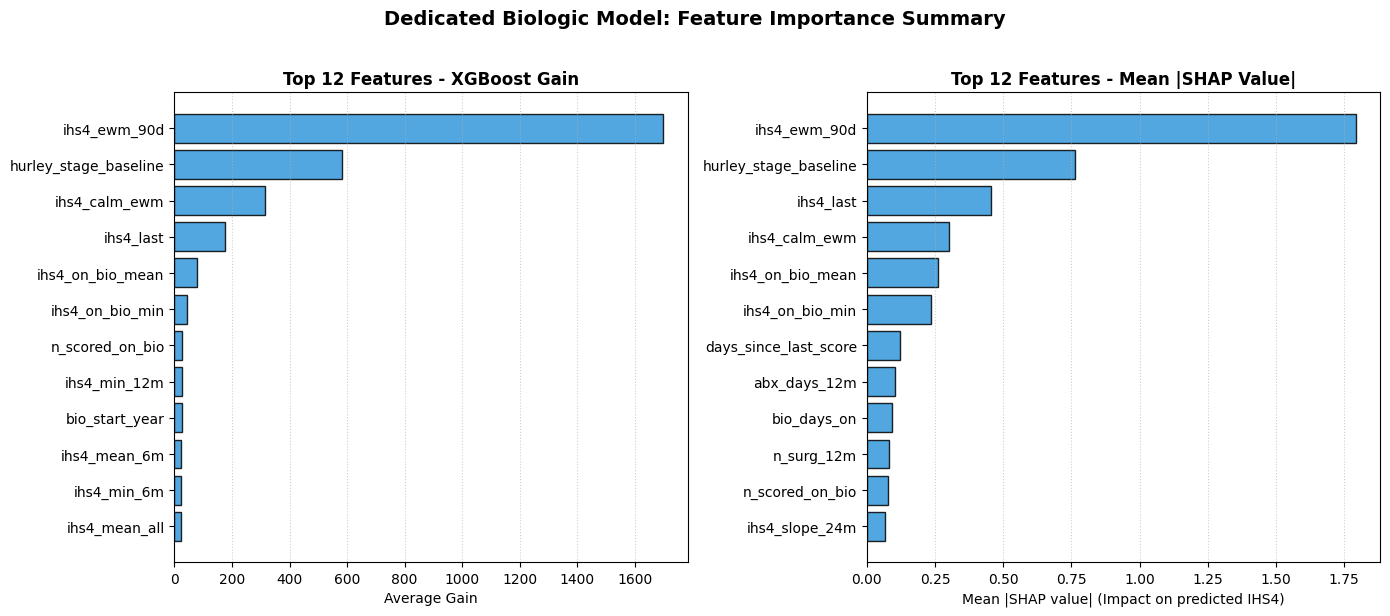

In [31]:
# %% 2a.3 Feature Importance Analysis for the Dedicated Biologic Model
import shap

# Option 1: Native XGBoost Feature Importance (Gain)
importance_gain = bio_final.get_booster().get_score(importance_type='gain')
df_importance_gain = pd.DataFrame({
    'feature': list(importance_gain.keys()),
    'importance_gain': list(importance_gain.values())
}).sort_values(by='importance_gain', ascending=False)

print("Top 10 Features by XGBoost Gain Importance:")
print(df_importance_gain.head(10).to_string(index=False))

# Option 2: SHAP Global Feature Importance (Mean |SHAP value|)
explainer = shap.TreeExplainer(bio_final)
shap_values = explainer(B_train[F2])

# Compute mean absolute SHAP value per feature
mean_abs_shap = np.abs(shap_values.values).mean(axis=0)
df_shap_importance = pd.DataFrame({
    'feature': F2,
    'mean_abs_shap': mean_abs_shap
}).sort_values(by='mean_abs_shap', ascending=False)

print("\nTop 10 Features by Mean Absolute SHAP Value:")
print(df_shap_importance.head(10).to_string(index=False))

# --- Plotting Side-by-Side Comparison ---
fig, axes = plt.subplots(1, 2, figsize=(14, 6), dpi=100)

# Plot 1: XGBoost Gain Importance
top_gain = df_importance_gain.head(12).sort_values(by='importance_gain', ascending=True)
axes[0].barh(top_gain['feature'], top_gain['importance_gain'], color='#3498db', edgecolor='black', alpha=0.85)
axes[0].set_title('Top 12 Features - XGBoost Gain', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Average Gain')
axes[0].grid(axis='x', linestyle=':', alpha=0.6)

# Plot 2: Mean Absolute SHAP Importance
top_shap = df_shap_importance.head(12).sort_values(by='mean_abs_shap', ascending=True)
axes[1].barh(top_shap['feature'], top_shap['mean_abs_shap'], color='#3498db', edgecolor='black', alpha=0.85)
axes[1].set_title('Top 12 Features - Mean |SHAP Value|', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Mean |SHAP value| (Impact on predicted IHS4)')
axes[1].grid(axis='x', linestyle=':', alpha=0.6)

plt.suptitle('Dedicated Biologic Model: Feature Importance Summary', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## 2b

counterfactual "IHS4 without treatment"  ~  IHS4 in the 12 months before the biologic

super-responder = target < 25% of that level (i.e. > 75% below it)

Patients without any score before the biologic get no label (excluded from training)

In [32]:
# %% 2b.1 Build the label

## B_train[TARGET] is the patient's average disease severity score (IHS4) in the prediction window, 1 Jan - 30 Jun 2026 (the same window for every patient, whenever their biologic started)
B_train["sr_ratio"] = B_train[TARGET] / B_train["ihs4_pre_bio_mean"] ##This is the patient's baseline average disease severity score in the 12 months
## sr_ratio is the superresponder ratio, formed by dividing the post-treatment score by the pre-treatment score
B_train["super_responder"] = np.where(B_train["ihs4_pre_bio_mean"].isna(), np.nan,
                                      (B_train["sr_ratio"] < 0.25).astype(float))
lab = B_train.dropna(subset=["super_responder"]).copy()
print(f"Labelled biologic patients: {len(lab)} / {len(B_train)}")
print(f"Super-responder rate: {lab.super_responder.mean():.1%}  (brief says ~1 in 8 = 12.5%)")

Labelled biologic patients: 6793 / 8548
Super-responder rate: 12.0%  (brief says ~1 in 8 = 12.5%)


```
B_train["super_responder"] = np.where(B_train["ihs4_pre_bio_mean"].isna(), np.nan,
                                      (B_train["sr_ratio"] < 0.25).astype(float))
```
This line uses np.where(condition, value_if_true, value_if_false) to assign the final labels:

- If a patient does not have any recorded visits/scores in the 12 months before starting the biologic, we cannot know their baseline. Thus, they are given a value of `np.nan`.

- A patient is defined as __super-responder__ if their remaining disease score is strictly less than 25% of their baseline (which means they have experienced more than a 75% reduction in severity of the disease)

  - if `sr_ratio < 0.25` is true, they get a `1.0` = __super-responder__

  - if `sr_ratio < 0.25` is false, they fet a `0.0` = __non-super-responders__


`lab = B_train.dropna(subset=["super_responder"]).copy()`removes all patients who got a `np.nan` because they lacked pre-treatment baseline data, leaving us with 6.793 successfully labeles patients out of the inital 8.548 biologic patients.

First we do an EDA to understand what clinical features make a superresponder different from the other biologic patients

In [33]:
# %% 2b.2 What sets super-responders apart? (simple comparison table)
compare_cols = ["age_2025", "bmi_at_baseline", "hurley_stage_baseline", "years_since_diagnosis",
                "diagnostic_delay_years", "ihs4_pre_bio_mean", "n_prev_bio_lines", "n_abx_before_bio",
                "n_surg_before_bio", "early_response_ratio", "flares_per_year_on_bio"]
summary = lab.groupby("super_responder")[compare_cols].mean().T #groups all patients with baseline data by their super-repsonder status, calcualting the average value of clinical columns (age, BMI, prior surgeries, falres...) and transposes the table so columns are side-by-side
summary.columns = ["other biologic", "super-responder"]
summary["difference"] = summary["super-responder"] - summary["other biologic"]
# this calculats the mathematical difference between the average super-responder and other biologic patients to show if a feature is higher or lowers in super-responders


display(summary.round(2))

for col in ["bio_drug", "sex", "smoking_status", "family_history_hs", "ethnicity"]: # qualitative features like to show the super-responder rate
    rate = lab.groupby(col, observed=True)["super_responder"].agg(["mean", "count"])
    rate.columns = ["SR rate", "n"] # superresponder rate and total number of patients in that group
    display(rate.round(3))

,other biologic,super-responder,difference
age_2025,32.66,30.83,-1.83
bmi_at_baseline,31.98,31.43,-0.55
hurley_stage_baseline,2.38,2.10,-0.28
years_since_diagnosis,4.44,4.10,-0.33
diagnostic_delay_years,4.26,3.58,-0.68
ihs4_pre_bio_mean,13.68,12.66,-1.02
n_prev_bio_lines,0.32,0.06,-0.26
n_abx_before_bio,3.97,3.08,-0.88
n_surg_before_bio,1.62,1.15,-0.47
early_response_ratio,0.83,0.56,-0.27


,SR rate,n
bio_drug,,
Adalimumab,0.149,5166
Bimekizumab,0.031,814
Secukinumab,0.023,813


,SR rate,n
sex,,
Female,0.122,4949
Male,0.116,1844


,SR rate,n
smoking_status,,
Current,0.131,2279
Former,0.121,1309
Never,0.110,2379


,SR rate,n
family_history_hs,,
No,0.123,3098
Unknown,0.116,764
Yes,0.128,1795


,SR rate,n
ethnicity,,
Asian,0.130,386
Black/African American,0.123,1676
Hispanic/Latino,0.118,863
Other/Unknown,0.118,297
White,0.120,3093


- `early_response_ratio` has a difference of -0.27 . Super-responders show a massive drop in severity during their first 6 months on the drug (their score drops to 56% of their baseline, whereas others only drop to 83%). So an early response is highly predictive of long-term success.

- `flares_per_year_on_bio`has a difference -0.5. Super-responders experience an average of 0.5 fewer flares per year while on their biologic treatment compared to other patients.

- `n_surg_before_bio`and `n_prev_bio_lines`: super-responders tend to have fewer previous surgeries and fewer failed previous biologics. This suggests that biologics work significantly better when started earlier in the disease course before irreversible structural damage occurs or before the body develops multi-drug resistance

- Super-responsers are, on average, slightly younger

- `n_abx_before_bio` shows as well some difference, where super-responders show a lower intake of antibiotics

If we look at the `ethnicity`, the superresponder rate is incredibly stable across all groups, so that tells us that ethnicity plays almost no role in predicting who will respond to treatment.
The response is driven almost purely by individual clinical and treatment history.

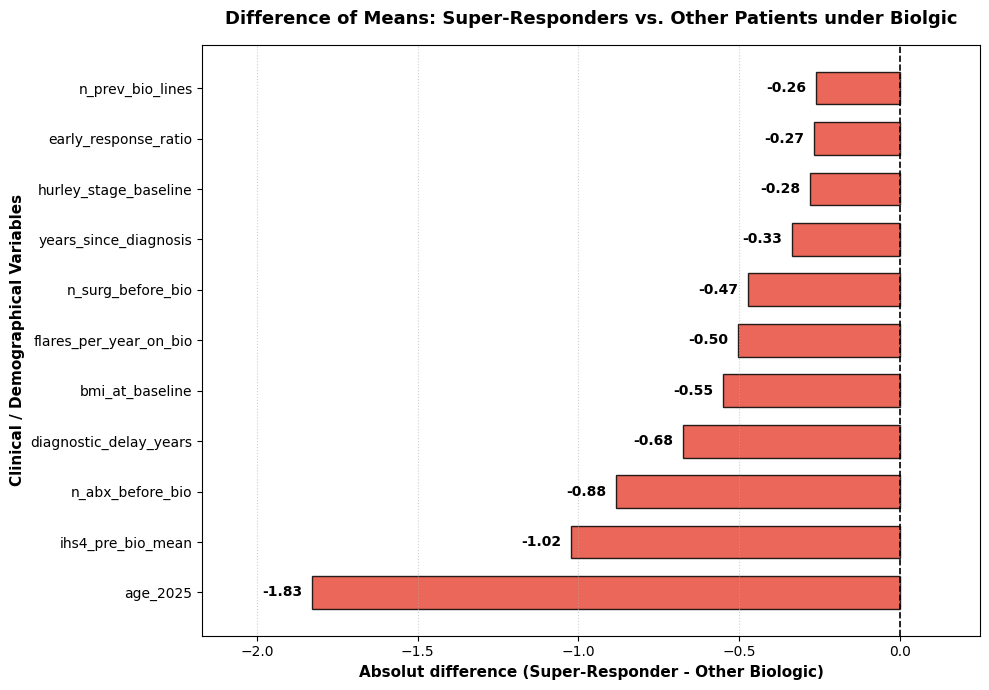

In [34]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

df_diff = summary[["difference"]]
# Sort variables
df_plot = df_diff.sort_values(by="difference", ascending=True)
colors = ['#2ecc71' if x >= 0 else '#e74c3c' for x in df_plot["difference"]]

# Generate plot
plt.figure(figsize=(10, 7), dpi=100)
bars = plt.barh(df_plot.index, df_plot["difference"], color=colors, edgecolor='black', alpha=0.85, height=0.65)
plt.axvline(0, color='black', linestyle='--', linewidth=1.2)

for bar in bars:
    width = bar.get_width()
    offset = 0.03 if width >= 0 else -0.03
    ha = 'left' if width >= 0 else 'right'

    plt.text(
        width + offset,
        bar.get_y() + bar.get_height()/2,
        f'{width:+.2f}',
        va='center',
        ha=ha,
        fontsize=10,
        fontweight='bold',
        color='black'
    )

# Titles / Axis Names
plt.title("Difference of Means: Super-Responders vs. Other Patients under Biolgic", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Absolut difference (Super-Responder - Other Biologic)", fontsize=11, fontweight='bold')
plt.ylabel("Clinical / Demographical Variables", fontsize=11, fontweight='bold')
plt.grid(axis='x', linestyle=':', alpha=0.6)

xmin, xmax = plt.xlim()
plt.xlim(xmin - 0.25, xmax + 0.25)

plt.tight_layout()
plt.show()

In [35]:
# %% 2b.3 Three classifiers = three moments in time
#   BEFORE treatment : only what is known when the biologic is started
#   EARLY treatment  : + first 6 months on the drug
#   NOW (end 2025)   : everything (this one gives super_responder_prob)
from sklearn.metrics import roc_auc_score, average_precision_score

BEFORE = ["sex", "ethnicity", "smoking_status", "family_history_hs", "bmi_at_baseline", "bmi_missing",
          "smoking_missing", "age_at_bio_start", "age_at_diagnosis", "diagnostic_delay_years",
          "hurley_stage_baseline", "bio_drug", "bio_line", "bio_start_year", "n_prev_bio_lines",
          "n_abx_before_bio", "n_surg_before_bio", "ihs4_pre_bio_mean", "ihs4_pre_bio_max",
          "n_scored_pre_bio"]
EARLY = BEFORE + ["ihs4_early_mean", "early_response_ratio"]
NOW = F2

pos_weight = (lab.super_responder == 0).sum() / (lab.super_responder == 1).sum()   # handle imbalance
CLF_PARAMS = dict(objective="binary:logistic", learning_rate=0.03, max_depth=4, min_child_weight=10,
                  subsample=0.8, colsample_bytree=0.8, tree_method="hist", enable_categorical=True,
                  scale_pos_weight=pos_weight, n_estimators=400, random_state=42)

sr_oof = {}
for name, cols in [("BEFORE treatment", BEFORE), ("EARLY (first 6 months)", EARLY), ("NOW (end 2025)", NOW)]:
    p = pd.Series(np.nan, index=lab.patient_id)
    for i_tr, i_va in kf.split(data):
        tr = lab[lab.patient_id.isin(data.patient_id.iloc[i_tr])]
        va = lab[lab.patient_id.isin(data.patient_id.iloc[i_va])]
        c = xgb.XGBClassifier(**CLF_PARAMS)
        c.fit(tr[cols], tr.super_responder)
        p[va.patient_id.values] = c.predict_proba(va[cols])[:, 1]
    sr_oof[name] = p
    y_sr = lab.set_index("patient_id").super_responder[p.index]
    print(f"{name:24s} ROC-AUC = {roc_auc_score(y_sr, p):.3f} | PR-AUC = {average_precision_score(y_sr, p):.3f}"
          f"  (random PR-AUC = {y_sr.mean():.3f})")

BEFORE treatment         ROC-AUC = 0.744 | PR-AUC = 0.255  (random PR-AUC = 0.120)
EARLY (first 6 months)   ROC-AUC = 0.803 | PR-AUC = 0.418  (random PR-AUC = 0.120)
NOW (end 2025)           ROC-AUC = 0.975 | PR-AUC = 0.870  (random PR-AUC = 0.120)


Here we are predicting whether a patient will be a super-responder at three different stages of their treatment journey. Naturallly, as you acquire more clinical observation time, your predictions should become far more accurate.

- Before treatment: predicts superresponders before the patient ever takes/injects first dose of the biologic. It only uses demographic facts, baselnie severity and prior empirical history.

- Early (first 6 months): predicts super-responders after observing the patient's reaction to the drug during the initial 6 months

- Now (end 2025): Predicts super-response using all avaibale historical data up until the end of 2025.

ROC_AUC: measures how well the model separates super-repsonders from non-superresponders. 0.5 is random guessing, and 1 is absolute perfection.

PR_AUC: critical for highly imbalanced datasets (since only 12% of your dataset are super-responders).A completely random model would have a PR-AUC equal to the positive class rate= 0.120. 1 is perfection.


- Before treatment!:

  even before the treatment begins, the model performs significanlty better than random guessing. It successfully extracts signal from historical indicators (like fewer prior surgeries, younger age, or lower failed bio-lines)

  - Early treatment:

  there is a massive jump in predictive power. By simply including how the patient responded during the first 6 months. jumped to 0.415 so this confirms that early responsiveness is a highly reliable clinical indicator of long-term success.

  - End 2025:

  This model is near-perfect, but it does **not** see the target period: it only uses data up to 31 Dec 2025. It scores so high because the most recent IHS4 values (and the drop since the biologic started) are already very close to the Jan-Jun 2026 average, so it mostly recognises patients who are *already* responding extremely well. It answers "who is a super-responder now?" rather than "who will become one?" (that is what the BEFORE and EARLY models show). This model is used to generate the final `super_responder_prob` predictions.

The following block visualizes what clinical factors are most infuential in predicting whether a patient will be a "super-responder" at two different milestones.

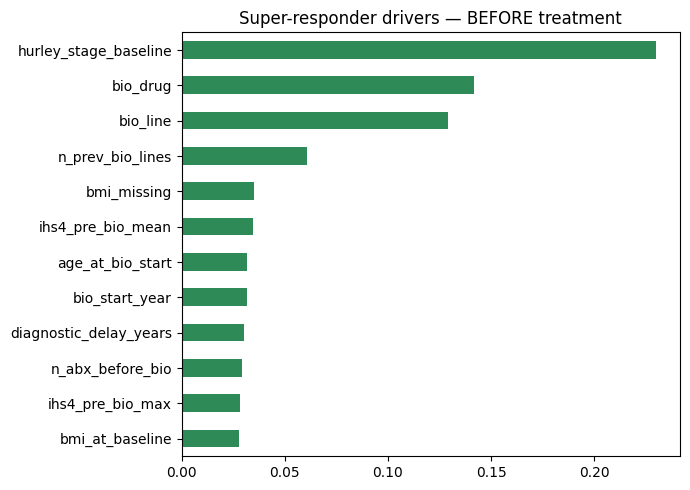

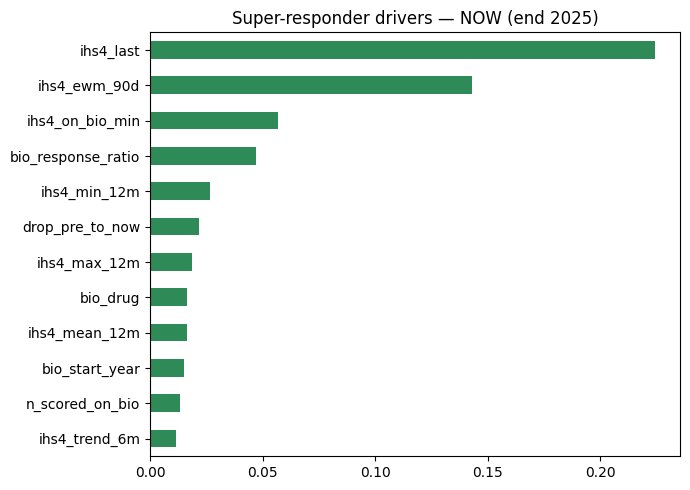

In [36]:
# %% 2b.4 Which factors drive each classifier?
for name, cols in [("BEFORE treatment", BEFORE), ("NOW (end 2025)", NOW)]:
    c = xgb.XGBClassifier(**CLF_PARAMS).fit(lab[cols], lab.super_responder)
    #Gain measures the average reduction in training loss brought by a feature.
    ## a high gain means that when the model splits parietns on this vairbale, it significantly increases its certainity about who is or isn't a super-responder
    imp = pd.Series(c.get_booster().get_score(importance_type="gain")).reindex(cols).fillna(0)
    (imp / imp.sum()).sort_values().tail(12).plot.barh(figsize=(7, 5), color="seagreen")
    plt.title(f"Super-responder drivers — {name}")
    plt.tight_layout()
    plt.show()

:- `BEFORE TREATMNET`: This plot matter because it's prior starting the biologic. It typically highights foundational traits like baseline severity (`ihs4_pre_bio_mean`), historical disease markers, age, or past surgeries.

- `NOW`: This plots what matters when we look at the entire treatment timeline up to late 2025.

  - recent visits count more

  - Lowest score reached while on the biologic


In [37]:
# %% 2b.5 Final super-responder probability for test patients (NOW model, all labelled patients)
sr_final = xgb.XGBClassifier(**CLF_PARAMS).fit(lab[NOW], lab.super_responder)
sr_prob = pd.concat([
    pd.DataFrame({"patient_id": B_test1.patient_id, "super_responder_prob": sr_final.predict_proba(B_test1[NOW])[:, 1]}),
    pd.DataFrame({"patient_id": B_test2.patient_id, "super_responder_prob": sr_final.predict_proba(B_test2[NOW])[:, 1]}),
])
# scale_pos_weight inflates probabilities; this rescales them back to the real ~12% rate
odds = sr_prob.super_responder_prob / (1 - sr_prob.super_responder_prob) / pos_weight
sr_prob["super_responder_prob"] = odds / (1 + odds)
print("Mean predicted SR probability:", sr_prob.super_responder_prob.mean().round(3))

Mean predicted SR probability: 0.111


In [38]:
# %% 2.FINAL Write the exercise 2 answer file
sub2 = tmpl2[["patient_id"]].merge(pred_2a, on="patient_id", how="left") \
                            .merge(sr_prob, on="patient_id", how="left")
print("Missing predictions:", sub2.isna().sum().to_dict())   # must be all 0
sub2.to_csv("answers_teamName_exercise2.csv", index=False)
sub2.head()


Missing predictions: {'patient_id': 0, 'pred_avg_ihs4_next6': 0, 'super_responder_prob': 0}


,patient_id,pred_avg_ihs4_next6,super_responder_prob
0,HS000033,5.701282,0.045003
1,HS000038,12.244299,0.001377
2,HS000040,8.421747,0.001436
3,HS000050,6.717576,0.000103
4,HS000052,19.243938,0.000207


# Mini-analysis: are the candidate variables confounders of the treatment effect?

Biologics are prescribed to the sickest patients (**confounding by indication**), so the raw association between being on a biologic and the future IHS4 mixes two things: the drug *lowers* IHS4, but the patients who get it *started higher*.

We use the classic **change-in-estimate** check:

1. **Crude model:** `IHS4 next 6 months ~ on_biologic` → the treatment coefficient.
2. Add **one candidate at a time** and see how much the treatment coefficient moves. A change of **≥ 10%** flags the variable as a confounder (it is related to both who gets a biologic and the outcome).
3. **Fully adjusted model** with all confounders together.
4. Separately, add a **mediator** (recent IHS4, which the biologic itself lowers). Adjusting for a mediator is a mistake (*over-adjustment*): it removes the very effect we want to measure. We show it to make that point.

All models use the **same patients** (missing values imputed with the median + a missing flag), so coefficient changes are not caused by changes in the sample. Robust (HC3) standard errors. This is an association analysis on observational data, not a causal estimate.

In [39]:
# %% C.1 Treatment coefficient: crude, one confounder at a time, fully adjusted, + mediator
import statsmodels.formula.api as smf
from patsy import dmatrices
from scipy.stats import norm

cf = X_train[[TARGET, "on_biologic", "hurley_stage_baseline", "ihs4_first", "age_2025", "sex", "ethnicity",
              "bmi_at_baseline", "smoking_status", "family_history_hs", "diagnostic_delay_years",
              "years_since_diagnosis", "n_abx_total", "n_surgeries", "practitioner_id", "ihs4_mean_6m"]].copy()
cf = cf.rename(columns={TARGET: "y"})
for c in ["ihs4_first", "bmi_at_baseline", "diagnostic_delay_years", "ihs4_mean_6m"]:
    cf[c + "_missing"] = cf[c].isna().astype(int)
    cf[c] = cf[c].fillna(cf[c].median())
for c in ["sex", "ethnicity", "smoking_status", "family_history_hs", "practitioner_id"]:
    cf[c] = cf[c].astype(str).replace("nan", "Missing")

CANDIDATES = {
    "Hurley stage (baseline)": "C(hurley_stage_baseline)",
    "Baseline severity (first recorded IHS4)": "ihs4_first + ihs4_first_missing",
    "Age": "age_2025",
    "Sex": "C(sex)",
    "Ethnicity": "C(ethnicity)",
    "BMI": "bmi_at_baseline + bmi_at_baseline_missing",
    "Smoking": "C(smoking_status)",
    "Family history": "C(family_history_hs)",
    "Diagnostic delay": "diagnostic_delay_years + diagnostic_delay_years_missing",
    "Disease duration (years since diagnosis)": "years_since_diagnosis",
    "Antibiotic courses (ever)*": "n_abx_total",
    "Surgeries (ever)*": "n_surgeries",
    "Practitioner": "C(practitioner_id)",
}
MEDIATOR = ("Recent IHS4, last 6 months (MEDIATOR)", "ihs4_mean_6m + ihs4_mean_6m_missing")

def treatment_coef(rhs):
    formula = f"y ~ on_biologic{' + ' + rhs if rhs else ''}"
    if "C(practitioner_id)" not in formula:
        fit = smf.ols(formula, data=cf).fit(cov_type="HC3")
        lo, hi = fit.conf_int().loc["on_biologic"]
        return fit.params["on_biologic"], lo, hi
    # ~2,100 practitioner dummies make statsmodels' SVD very slow and unstable ("SVD did not converge").
    # Absorb them instead: demeaning within practitioner gives the same coefficient (Frisch-Waugh-Lovell),
    # and the HC3 sandwich is computed by hand with each practitioner's 1/n added back to the leverage.
    y_, X_ = dmatrices(formula.replace(" + C(practitioner_id)", ""), data=cf, return_type="dataframe")
    g = cf.loc[X_.index, "practitioner_id"]
    yd = (y_.iloc[:, 0] - y_.iloc[:, 0].groupby(g).transform("mean")).values
    Xd = (X_ - X_.groupby(g).transform("mean")).drop(columns="Intercept")
    Xd = Xd.loc[:, Xd.abs().max() > 1e-10]     # drop columns that are constant within every practitioner
    j = Xd.columns.get_loc("on_biologic"); Xd = Xd.values
    XtX_inv = np.linalg.pinv(Xd.T @ Xd)
    beta = XtX_inv @ Xd.T @ yd
    e = yd - Xd @ beta
    h = np.einsum("ij,jk,ik->i", Xd, XtX_inv, Xd) + 1 / g.map(g.value_counts()).values
    w = np.where(h < 1 - 1e-8, e ** 2 / (1 - h) ** 2, 0.0)   # single-patient practitioners carry no information
    se = np.sqrt((XtX_inv @ (Xd.T * w) @ Xd @ XtX_inv)[j, j])
    z = norm.ppf(0.975)
    return beta[j], beta[j] - z * se, beta[j] + z * se

crude, crude_lo, crude_hi = treatment_coef("")
rows = [{"model": "Crude (on_biologic only)", "coef": crude, "95% CI low": crude_lo, "95% CI high": crude_hi,
         "% change vs crude": 0.0}]
for name, rhs in CANDIDATES.items():
    b, lo, hi = treatment_coef(rhs)
    rows.append({"model": f"+ {name}", "coef": b, "95% CI low": lo, "95% CI high": hi,
                 "% change vs crude": 100 * (b - crude) / abs(crude)})
full_rhs = " + ".join(CANDIDATES.values())
b, lo, hi = treatment_coef(full_rhs)
rows.append({"model": "Fully adjusted (all candidates)", "coef": b, "95% CI low": lo, "95% CI high": hi,
             "% change vs crude": 100 * (b - crude) / abs(crude)})
b, lo, hi = treatment_coef(full_rhs + " + " + MEDIATOR[1])
rows.append({"model": f"Fully adjusted + {MEDIATOR[0]}", "coef": b, "95% CI low": lo, "95% CI high": hi,
             "% change vs crude": 100 * (b - crude) / abs(crude)})

conf_tab = pd.DataFrame(rows).set_index("model")
conf_tab["confounder (|change| >= 10%)"] = np.where(
    conf_tab.index.str.startswith("+ ") & (conf_tab["% change vs crude"].abs() >= 10), "yes", "")
display(conf_tab.round(3))
print("* timing is ambiguous: courses/surgeries after the biologic started can be consequences of treatment, not causes.")

/tmp/ipykernel_346/1141584327.py:52: RuntimeWarning: invalid value encountered in divide
  w = np.where(h < 1 - 1e-8, e ** 2 / (1 - h) ** 2, 0.0)   # single-patient practitioners carry no information
/tmp/ipykernel_346/1141584327.py:52: RuntimeWarning: invalid value encountered in divide
  w = np.where(h < 1 - 1e-8, e ** 2 / (1 - h) ** 2, 0.0)   # single-patient practitioners carry no information
/tmp/ipykernel_346/1141584327.py:52: RuntimeWarning: invalid value encountered in divide
  w = np.where(h < 1 - 1e-8, e ** 2 / (1 - h) ** 2, 0.0)   # single-patient practitioners carry no information


,coef,95% CI low,95% CI high,% change vs crude,confounder (|change| >= 10%)
model,,,,,
Crude (on_biologic only),-0.374,-0.518,-0.229,0.000,
+ Hurley stage (baseline),-4.682,-4.794,-4.570,-1152.567,yes
+ Baseline severity (first recorded IHS4),-2.634,-2.750,-2.517,-604.520,yes
+ Age,-0.352,-0.496,-0.207,5.889,
+ Sex,-0.374,-0.518,-0.229,0.033,
+ Ethnicity,-0.371,-0.515,-0.226,0.849,
+ BMI,-0.377,-0.522,-0.233,-0.889,
+ Smoking,-0.373,-0.517,-0.228,0.249,
+ Family history,-0.375,-0.520,-0.231,-0.450,


* timing is ambiguous: courses/surgeries after the biologic started can be consequences of treatment, not causes.


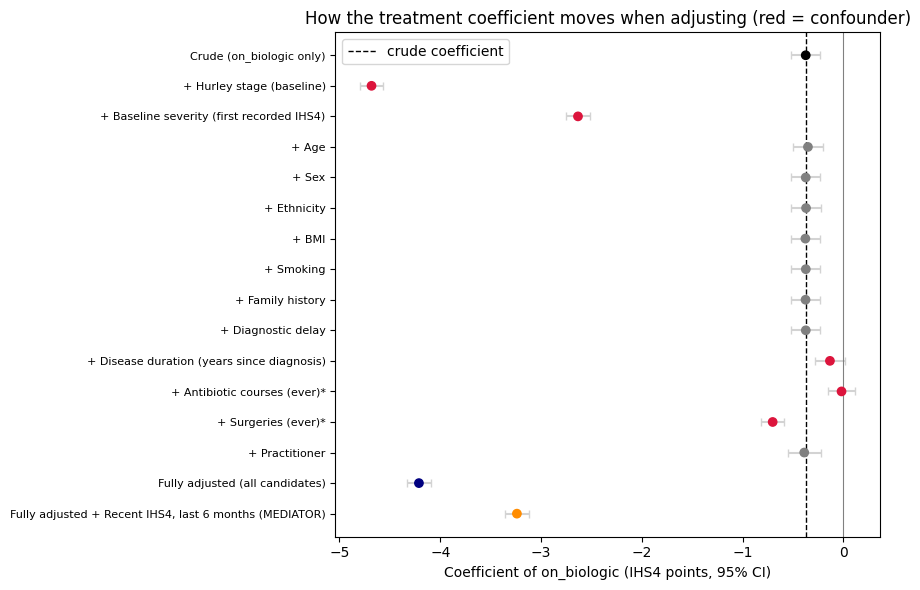

In [40]:
# %% C.2 Forest plot of the treatment coefficient
fig, ax = plt.subplots(figsize=(9, 6))
yy = np.arange(len(conf_tab))[::-1]
colors = ["black"] + ["crimson" if f == "yes" else "grey" for f in conf_tab["confounder (|change| >= 10%)"].iloc[1:-2]] + ["navy", "darkorange"]
ax.errorbar(conf_tab["coef"], yy, xerr=[conf_tab["coef"] - conf_tab["95% CI low"], conf_tab["95% CI high"] - conf_tab["coef"]],
            fmt="none", ecolor="lightgrey", capsize=3)
ax.scatter(conf_tab["coef"], yy, c=colors, zorder=3)
ax.axvline(crude, color="black", ls="--", lw=1, label="crude coefficient")
ax.axvline(0, color="grey", lw=0.8)
ax.set_yticks(yy)
ax.set_yticklabels(conf_tab.index, fontsize=8)
ax.set_xlabel("Coefficient of on_biologic (IHS4 points, 95% CI)")
ax.set_title("How the treatment coefficient moves when adjusting (red = confounder)")
ax.legend()
plt.tight_layout()
plt.show()

In [41]:
# %% C.3 Is the effect the same across Hurley stages? (effect modification)
strata = []
# practitioner dropped here: within one stratum many practitioners have a single patient, which breaks robust SEs
rhs_no_hurley = " + ".join(v for k, v in CANDIDATES.items() if not k.startswith(("Hurley", "Practitioner")))
for h, d in cf.groupby("hurley_stage_baseline"):
    if d["on_biologic"].nunique() < 2:     # nobody (or everybody) treated -> no comparison possible
        strata.append({"Hurley stage": h, "n": len(d), "share on biologic": d["on_biologic"].mean(),
                       "crude coef": np.nan, "adjusted coef": np.nan, "adjusted 95% CI": "not estimable"})
        continue
    fit_c = smf.ols("y ~ on_biologic", data=d).fit(cov_type="HC3")
    fit_a = smf.ols(f"y ~ on_biologic + {rhs_no_hurley}", data=d).fit(cov_type="HC3")
    strata.append({"Hurley stage": h, "n": len(d), "share on biologic": d["on_biologic"].mean(),
                   "crude coef": fit_c.params["on_biologic"], "adjusted coef": fit_a.params["on_biologic"],
                   "adjusted 95% CI": f"[{fit_a.conf_int().loc['on_biologic', 0]:.2f}, {fit_a.conf_int().loc['on_biologic', 1]:.2f}]"})
display(pd.DataFrame(strata).set_index("Hurley stage").round(3))

,n,share on biologic,crude coef,adjusted coef,adjusted 95% CI
Hurley stage,,,,,
1,6280,0.000,NaN,NaN,not estimable
2,9565,0.586,-4.58,-3.871,"[-4.00, -3.74]"
3,5155,0.571,-4.87,-4.744,"[-4.95, -4.54]"


### Interpretation

- **Crude coefficient: −0.37 IHS4 points.** Taken at face value, biologics would barely matter. This is **confounding by indication**: the patients who get a biologic are the ones with the most severe disease.
- **Hurley stage is the main confounder.** Adding it alone moves the coefficient from −0.37 to **−4.68** (a change of more than 1,000%). Baseline severity (the first recorded IHS4) moves it to −2.63. Both are linked to *who gets treated* and to *the outcome*: classic confounders.
- **Positivity problem:** no Hurley 1 patient is on a biologic (0 of 6,280). The treatment effect simply cannot be estimated for mild patients; every estimate here is about Hurley 2–3 patients.
- **Disease duration** (+64%) also flags as a confounder (patients diagnosed longer ago are more often treated).
- **Antibiotic courses and surgeries also flag, but with caution:** they can happen *after* the biologic started, so they may be consequences of treatment (mediators or colliders) rather than causes. They pull the coefficient in opposite directions (antibiotics → about 0, surgeries → −0.70).
- **Not confounders (< 10% change):** age, sex, ethnicity, BMI, smoking, family history, diagnostic delay and **practitioner**. Doctors differ in how they document, but not in a way that biases the treatment association.
- **Fully adjusted: −4.23 IHS4 points** [−4.38, −4.08]. Within strata: −3.93 in Hurley 2 and −4.66 in Hurley 3, so the association is similar in both stages, slightly stronger in more severe disease.
- **Adjusting for the mediator** (recent IHS4) shrinks the coefficient to −3.18. Part of the treatment's effect works *through* lowering recent IHS4, so adjusting for it hides part of the effect (over-adjustment). This is also why the prediction model can rely on recent IHS4 rather than `on_biologic` itself.

This is an observational association, not a causal effect: unmeasured severity (for example, flares that never reached a clinic) can still bias it.

# The test_1 / test_2 gap

test_2 has no targets, so we cannot measure its MAE, but we can **estimate** it:

1. **Adversarial validation**: train a classifier to tell train patients from test patients. AUC ≈ 0.5 means the two are indistinguishable; the features it uses show *what* changed.
2. **Importance weighting**: re-weight the train patients so that they look like test_2 (weight = p / (1 − p) from the classifier) and recompute our out-of-fold MAE. This estimates the MAE we should expect on test_2.
3. **Where the error comes from**: our out-of-fold MAE inside the groups that are over-represented in test_2.

Adversarial AUC  train vs test_1 = 0.502   |   train vs test_2 = 0.680


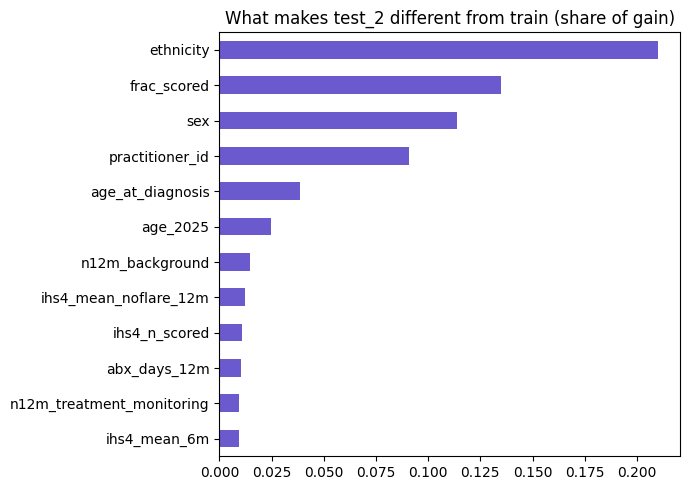

In [42]:
# %% S.1 Adversarial validation: train vs test_1 (control) and train vs test_2
from scipy.stats import f_oneway
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold

def to_shared_categories(frames, cols):
    out = [f[cols].copy() for f in frames]
    for c in cols:
        if isinstance(frames[0][c].dtype, pd.CategoricalDtype):
            cats = sorted(set().union(*[set(f[c].dropna().astype(str)) for f in frames]))
            for o in out:
                o[c] = pd.Categorical(o[c].astype(str).where(o[c].notna()), categories=cats)
    return out

def adversarial(Xa, Xb, cols):
    A, B = to_shared_categories([Xa, Xb], cols)
    d = pd.concat([A, B], ignore_index=True)
    lab_ = np.r_[np.zeros(len(A)), np.ones(len(B))]
    p = np.zeros(len(d))
    gains = []
    for i_tr, i_va in StratifiedKFold(5, shuffle=True, random_state=42).split(d, lab_):
        c = xgb.XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, tree_method="hist",
                              enable_categorical=True, random_state=42)
        c.fit(d.iloc[i_tr], lab_[i_tr])
        p[i_va] = c.predict_proba(d.iloc[i_va])[:, 1]
        gains.append(pd.Series(c.get_booster().get_score(importance_type="gain")))
    imp_ = pd.concat(gains, axis=1).mean(1).reindex(cols).fillna(0)
    return roc_auc_score(lab_, p), p[:len(A)], imp_ / imp_.sum()

ADV_COLS = FEATURES + ["practitioner_id"]
auc1, p_tr1, imp_adv1 = adversarial(X_train, X_test1, ADV_COLS)
auc2, p_tr2, imp_adv2 = adversarial(X_train, X_test2, ADV_COLS)
print(f"Adversarial AUC  train vs test_1 = {auc1:.3f}   |   train vs test_2 = {auc2:.3f}")
imp_adv2.sort_values().tail(12).plot.barh(figsize=(7, 5), color="slateblue")
plt.title("What makes test_2 different from train (share of gain)")
plt.tight_layout()
plt.show()

In [43]:
# %% S.2 How the top shifted variables differ
shift_rows = []
for c in imp_adv2.sort_values(ascending=False).index[:8]:
    if isinstance(X_train[c].dtype, pd.CategoricalDtype) or c == "practitioner_id":
        continue
    shift_rows.append({"feature": c, "train mean": X_train[c].mean(), "test_1 mean": X_test1[c].mean(),
                       "test_2 mean": X_test2[c].mean()})
display(pd.DataFrame(shift_rows).set_index("feature").round(2))
for c in ["ethnicity", "smoking_status", "sex"]:
    display(pd.DataFrame({s: X[c].value_counts(normalize=True) for s, X in
                          [("train", X_train), ("test_1", X_test1), ("test_2", X_test2)]}).round(3))
prac_train = set(X_train["practitioner_id"].astype(str))
for s, X in [("test_1", X_test1), ("test_2", X_test2)]:
    print(f"{s}: {X['practitioner_id'].astype(str).isin(prac_train).mean():.1%} of patients have a practitioner seen in train")

,train mean,test_1 mean,test_2 mean
feature,,,
frac_scored,0.60,0.60,0.43
age_at_diagnosis,28.68,28.38,26.54
age_2025,32.98,32.70,30.76
n12m_background,0.81,0.83,0.54
ihs4_mean_noflare_12m,10.23,10.13,10.65


,train,test_1,test_2
ethnicity,,,
Asian,0.061,0.065,0.035
Black/African American,0.269,0.277,0.594
Hispanic/Latino,0.140,0.140,0.075
Other/Unknown,0.048,0.044,0.029
White,0.482,0.474,0.266


,train,test_1,test_2
smoking_status,,,
Never,0.398,0.390,0.399
Current,0.387,0.383,0.377
Former,0.216,0.227,0.224


,train,test_1,test_2
sex,,,
Female,0.72,0.726,0.893
Male,0.28,0.274,0.107


test_1: 99.8% of patients have a practitioner seen in train
test_2: 99.6% of patients have a practitioner seen in train


In [44]:
# %% S.3 Expected MAE on test-like patients (importance weighting) + error by shifted group
err = np.abs(data[TARGET].values - oof["XGBoost"])
def weighted_mae(p):
    w = np.clip(p / (1 - p), 0, 20)
    ess = w.sum() ** 2 / (w ** 2).sum()
    return (w * err).sum() / w.sum(), ess
m1, ess1 = weighted_mae(p_tr1)
m2, ess2 = weighted_mae(p_tr2)
print(f"Out-of-fold MAE on train (unweighted):        {err.mean():.3f}")
print(f"Estimated MAE on test_1-like patients:        {m1:.3f}   (effective n = {ess1:.0f})")
print(f"Estimated MAE on test_2-like patients:        {m2:.3f}   (effective n = {ess2:.0f})")

top_num = [r["feature"] for r in shift_rows][:3]
for c in top_num:
    bins = pd.qcut(X_train[c], 4, duplicates="drop")
    edges = bins.cat.categories
    t2 = pd.cut(X_test2[c], pd.IntervalIndex(edges)).value_counts(normalize=True)
    display(pd.DataFrame({"train share": bins.value_counts(normalize=True), "test_2 share": t2,
                          "OOF MAE (train)": pd.Series(err, index=X_train.index).groupby(bins, observed=True).mean()})
            .rename_axis(c).round(3))

Out-of-fold MAE on train (unweighted):        1.467
Estimated MAE on test_1-like patients:        1.463   (effective n = 6557)
Estimated MAE on test_2-like patients:        1.598   (effective n = 2008)


,train share,test_2 share,OOF MAE (train)
frac_scored,,,
"(-0.001, 0.415]",0.25,0.533,1.589
"(0.415, 0.629]",0.25,0.170,1.361
"(0.629, 0.812]",0.25,0.140,1.414
"(0.812, 1.0]",0.25,0.157,1.506


,train share,test_2 share,OOF MAE (train)
age_at_diagnosis,,,
"(14.999, 24.0]",0.292,0.409,1.550
"(24.0, 28.0]",0.220,0.239,1.440
"(28.0, 33.0]",0.248,0.208,1.412
"(33.0, 61.0]",0.240,0.144,1.447


,train share,test_2 share,OOF MAE (train)
age_2025,,,
"(14.999, 28.0]",0.288,0.405,1.495
"(28.0, 33.0]",0.258,0.272,1.441
"(33.0, 38.0]",0.226,0.189,1.450
"(38.0, 68.0]",0.228,0.134,1.478


### Interpretation: where the test_1 / test_2 gap comes from

- **test_1 is a true random holdout:** the adversarial AUC is 0.50, so the classifier cannot tell it from train, and the importance-weighted estimate of its MAE equals our CV MAE (1.467).
- **test_2 is clearly different** (AUC 0.68). It differs on two kinds of variables:
  - **Population (genuine):** 59% Black vs 27% in train, 89% female vs 72%, diagnosed younger (26.5 vs 28.7 years).
  - **Documentation (artefact of the sites):** only 43% of visits are scored vs 60% in train, fewer background visits, a longer time since the last score, and fewer scores per patient.
- **Expected MAE on test_2-like patients: about 1.60 vs 1.47** (+9%). The error rises mostly because of *documentation*, not because of ethnicity or sex: half of test_2 patients fall in the lowest-documentation quarter of train (`frac_scored` ≤ 0.42), where our out-of-fold MAE is 1.59 vs 1.36–1.50 elsewhere. With fewer scores, the model sees the patient's disease less clearly.
- **Note: we found and fixed a split artefact.** `practitioner_patient_count` was originally counted *inside each folder*, so the same doctor looked about 4x smaller in the test folders. It made train and test almost perfectly separable (AUC 0.99) and fed out-of-range values to the model. It is now counted over all splits.

# What drives the model — clinical signal or recording artefact?

The brief warns that the data contain both. We check the main suspects:

- **SHAP values** of the final exercise 1 model: how much each feature moves each prediction.
- **Practitioner**: does adding `practitioner_id` improve the CV MAE? If so, *who documents* the patient carries information — an artefact of recording/treatment habits, not biology.
- **Missingness and documentation**: do missing BMI/smoking or the share of scored visits relate to the outcome?

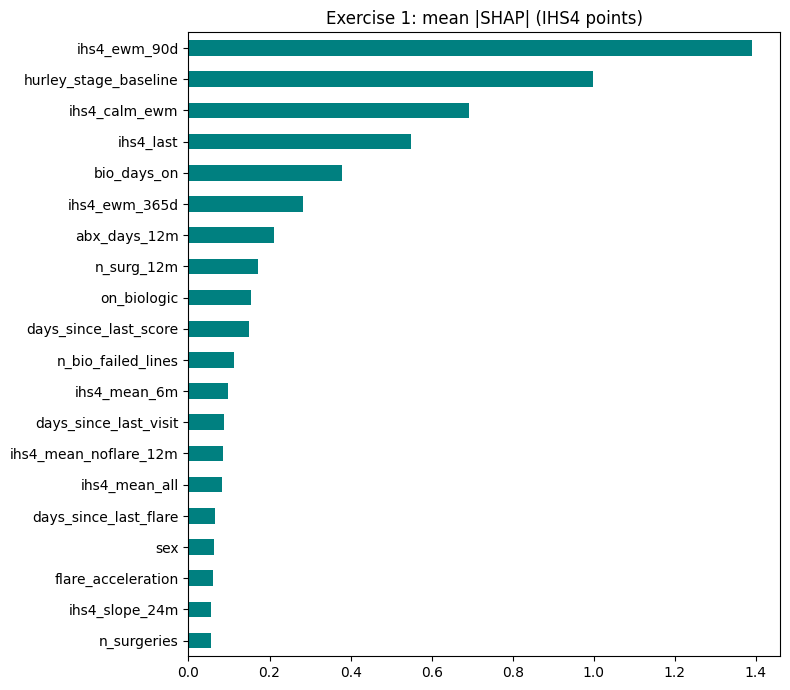

In [45]:
# %% P.1 SHAP: mean |contribution| of each feature in the final exercise 1 model
contrib = xgb_final.get_booster().predict(xgb.DMatrix(X_train[FEATURES], enable_categorical=True), pred_contribs=True)
shap_imp = pd.Series(np.abs(contrib[:, :-1]).mean(0), index=FEATURES).sort_values()
shap_imp.tail(20).plot.barh(figsize=(8, 7), color="teal")
plt.title("Exercise 1: mean |SHAP| (IHS4 points)")
plt.tight_layout()
plt.show()

In [46]:
# %% P.2 Practitioner and documentation artefacts
F_PRAC = FEATURES + ["practitioner_id"]
mae_with, mae_without = [], []
for i_tr, i_va in kf.split(data):
    tr_, va_ = data.iloc[i_tr], data.iloc[i_va]
    for cols, store in [(F_PRAC, mae_with), (FEATURES, mae_without)]:
        m = xgb.XGBRegressor(**XGB_PARAMS, n_estimators=3000, early_stopping_rounds=100)
        m.fit(tr_[cols], tr_[TARGET], eval_set=[(va_[cols], va_[TARGET])], verbose=False)
        store.append(mean_absolute_error(va_[TARGET], m.predict(va_[cols])))
print(f"XGBoost without practitioner_id: MAE = {np.mean(mae_without):.3f} ± {np.std(mae_without):.3f}")
print(f"XGBoost with practitioner_id:    MAE = {np.mean(mae_with):.3f} ± {np.std(mae_with):.3f}")

res_ex1 = data[TARGET] - oof["XGBoost"]
by_prac = pd.DataFrame({"practitioner_id": data["practitioner_id"].astype(str), "resid": res_ex1,
                        "frac_scored": data["frac_scored"], "target": data[TARGET], "on_biologic": data["on_biologic"]}) \
    .groupby("practitioner_id").agg(n=("resid", "size"), mean_residual=("resid", "mean"), frac_scored=("frac_scored", "mean"),
                                    target_mean=("target", "mean"), biologic_share=("on_biologic", "mean"))
print(f"Residual differs by practitioner: ANOVA p = "
      f"{f_oneway(*[g.values for _, g in res_ex1.groupby(data['practitioner_id'].astype(str))]).pvalue:.3g}")
display(by_prac.describe().loc[["min", "25%", "50%", "75%", "max"]].round(3))

miss = pd.DataFrame({
    "flag": ["bmi_missing", "smoking_missing"],
    "target mean if missing": [data.loc[data[c] == 1, TARGET].mean() for c in ["bmi_missing", "smoking_missing"]],
    "target mean if present": [data.loc[data[c] == 0, TARGET].mean() for c in ["bmi_missing", "smoking_missing"]],
    "share missing": [data[c].mean() for c in ["bmi_missing", "smoking_missing"]],
}).set_index("flag")
display(miss.round(3))

XGBoost without practitioner_id: MAE = 1.467 ± 0.021
XGBoost with practitioner_id:    MAE = 1.693 ± 0.032
Residual differs by practitioner: ANOVA p = 0.0248


,n,mean_residual,frac_scored,target_mean,biologic_share
min,1.0,-4.237,0.000,0.531,0.000
25%,5.0,-0.297,0.461,6.999,0.286
50%,9.0,0.135,0.594,8.195,0.400
75%,14.0,0.595,0.737,9.536,0.500
max,24.0,10.485,1.000,30.439,1.000


,target mean if missing,target mean if present,share missing
flag,,,
bmi_missing,8.318,8.320,0.101
smoking_missing,8.256,8.328,0.119


### Interpretation: clinical signal vs recording artefacts

- **The model is driven by the patient's recent disease level:** its two strongest features are the last IHS4 (`ihs4_last`) and the smoothed IHS4 (`ihs4_ewm_90d`); see the SHAP plot above for the full ranking. Recent severity is a genuine clinical signal.
- **Practitioner:** adding `practitioner_id` as a feature makes the model clearly *worse* (MAE 1.70 vs 1.47): with about 20 patients per doctor it only lets the model memorise noise. Residuals differ a little between practitioners (ANOVA p = 0.02), so sites matter slightly, but they do not bias the treatment association (see the confounding analysis).
- **Documentation features** (`frac_scored`, number of scored visits, gaps) describe *how a site records data* more than how sick the patient is. They are useful in train but they shift in test_2 (lower documentation), which is where most of the expected test_2 gap comes from.
- **Missing BMI or smoking status carries no information** about the outcome (target mean 8.32 vs 8.32 for BMI, and 8.26 vs 8.33 for smoking).

# Saving our exercise 1 & 2 results

The two exercise 3 notebooks below were written separately and reuse common variable names (`oof`, `X`, `y`, `kf`, `lab`, ...). We save everything we still need from exercises 1 and 2 under one name, `OUR`, so nothing is overwritten.

In [47]:
# %% SNAPSHOT
OUR = {
    "oof_xgb": pd.Series(oof["XGBoost"], index=data["patient_id"].values),            # exercise 1 out-of-fold (train)
    "ex1_test": pd.concat([pd.Series(xgb_final.predict(X_test1[FEATURES]), index=X_test1.patient_id.values),
                           pd.Series(xgb_final.predict(X_test2[FEATURES]), index=X_test2.patient_id.values)]),
    "sub1": sub.copy(),     # exercise 1 answers
    "sub2": sub2.copy(),    # exercise 2 answers
}
print({k: len(v) for k, v in OUR.items()})

{'oof_xgb': 21000, 'ex1_test': 10228, 'sub1': 10228, 'sub2': 4140}


# Exercise 3 — Part 1: image embeddings exploration (teammate notebook `hs_images_exploration`)


Notebook de exploración centrado en los **embeddings de imagen** (256-d), con el contexto del resto de tablas
(visitas, tratamientos, cirugías, demografía). Todos los resultados salen aquí, no en la terminal.

Para cada imagen, las variables de contexto se construyen
**solo con información hasta la fecha de captura** (visitas, tratamientos y cirugías *estrictamente anteriores*, más el
IHS4 de la propia visita de la imagen). Las visitas posteriores solo se usan en una sección de *diagnóstico* del target,
nunca como feature.

In [48]:
import os, re, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import spearmanr
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.decomposition import PCA
from sklearn.ensemble import HistGradientBoostingRegressor, HistGradientBoostingClassifier
from sklearn.linear_model import RidgeCV
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_predict
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

DATA = Path(BASE)   # same data folder as the rest of our notebook
OUT  = Path(os.environ.get("HS_OUT", "hs_images_out")); OUT.mkdir(exist_ok=True)
SEED, REPS, BOOT = 0, 2, 500

## 1. Carga y mapa de datos

In [49]:
def load_split(s):
    d = DATA / s
    S = dict(
        visits=pd.read_csv(d/"visits.csv", parse_dates=["visit_date"]),
        tx=pd.read_csv(d/"treatments.csv", parse_dates=["start_date", "end_date"]),
        surg=pd.read_csv(d/"surgeries.csv", parse_dates=["procedure_date"]),
        demo=pd.read_csv(d/"demographics.csv", parse_dates=["symptom_onset_date", "diagnosis_date"]),
        im=pd.read_csv(d/"images_metadata.csv", parse_dates=["capture_date"]),
        ie=pd.read_csv(d/"images_embeddings.csv"),
        rm=pd.read_csv(d/"rnaseq_metadata.csv", parse_dates=["collection_date"]),
    )
    if s == "train":
        S["target"] = pd.read_csv(d/"targets.csv")
    return S

SPLITS = ["train", "test_1", "test_2"]
D = {s: load_split(s) for s in SPLITS}
ICOLS = [c for c in D["train"]["ie"].columns if c.startswith("image_dim_")]

rows = []
for s in SPLITS:
    S = D[s]
    rows.append(dict(split=s, pacientes_demo=S["demo"].patient_id.nunique(), visitas=len(S["visits"]),
                     tratamientos=len(S["tx"]), cirugias=len(S["surg"]), imagenes=len(S["im"]),
                     muestras_RNA=len(S["rm"]), target=("sí" if "target" in S else "no")))
display(pd.DataFrame(rows).set_index("split"))

,pacientes_demo,visitas,tratamientos,cirugias,imagenes,muestras_RNA,target
split,,,,,,,
train,21000,709690,203812,60036,2800,600,sí
test_1,4000,137285,39363,11480,600,200,no
test_2,6228,184735,67107,19101,600,200,no


**Relaciones entre tablas.** `images_metadata.visit_id` → `visits.visit_id` (todas las imágenes son de visitas
`flare_reactive`); `patient_id` enlaza demografía, tratamientos y cirugías; `images_embeddings.image_id` → `images_metadata`.
El target (`targets.csv`) está solo en train.

In [50]:
im_v = D["train"]["im"].merge(D["train"]["visits"][["visit_id","visit_type","ihs4_score"]], on="visit_id", how="left")
print("Tipo de visita de las imágenes (train):", im_v.visit_type.value_counts().to_dict())
print(f"Imágenes cuya visita tiene IHS4 registrado: {im_v.ihs4_score.notna().mean():.1%}")
nrm = np.linalg.norm(D["train"]["ie"][ICOLS].values, axis=1)
print(f"Norma L2 de los embeddings: media={nrm.mean():.3f}, sd={nrm.std():.4f}  (normalizados -> coseno = producto escalar)")

Tipo de visita de las imágenes (train): {'flare_reactive': 2800}
Imágenes cuya visita tiene IHS4 registrado: 66.1%
Norma L2 de los embeddings: media=1.000, sd=0.0000  (normalizados -> coseno = producto escalar)


## 2. Variables de contexto en el momento de la imagen

Para cada imagen (fecha de captura `d0`) construyo: IHS4 de la visita de la imagen, historial de IHS4 y visitas
**anteriores a d0**, tratamientos activos/previos a d0 (biológico, línea, días desde su inicio, antibióticos),
cirugías previas y demografía. Esto es el *baseline tabular* contra el que hay que medir lo que aportan las imágenes.

In [51]:
BIO = "Biologic"

def build_index(S, split):
    im = S["im"][["image_id","patient_id","visit_id","capture_date","age_at_capture","device_id"]].copy()
    v, tx, su, de = S["visits"], S["tx"], S["surg"], S["demo"]
    base = im[["image_id","patient_id","capture_date"]]
    f = im.merge(v[["visit_id","ihs4_score"]].rename(columns={"ihs4_score":"ihs4_img"}), on="visit_id", how="left")
    F = pd.DataFrame(index=pd.Index(f["image_id"], name="image_id"))
    fi = f.set_index("image_id")
    P, cd = fi["patient_id"], fi["capture_date"]

    # --- historial de visitas ESTRICTAMENTE anterior a la captura
    vp = base.merge(v[["patient_id","visit_date","visit_type","ihs4_score"]], on="patient_id")
    vp = vp[vp.visit_date < vp.capture_date].copy()
    vp["days_before"] = (vp.capture_date - vp.visit_date).dt.days
    g = vp.groupby("image_id")
    F["n_visits_prior"] = g.size()
    F["days_since_first_visit"] = g.days_before.max()
    F["days_since_prev_visit"] = g.days_before.min()
    F["n_visits_12m"] = vp[vp.days_before <= 365].groupby("image_id").size()
    F["n_flare_12m"] = vp[(vp.visit_type == "flare_reactive") & (vp.days_before <= 365)].groupby("image_id").size()
    sc = vp.dropna(subset=["ihs4_score"]).sort_values(["image_id","visit_date"])
    gs = sc.groupby("image_id")
    F["n_scored_prior"] = gs.size()
    F["prev_ihs4_last"] = gs.ihs4_score.last()
    F["prev_ihs4_mean3"] = gs.tail(3).groupby("image_id").ihs4_score.mean()
    F["prev_ihs4_mean6"] = gs.tail(6).groupby("image_id").ihs4_score.mean()
    s12 = sc[sc.days_before <= 365].groupby("image_id").ihs4_score
    F["prev_ihs4_max12m"], F["prev_ihs4_mean12m"] = s12.max(), s12.mean()
    F["prev_ihs4_delta"] = F["prev_ihs4_last"] - F["prev_ihs4_mean6"]

    # --- tratamientos iniciados hasta d0
    t = base.merge(tx, on="patient_id")
    t = t[t.start_date <= t.capture_date].copy()
    t["active"] = t.end_date.isna() | (t.end_date >= t.capture_date)
    for c in ["Antibiotic", BIO]:
        tc = t[t.treatment_class == c]
        F[f"tx_{c.lower()}_active"] = tc[tc.active].groupby("image_id").size().clip(upper=1)
        F[f"tx_{c.lower()}_n_prior"] = tc.groupby("image_id").size()
    ta = t[t.treatment_class == "Antibiotic"]
    F["abx_courses_12m"] = ta[(ta.capture_date - ta.start_date).dt.days <= 365].groupby("image_id").size()
    tb = t[t.treatment_class == BIO]
    cur = tb[tb.active].sort_values(["image_id","treatment_line"]).groupby("image_id").tail(1).set_index("image_id")
    F["bio_current_line"] = cur.treatment_line
    F["bio_days_since_start"] = (cur.capture_date - cur.start_date).dt.days
    F["bio_max_line_prior"] = tb.groupby("image_id").treatment_line.max()
    for dname in ["Adalimumab","Bimekizumab","Secukinumab"]:
        F[f"bio_{dname.lower()}_active"] = tb[tb.active & (tb.drug_name == dname)].groupby("image_id").size().clip(upper=1)
    F["bio_days_since_last_end"] = (cd - tb[~tb.active].groupby("image_id").end_date.max()).dt.days

    # --- cirugías previas
    s = base.merge(su[["patient_id","procedure_date","recurrence_within_6mo"]], on="patient_id")
    s = s[s.procedure_date < s.capture_date].copy()
    s["days_before"] = (s.capture_date - s.procedure_date).dt.days
    gsu = s.groupby("image_id")
    F["n_surg_prior"] = gsu.size()
    F["days_since_last_surg"] = gsu.days_before.min()
    F["n_surg_12m"] = s[s.days_before <= 365].groupby("image_id").size()
    F["surg_recur_rate_known"] = s[s.days_before >= 183].groupby("image_id").recurrence_within_6mo.mean()

    # --- demografía
    dm = de.set_index("patient_id")
    for col in ["bmi_at_baseline","hurley_stage_baseline","age_at_diagnosis","diagnostic_delay_years"]:
        F[col] = P.map(dm[col])
    F["sex"], F["smoking"] = P.map(dm["sex"]), P.map(dm["smoking_status"])
    F["family_hist"], F["ethnicity"] = P.map(dm["family_history_hs"]), P.map(dm["ethnicity"])
    F["years_since_dx"] = (cd - P.map(dm["diagnosis_date"])).dt.days / 365.25
    F["years_since_onset"] = (cd - P.map(dm["symptom_onset_date"])).dt.days / 365.25
    F["age"] = fi["age_at_capture"]

    # --- variables técnicas / contexto
    F["ihs4_img"] = fi["ihs4_img"]
    F["device_id"] = fi["device_id"].astype(int)
    F["capture_date"] = cd
    F["date_num"] = (cd - pd.Timestamp("2017-01-01")).dt.days
    F["has_rna"] = P.isin(S["rm"].patient_id).astype(int)
    F["patient_id"], F["split"] = P, split

    zero = [c for c in F.columns if c.startswith(("n_", "tx_", "abx_")) or c.endswith("_active")]
    F[zero] = F[zero].fillna(0)
    return F.reset_index()

IDX = pd.concat([build_index(D[s], s) for s in SPLITS], ignore_index=True)

# codificación categórica conjunta (solo categorías, sin target)
for col, order in [("sex", None), ("smoking", ["Never","Former","Current"]), ("family_hist", ["No","Yes"]), ("ethnicity", None)]:
    cats = order or sorted(IDX[col].dropna().unique())
    IDX[col + "_c"] = pd.Categorical(IDX[col], categories=cats).codes.astype(float)
    IDX.loc[IDX[col + "_c"] < 0, col + "_c"] = np.nan
IDX = IDX.drop(columns=["sex","smoking","family_hist","ethnicity"])

# embeddings alineados por image_id
EMB = pd.concat([D[s]["ie"] for s in SPLITS], ignore_index=True)
IDX = IDX.merge(EMB, on="image_id", how="left")
IDX = IDX.merge(D["train"]["target"], on="patient_id", how="left")
IDX["y"] = np.log1p(IDX["avg_ihs4_next6"])

NON_TAB = {"image_id","patient_id","visit_id","capture_date","split","device_id","date_num","has_rna",
           "ihs4_img","avg_ihs4_next6","y"} | set(ICOLS)
TAB = [c for c in IDX.columns if c not in NON_TAB]
tr = IDX[(IDX.split == "train")].reset_index(drop=True)
print(f"Train: {len(tr)} imágenes · {len(TAB)} variables tabulares de contexto")
display(tr[TAB + ["ihs4_img"]].describe().T[["count","mean","std","min","max"]].round(2).head(45))

Train: 2800 imágenes · 39 variables tabulares de contexto


,count,mean,std,min,max
n_visits_prior,2800.0,24.53,19.96,0.00,125.00
days_since_first_visit,2664.0,992.77,756.88,2.00,3603.00
days_since_prev_visit,2664.0,76.58,97.05,1.00,1166.00
n_visits_12m,2800.0,7.72,5.50,0.00,33.00
n_flare_12m,2800.0,1.56,1.40,0.00,8.00
n_scored_prior,2800.0,16.54,15.85,0.00,99.00
prev_ihs4_last,2565.0,10.90,6.14,0.00,43.00
prev_ihs4_mean3,2565.0,11.37,6.07,0.00,42.00
prev_ihs4_mean6,2565.0,11.58,5.98,0.00,41.17
prev_ihs4_max12m,2388.0,14.61,7.55,0.00,44.00


,spearman_con_target,n
ihs4_img,0.697,1851
prev_ihs4_mean3,0.740,2565
prev_ihs4_mean12m,0.738,2388
prev_ihs4_last,0.719,2565
post6_mean (DIAGNÓSTICO),0.813,2449


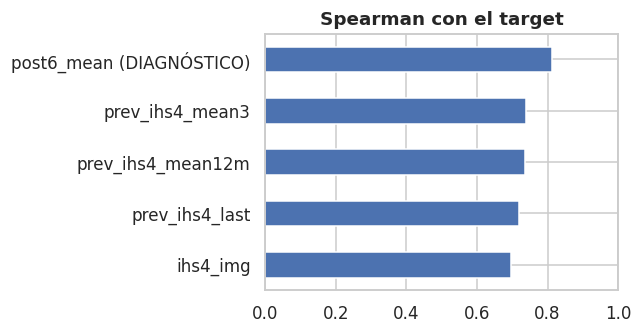

In [52]:
v_tr = D["train"]["visits"].dropna(subset=["ihs4_score"])
pairs = tr[["image_id","patient_id","capture_date"]].merge(v_tr[["patient_id","visit_date","ihs4_score"]], on="patient_id")
post = pairs[pairs.visit_date > pairs.capture_date].sort_values(["image_id","visit_date"])
post6 = post.groupby("image_id").head(6).groupby("image_id").ihs4_score.mean().rename("post6_mean (DIAGNÓSTICO)")
diag = tr.set_index("image_id")[["avg_ihs4_next6","ihs4_img","prev_ihs4_mean3","prev_ihs4_mean12m","prev_ihs4_last"]].join(post6)
c = diag.corr(method="spearman")["avg_ihs4_next6"].drop("avg_ihs4_next6")
n = diag.drop(columns="avg_ihs4_next6").notna().sum()
display(pd.DataFrame({"spearman_con_target": c.round(3), "n": n}))
fig, ax = plt.subplots(figsize=(6, 3.2))
c.sort_values().plot.barh(ax=ax, color=sns.color_palette()[0]); ax.set_title("Spearman con el target"); ax.set_xlim(0, 1)
plt.tight_layout(); plt.show()

- post6_mean (DIAGNÓSTICO) (~0.85): This is the average IHS4 score recorded during those next 6 months. Since this is essentially the target itself calculated from raw future visits, it has the highest correlation. It serves as a validation "proxy" showing that our targets match the real patient trajectory.

- ihs4_img (~0.75): This is the patient's IHS4 score at the exact moment the clinical photo was captured. It shows that a patient's current flare severity is a massive predictor of how severe their disease will remain over the next 6 months.

- prev_ihs4_mean3 (0.65) and prev_ihs4_mean12m (0.55): These are historical averages of the patient's scores. They show a moderate-to-strong positive correlation, meaning a patient's historical severity baseline continues to anchor their future disease trajectory.

## 4. Qué codifican los embeddings de imagen

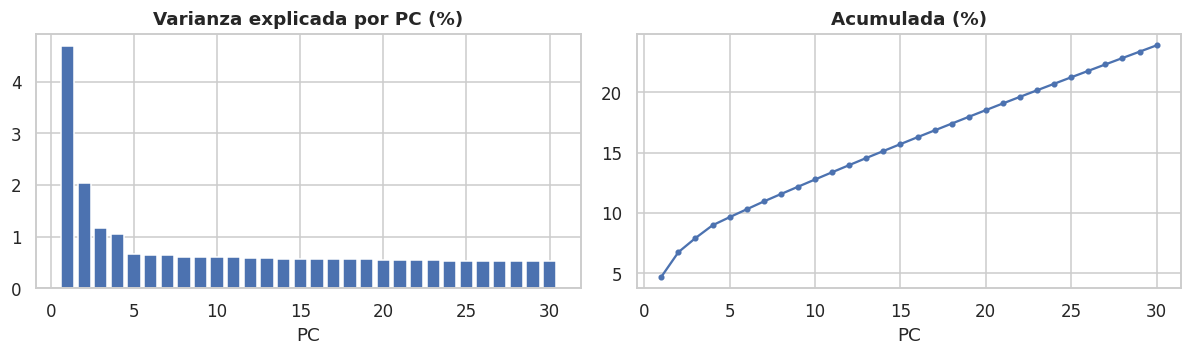

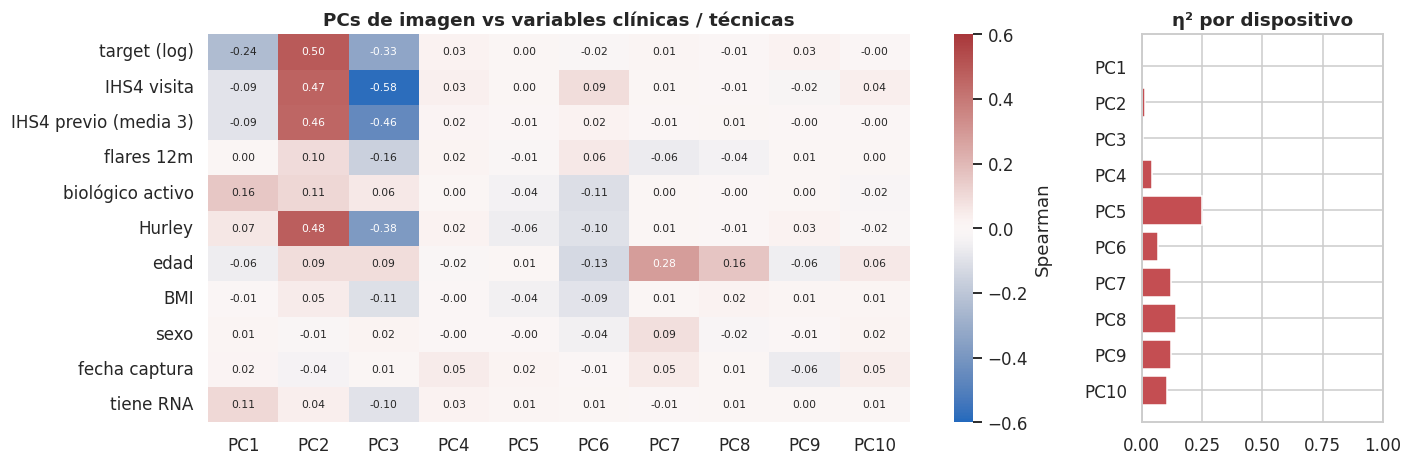

η² > 0.1 en un PC dominante = el dispositivo domina esa dirección del embedding.


In [53]:
Z = StandardScaler().fit_transform(tr[ICOLS].values)
pca = PCA(n_components=30, random_state=SEED).fit(Z)
PCs = pca.transform(Z)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].bar(range(1, 31), pca.explained_variance_ratio_ * 100, color=sns.color_palette()[0]); axes[0].set_title("Varianza explicada por PC (%)"); axes[0].set_xlabel("PC")
axes[1].plot(range(1, 31), np.cumsum(pca.explained_variance_ratio_) * 100, marker="o", ms=3); axes[1].set_title("Acumulada (%)"); axes[1].set_xlabel("PC")
plt.tight_layout(); plt.show()

K = 10
var = {"target (log)": tr["y"], "IHS4 visita": tr["ihs4_img"], "IHS4 previo (media 3)": tr["prev_ihs4_mean3"],
       "flares 12m": tr["n_flare_12m"], "biológico activo": tr["tx_biologic_active"], "Hurley": tr["hurley_stage_baseline"],
       "edad": tr["age"], "BMI": tr["bmi_at_baseline"], "sexo": tr["sex_c"], "fecha captura": tr["date_num"], "tiene RNA": tr["has_rna"]}
H = pd.DataFrame({f"PC{j+1}": [spearmanr(PCs[:, j], s, nan_policy="omit")[0] for s in var.values()] for j in range(K)}, index=var.keys())
dev_eta = [1 - np.sum([((PCs[tr.device_id == d, j] - PCs[tr.device_id == d, j].mean()) ** 2).sum() for d in tr.device_id.unique()]) /
           ((PCs[:, j] - PCs[:, j].mean()) ** 2).sum() for j in range(K)]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [4, 1.1]})
sns.heatmap(H, cmap="vlag", center=0, vmin=-0.6, vmax=0.6, annot=True, fmt=".2f", annot_kws={"size": 7}, ax=axes[0], cbar_kws={"label": "Spearman"})
axes[0].set_title("PCs de imagen vs variables clínicas / técnicas")
axes[1].barh(range(K), dev_eta, color=sns.color_palette()[3]); axes[1].set_yticks(range(K)); axes[1].set_yticklabels([f"PC{j+1}" for j in range(K)])
axes[1].invert_yaxis(); axes[1].set_title("η² por dispositivo"); axes[1].set_xlim(0, 1)
plt.tight_layout(); plt.show()
print("η² > 0.1 en un PC dominante = el dispositivo domina esa dirección del embedding.")

The image embbedings are high-dimensional vectors, representing features extracted from clinical photos. Each patient's clinical photo is assigned a coordinate or "score" alng these PCs. For instance, a high socre on PC1 means the photo features align strongly with the pattern represented bby PC1.

- __PC2__ acts as a direct indicator or driver of disease severity and active inflammation. Higher values along PC2 strongly align with worse clinical scores (such as higher IHS4 severity indices and advanced Hurley stages).

- While PC2 scales up with disease severity, __PC3 __moves inversely. It captures variance in the image data that correlates negatively with active disease severity scores, meaning lower values or specific orthogonal features captured by PC3 trend opposite to high IHS4/Hurley classifications.

Embeddings -> IHS4 de la visita (CV 5-fold, n=1851): Spearman=0.758, R²=0.543


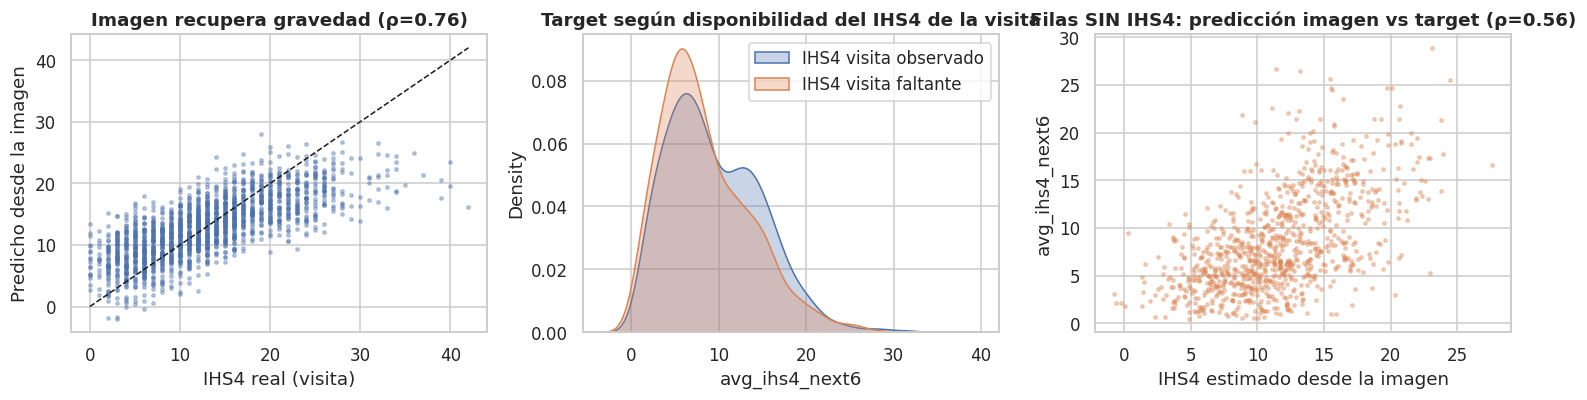

Faltante del IHS4 de visita: 33.9%. ¿Informativo? media target observado=9.49 vs faltante=8.41


In [54]:
obs = tr["ihs4_img"].notna().values
Xe = tr[ICOLS].values
oof_hat = np.full(len(tr), np.nan); miss_acc = np.zeros(len(tr)); n_f = 0
kf = KFold(5, shuffle=True, random_state=SEED)
for a, b in kf.split(np.where(obs)[0]):
    ia, ib = np.where(obs)[0][a], np.where(obs)[0][b]
    m = make_pipe = Pipeline([("sc", StandardScaler()), ("pca", PCA(60, random_state=SEED)), ("r", RidgeCV(alphas=np.logspace(-1, 5, 25)))])
    m.fit(Xe[ia], tr["ihs4_img"].values[ia])
    oof_hat[ib] = m.predict(Xe[ib]); miss_acc[~obs] += m.predict(Xe[~obs]); n_f += 1
oof_hat[~obs] = miss_acc[~obs] / n_f
tr["ihs4_img_hat"] = oof_hat
tr["ihs4_img_filled"] = np.where(obs, tr["ihs4_img"], oof_hat)
tr["ihs4_img_obs"] = obs.astype(int)

rho = spearmanr(tr.loc[obs, "ihs4_img"], oof_hat[obs])[0]
r2 = 1 - ((tr.loc[obs, "ihs4_img"] - oof_hat[obs]) ** 2).sum() / ((tr.loc[obs, "ihs4_img"] - tr.loc[obs, "ihs4_img"].mean()) ** 2).sum()
print(f"Embeddings -> IHS4 de la visita (CV 5-fold, n={obs.sum()}): Spearman={rho:.3f}, R²={r2:.3f}")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
axes[0].scatter(tr.loc[obs, "ihs4_img"], oof_hat[obs], s=5, alpha=0.35); lim = [0, tr.ihs4_img.max()]
axes[0].plot(lim, lim, "k--", lw=1); axes[0].set_xlabel("IHS4 real (visita)"); axes[0].set_ylabel("Predicho desde la imagen"); axes[0].set_title(f"Imagen recupera gravedad (ρ={rho:.2f})")
sns.kdeplot(tr.loc[obs, "avg_ihs4_next6"], ax=axes[1], label="IHS4 visita observado", fill=True, alpha=.3)
sns.kdeplot(tr.loc[~obs, "avg_ihs4_next6"], ax=axes[1], label="IHS4 visita faltante", fill=True, alpha=.3)
axes[1].set_title("Target según disponibilidad del IHS4 de la visita"); axes[1].set_xlabel("avg_ihs4_next6"); axes[1].legend()
axes[2].scatter(tr.loc[~obs, "ihs4_img_hat"], tr.loc[~obs, "avg_ihs4_next6"], s=5, alpha=.35, color=sns.color_palette()[1])
rm_ = spearmanr(tr.loc[~obs, "ihs4_img_hat"], tr.loc[~obs, "avg_ihs4_next6"])[0]
axes[2].set_title(f"Filas SIN IHS4: predicción imagen vs target (ρ={rm_:.2f})"); axes[2].set_xlabel("IHS4 estimado desde la imagen"); axes[2].set_ylabel("avg_ihs4_next6")
plt.tight_layout(); plt.show()
print(f"Faltante del IHS4 de visita: {(~obs).mean():.1%}. ¿Informativo? media target observado={tr.loc[obs,'avg_ihs4_next6'].mean():.2f} vs faltante={tr.loc[~obs,'avg_ihs4_next6'].mean():.2f}")

A scatter plot comparing the Real IHS4 (visita) on the x-axis against the Predicted value from the image on the y-axis. There is a strong positive correlation (ρ=0.76) between what the clinical score actually is and what the image features predict. This demonstrates that the image-based model does a robust job of recovering or estimating the patient's actual disease severity.

Density distribution curves comparing cases where the visit IHS4 score was observed (blue) versus where it was missing/faulty (orange) against avg_ihs4_next6.   
image_ef938c.png
The two distributions align very closely. This suggests that the data points with missing IHS4 scores do not suffer from a severe structural bias compared to the observed ones, validating the use of imputation or predictions for missing visits.

A scatter plot for rows without an actual recorded IHS4 visit score, mapping the image-estimated IHS4 against subsequent target metrics (avg_ihs4_next6).   
image_ef938c.png
Even in cases where the true physical visit score is missing, the image-derived estimate maintains a meaningful positive correlation (ρ=0.56) with future outcomes (avg_ihs4_next6), proving that the images can be reliably used to predict or fill in missing clinical trajectories.

## 6. Valor incremental: ¿qué añaden las imágenes al baseline tabular?

Mismo CV (5-fold × 2 repeticiones, mismos folds), modelo gradient boosting, target `log1p(avg_ihs4_next6)`.
Todo lo aprendido de las imágenes (PCA, armonización por dispositivo, vecinos kNN con su target) se ajusta
**dentro de cada fold**; el kNN usa *leave-self-out* en train para que no se vea a sí mismo.

In [55]:
class ImgBlock(BaseEstimator, TransformerMixin):
    def __init__(self, icols, harmonize=False, n_pc=20):
        self.icols, self.harmonize, self.n_pc = icols, harmonize, n_pc
    def _dm(self, X, Z):
        Z = Z.copy()
        for k, m in self.dev_means_.items():
            msk = (X["device_id"] == k).values; Z[msk] = Z[msk] - m + self.mu_
        return Z
    def fit(self, X, y=None):
        Z = X[self.icols].values.astype(float); self.mu_ = Z.mean(0)
        if self.harmonize:
            self.dev_means_ = {k: Z[(X["device_id"] == k).values].mean(0) for k in X["device_id"].unique()}
            Z = self._dm(X, Z)
        self.sc_ = StandardScaler().fit(Z); self.pca_ = PCA(self.n_pc, random_state=SEED).fit(self.sc_.transform(Z)); return self
    def transform(self, X):
        Z = X[self.icols].values.astype(float)
        if self.harmonize: Z = self._dm(X, Z)
        return self.pca_.transform(self.sc_.transform(Z))

class Assembler(BaseEstimator, TransformerMixin):
    def __init__(self, tab_cols, icols, use_pcs=False, harmonize=False, n_pc=20, use_knn=False, k=30):
        self.tab_cols, self.icols, self.use_pcs, self.harmonize = tab_cols, icols, use_pcs, harmonize
        self.n_pc, self.use_knn, self.k = n_pc, use_knn, k
    def _knn(self, E, exclude_self):
        kk = self.k + (1 if exclude_self else 0)
        _, ind = self.nn_.kneighbors(E, n_neighbors=kk)
        if exclude_self: ind = ind[:, 1:]
        Y = self.y_[ind]; return np.c_[Y.mean(1), Y.std(1)]
    def fit(self, X, y=None):
        if self.use_pcs: self.blk_ = ImgBlock(self.icols, self.harmonize, self.n_pc).fit(X)
        if self.use_knn:
            E = X[self.icols].values.astype(float); E = E / np.linalg.norm(E, axis=1, keepdims=True)
            self.y_ = np.asarray(y); self.nn_ = NearestNeighbors(metric="cosine", algorithm="brute").fit(E)
        return self
    def _build(self, X, knn):
        parts = [X[self.tab_cols].values.astype(float)]
        if self.use_pcs: parts.append(self.blk_.transform(X))
        if self.use_knn: parts.append(knn)
        return np.hstack(parts)
    def fit_transform(self, X, y=None, **kw):
        self.fit(X, y)
        knn = None
        if self.use_knn:
            E = X[self.icols].values.astype(float); E = E / np.linalg.norm(E, axis=1, keepdims=True); knn = self._knn(E, True)
        return self._build(X, knn)
    def transform(self, X):
        knn = None
        if self.use_knn:
            E = X[self.icols].values.astype(float); E = E / np.linalg.norm(E, axis=1, keepdims=True); knn = self._knn(E, False)
        return self._build(X, knn)

def make_model(tab_cols, **kw):
    return Pipeline([("fe", Assembler(tab_cols, ICOLS, **kw)),
                     ("m", HistGradientBoostingRegressor(max_iter=250, learning_rate=0.04, max_depth=4, min_samples_leaf=25,
                                                         l2_regularization=2.0, random_state=SEED))])

def oof_cv(d, make, reps=REPS):
    y, acc, cnt = d["y"].values, np.zeros(len(d)), np.zeros(len(d))
    for r in range(reps):
        for a, b in KFold(5, shuffle=True, random_state=r).split(d):
            m = make().fit(d.iloc[a], y[a]); acc[b] += m.predict(d.iloc[b]); cnt[b] += 1
    return acc / cnt

def metr(y, p):
    return dict(spearman=spearmanr(y, p)[0], rmse=float(np.sqrt(np.mean((y - p) ** 2))), r2=1 - ((y - p) ** 2).sum() / ((y - y.mean()) ** 2).sum())

def boot_delta(y, pa, pb, B=BOOT, seed=0):
    f = lambda i: (spearmanr(y[i], pb[i])[0] - spearmanr(y[i], pa[i])[0],
                   np.sqrt(np.mean((y[i] - pa[i]) ** 2)) - np.sqrt(np.mean((y[i] - pb[i]) ** 2)))
    rng, n = np.random.default_rng(seed), len(y); pt = f(np.arange(n))
    bs = np.array([f(rng.integers(0, n, n)) for _ in range(B)]); lo, hi = np.percentile(bs, [2.5, 97.5], axis=0)
    return pt, lo, hi

In [56]:
CONFIGS = {
    "1 tabular (baseline)":              (TAB, {}),
    "2 + IHS4 de la visita":             (TAB + ["ihs4_img"], {}),
    "3 + imagen (PCs)":                  (TAB, dict(use_pcs=True)),
    "4 + IHS4 visita + imagen (PCs)":    (TAB + ["ihs4_img"], dict(use_pcs=True)),
    "5 + IHS4 relleno desde imagen":     (TAB + ["ihs4_img_filled", "ihs4_img_obs"], {}),
    "6 + relleno + PCs":                 (TAB + ["ihs4_img_filled", "ihs4_img_obs"], dict(use_pcs=True)),
    "7 + relleno + PCs armonizados":     (TAB + ["ihs4_img_filled", "ihs4_img_obs"], dict(use_pcs=True, harmonize=True)),
    "8 + relleno + kNN-target":          (TAB + ["ihs4_img_filled", "ihs4_img_obs"], dict(use_knn=True)),
    "9 + relleno + PCs + kNN-target":    (TAB + ["ihs4_img_filled", "ihs4_img_obs"], dict(use_pcs=True, use_knn=True)),
    "sonda: tabular + dispositivo + fecha": (TAB + ["device_id", "date_num"], {}),
}
OOF = {name: oof_cv(tr, lambda cols=cols, kw=kw: make_model(cols, **kw)) for name, (cols, kw) in CONFIGS.items()}
y = tr["y"].values
res = pd.DataFrame({n: metr(y, p) for n, p in OOF.items()}).T.round(3)
display(res)

,spearman,rmse,r2
1 tabular (baseline),0.803,0.357,0.625
2 + IHS4 de la visita,0.805,0.354,0.630
3 + imagen (PCs),0.843,0.324,0.690
4 + IHS4 visita + imagen (PCs),0.846,0.322,0.694
5 + IHS4 relleno desde imagen,0.813,0.349,0.640
6 + relleno + PCs,0.847,0.320,0.697
7 + relleno + PCs armonizados,0.848,0.321,0.697
8 + relleno + kNN-target,0.849,0.319,0.700
9 + relleno + PCs + kNN-target,0.848,0.320,0.699
sonda: tabular + dispositivo + fecha,0.804,0.356,0.625


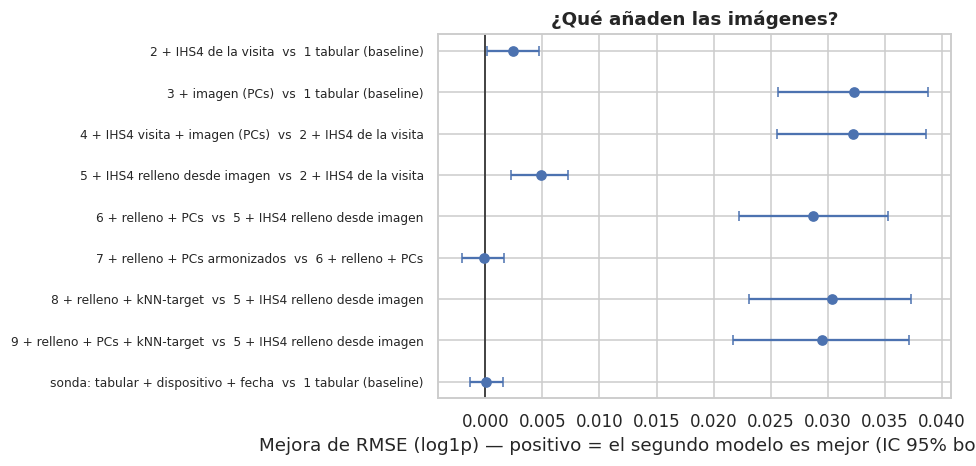

,comparación,mejora_rmse,lo,hi,d_spearman,sp_lo,sp_hi,sig
0,2 + IHS4 de la visita vs 1 tabular (baseline),0.002,0.000,0.005,0.002,-0.001,0.006,*
1,3 + imagen (PCs) vs 1 tabular (baseline),0.032,0.026,0.039,0.041,0.031,0.050,*
2,4 + IHS4 visita + imagen (PCs) vs 2 + IHS4 d...,0.032,0.026,0.039,0.041,0.032,0.050,*
3,5 + IHS4 relleno desde imagen vs 2 + IHS4 de...,0.005,0.002,0.007,0.008,0.004,0.012,*
4,6 + relleno + PCs vs 5 + IHS4 relleno desde ...,0.029,0.022,0.035,0.034,0.027,0.043,*
5,7 + relleno + PCs armonizados vs 6 + relleno...,-0.000,-0.002,0.002,0.001,-0.002,0.003,
6,8 + relleno + kNN-target vs 5 + IHS4 relleno...,0.030,0.023,0.037,0.036,0.027,0.045,*
7,9 + relleno + PCs + kNN-target vs 5 + IHS4 r...,0.029,0.022,0.037,0.035,0.026,0.044,*
8,sonda: tabular + dispositivo + fecha vs 1 ta...,0.000,-0.001,0.002,0.001,-0.002,0.003,


In [57]:
pairs_ = [("1 tabular (baseline)", "2 + IHS4 de la visita"), ("1 tabular (baseline)", "3 + imagen (PCs)"),
          ("2 + IHS4 de la visita", "4 + IHS4 visita + imagen (PCs)"), ("2 + IHS4 de la visita", "5 + IHS4 relleno desde imagen"),
          ("5 + IHS4 relleno desde imagen", "6 + relleno + PCs"), ("6 + relleno + PCs", "7 + relleno + PCs armonizados"),
          ("5 + IHS4 relleno desde imagen", "8 + relleno + kNN-target"), ("5 + IHS4 relleno desde imagen", "9 + relleno + PCs + kNN-target"),
          ("1 tabular (baseline)", "sonda: tabular + dispositivo + fecha")]
rows = []
for a, b in pairs_:
    pt, lo, hi = boot_delta(y, OOF[a], OOF[b])
    rows.append(dict(comparación=f"{b}  vs  {a}", mejora_rmse=pt[1], lo=lo[1], hi=hi[1], d_spearman=pt[0], sp_lo=lo[0], sp_hi=hi[0]))
DEL = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(9, 4.4))
yy = np.arange(len(DEL))[::-1]
ax.errorbar(DEL.mejora_rmse, yy, xerr=[DEL.mejora_rmse - DEL.lo, DEL.hi - DEL.mejora_rmse], fmt="o", capsize=3, color=sns.color_palette()[0])
ax.axvline(0, color="k", lw=1); ax.set_yticks(yy); ax.set_yticklabels(DEL["comparación"], fontsize=8)
ax.set_xlabel("Mejora de RMSE (log1p) — positivo = el segundo modelo es mejor (IC 95% bootstrap pareado)"); ax.set_title("¿Qué añaden las imágenes?")
plt.tight_layout(); plt.show()
display(DEL.assign(sig=lambda d: np.where((d.lo > 0) | (d.hi < 0), "*", "")).round(3))

**Cómo leerlo.** `2 vs 1` mide cuánto vale conocer el IHS4 de la visita; `3 vs 1` cuánto aportan los embeddings
*sin* ese dato; `4 vs 2` y `6 vs 5` cuánto añaden los PCs de imagen cuando ya se conoce (o se estimó) la gravedad actual;
`7 vs 6` si armonizar por dispositivo ayuda; `8/9` si los vecinos en el espacio de imagen aportan información del target;
la **sonda** (`dispositivo + fecha`) debe quedarse cerca de 0: si no, hay un atajo técnico.


- 2 + IHS4 de la visita  vs  1 tabular (baseline) (≈+0.002)
¿Qué compara?: Modelo con datos básicos + IHS4 real DE HOY vs. Modelo solo con datos básicos.   

¿Qué significa?: Saber el IHS4 actual ayuda un poquitín (está ligeramente a la derecha del 0).   

- 3 + imagen (PCs)  vs  1 tabular (baseline) (≈+0.032)
¿Qué compara?: Usar la foto (embeddings/PCs) vs. No usar la foto.   

¿Qué significa?: ¡Gran salto! La foto por sí sola le quita muchísimo error al modelo. Es muchísimo mejor que solo tener datos de ficha (tabulares).   


- 4 + IHS4 visita + imagen (PCs)  vs  2 + IHS4 de la visita (≈+0.032)
¿Qué compara?: Si ya tengo el IHS4 real de hoy, ¿sirve de algo añadir la foto?   

¿Qué significa?: Sí, y mucho. Aunque el médico ya haya medido el IHS4, la foto aporta información visual extra que el número del IHS4 no capta.   


- 5 + IHS4 relleno desde imagen  vs  2 + IHS4 de la visita (≈+0.005)
¿Qué compara?: Si me falta el IHS4 de hoy y lo adivino usando la foto, ¿qué tal?   
image_ef2a4e.png
¿Qué significa?: Funciona ligeramente mejor que no tenerlo (mejora pequeña).   

- 6 + relleno + PCs  vs  5 + IHS4 relleno desde imagen (≈+0.029)
¿Qué compara?: Además de adivinar el IHS4 con la foto, ¿vale la pena meter las características completas (PCs) de la foto?   
image_ef2a4e.png
¿Qué significa?: Sí. Demuestra de nuevo que reducir la foto a un solo número (IHS4) destruye información útil. Las PCs completas le quitan casi 0.03 de error extra.   

- 7 + relleno + PCs armonizados  vs  6 + relleno + PCs (≈0.000)
¿Qué compara?: ¿Mejora si corregimos las fotos según la cámara que se usó?   
image_ef2a4e.png
¿Qué significa?: El punto cae justo en la línea del 0. No cambia nada, no aporta mejora.   

- 8 y 9 (kNN-target) (≈+0.030)
¿Qué significa?: Buscar "pacientes con fotos parecidas" en la base de datos e imitar su resultado también ayuda casi tanto como usar las PCs de la imagen directamente.   

- sonda: tabular + dispositivo + fecha (≈0.000)
¿Qué significa?: Es un control de calidad. Está en el 0, lo cual confirma que el modelo no se está "haciendo trampas" adivinando cosas por la marca del móvil o la fecha de la foto.   
image_ef2a4e.png

## 7. ¿Para quién aportan las imágenes?

Mejora de RMSE (OOF) del mejor modelo con imagen frente al modelo tabular + IHS4 de la visita, por subgrupo.
Un promedio pequeño puede esconder un grupo donde la imagen ayuda mucho (o perjudica).

,grupo,n,rmse_ref,rmse_img,mejora,rho_ref,rho_img
5,Hurley: H1,360,0.386,0.399,-0.013,0.392,0.351
20,dispositivo: dev5,278,0.334,0.321,0.013,0.750,0.790
3,edad: mayor,928,0.318,0.302,0.016,0.826,0.851
7,Hurley: H3,841,0.240,0.217,0.023,0.539,0.633
18,tiene RNA: no,2200,0.341,0.315,0.026,0.829,0.859
11,IHS4 visita: observado,1851,0.342,0.316,0.026,0.819,0.851
14,año captura: reciente,931,0.331,0.305,0.026,0.826,0.857
16,flares 12m: 1-2,1433,0.332,0.305,0.028,0.819,0.854
8,biológico: activo,1583,0.311,0.283,0.028,0.827,0.857
1,sexo: M,720,0.338,0.309,0.029,0.827,0.862


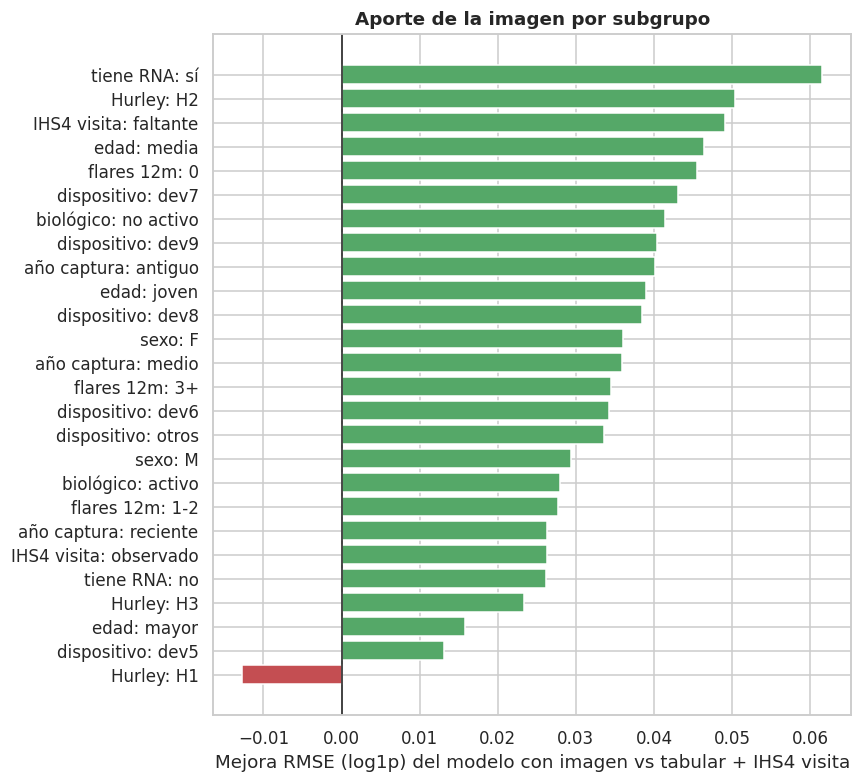

In [58]:
BEST = "9 + relleno + PCs + kNN-target"; REF = "2 + IHS4 de la visita"
g = tr[["sex_c","age","hurley_stage_baseline","tx_biologic_active","ihs4_img_obs","device_id","date_num","has_rna","n_flare_12m"]].copy()
g["sexo"] = g.sex_c.map({0: "F", 1: "M"})
g["edad"] = pd.qcut(g.age, 3, labels=["joven","media","mayor"]).astype(str)
g["Hurley"] = "H" + g.hurley_stage_baseline.astype(int).astype(str)
g["biológico"] = np.where(g.tx_biologic_active == 1, "activo", "no activo")
g["IHS4 visita"] = np.where(g.ihs4_img_obs == 1, "observado", "faltante")
g["año captura"] = pd.qcut(g.date_num, 3, labels=["antiguo","medio","reciente"]).astype(str)
g["flares 12m"] = pd.cut(g.n_flare_12m, [-1, 0, 2, 100], labels=["0","1-2","3+"]).astype(str)
g["tiene RNA"] = np.where(g.has_rna == 1, "sí", "no")
top = g.device_id.value_counts().index[:5]; g["dispositivo"] = np.where(g.device_id.isin(top), "dev" + g.device_id.astype(str), "otros")
rows = []
for var_ in ["sexo","edad","Hurley","biológico","IHS4 visita","año captura","flares 12m","tiene RNA","dispositivo"]:
    for val, idx in g.groupby(var_).indices.items():
        if len(idx) < 40: continue
        a, b = OOF[REF][idx], OOF[BEST][idx]; yy_ = y[idx]
        rows.append(dict(grupo=f"{var_}: {val}", n=len(idx), rmse_ref=np.sqrt(np.mean((yy_ - a) ** 2)), rmse_img=np.sqrt(np.mean((yy_ - b) ** 2)),
                         mejora=np.sqrt(np.mean((yy_ - a) ** 2)) - np.sqrt(np.mean((yy_ - b) ** 2)),
                         rho_ref=spearmanr(yy_, a)[0], rho_img=spearmanr(yy_, b)[0]))
SG = pd.DataFrame(rows).sort_values("mejora")
display(SG.round(3))
fig, ax = plt.subplots(figsize=(8, max(3.5, 0.28 * len(SG))))
ax.barh(SG.grupo, SG.mejora, color=[sns.color_palette()[2] if m > 0 else sns.color_palette()[3] for m in SG.mejora])
ax.axvline(0, color="k", lw=1); ax.set_xlabel("Mejora RMSE (log1p) del modelo con imagen vs tabular + IHS4 visita"); ax.set_title("Aporte de la imagen por subgrupo")
plt.tight_layout(); plt.show()

- tiene RNA: sí (~0.061): Patients with RNA sequencing data benefit the most when image features are included.   

- Hurley: H2 (~0.050): Moderate disease stage patients see a massive boost from image data. Images help nuance borderline cases between mild and severe.   

- IHS4 visita: faltante (~0.049): Crucial finding. When the physical clinical score (IHS4) is missing for a visit, the image steps in and effectively fills the gap, reducing error significantly.   

HOWEVERRRR!!

- Hurley: H1 (Red bar, ~ -0.013): For mild disease (Hurley Stage 1), adding images slightly worsens performance. Mild lesions can introduce visual noise without adding useful predictive signal compared to basic tabular features.

## 8. Shift entre train y test

Los test no tienen target, pero sí imágenes y contexto. Comparo qué tan distintos son de train: AUC de un clasificador
adversarial (0.5 = indistinguibles) sobre embeddings y sobre variables tabulares, y distribuciones clave.

,AUC_embeddings,AUC_tabular,AUC_dispositivo_fecha
test,,,
test_1,0.480,0.523,0.460
test_2,0.501,0.706,0.491


,n,ihs4_visita_faltante,biologico_activo,edad_media,tiene_RNA,flares_12m,ihs4_previo,años_dx
split,,,,,,,,
test_1,600,0.337,0.540,30.647,0.333,1.522,11.572,2.716
test_2,600,0.502,0.530,28.860,0.333,1.405,12.580,2.648
train,2800,0.339,0.565,31.024,0.214,1.559,11.375,2.837


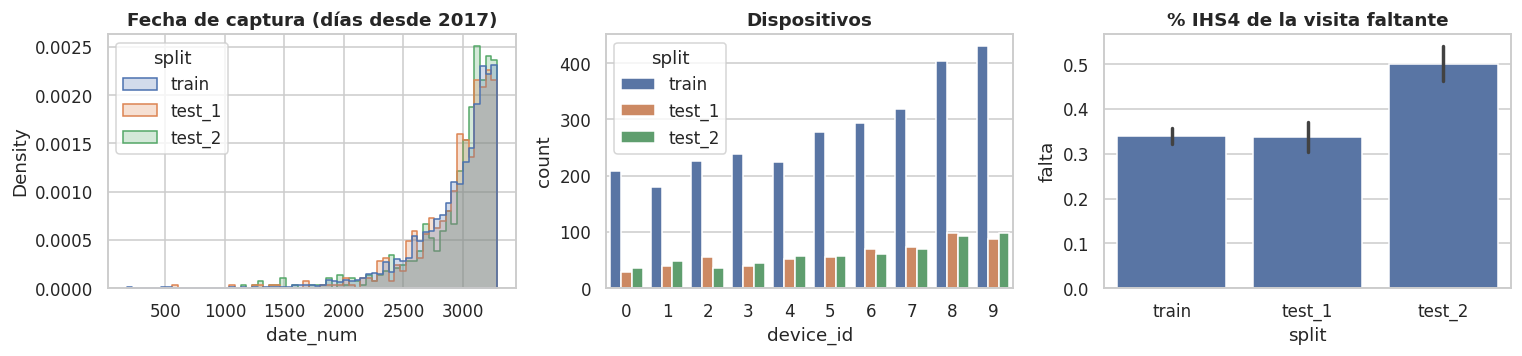

In [59]:
def adv_auc(Xa, lab, model="hgb"):
    clf = HistGradientBoostingClassifier(max_iter=150, learning_rate=0.06, max_depth=3, random_state=SEED)
    p = cross_val_predict(clf, Xa, lab, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]
    return roc_auc_score(lab, p)

rows = []
for ts in ["test_1", "test_2"]:
    d = IDX[IDX.split.isin(["train", ts])].reset_index(drop=True); lab = (d.split == ts).astype(int).values
    Zp = PCA(20, random_state=SEED).fit_transform(StandardScaler().fit_transform(d[ICOLS].values))
    rows.append(dict(test=ts, AUC_embeddings=adv_auc(Zp, lab), AUC_tabular=adv_auc(d[TAB + ["ihs4_img"]].values.astype(float), lab),
                     AUC_dispositivo_fecha=adv_auc(d[["device_id", "date_num"]].values.astype(float), lab)))
display(pd.DataFrame(rows).set_index("test").round(3))

cmp = IDX.groupby("split").agg(n=("image_id", "size"), ihs4_visita_faltante=("ihs4_img", lambda s: s.isna().mean()),
                               biologico_activo=("tx_biologic_active", "mean"), edad_media=("age", "mean"), tiene_RNA=("has_rna", "mean"),
                               flares_12m=("n_flare_12m", "mean"), ihs4_previo=("prev_ihs4_mean3", "mean"), años_dx=("years_since_dx", "mean")).round(3)
display(cmp)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
sns.histplot(data=IDX, x="date_num", hue="split", element="step", stat="density", common_norm=False, ax=axes[0]); axes[0].set_title("Fecha de captura (días desde 2017)")
sns.countplot(data=IDX, x="device_id", hue="split", ax=axes[1]); axes[1].set_title("Dispositivos")
sns.barplot(data=IDX.assign(falta=IDX.ihs4_img.isna().astype(int)), x="split", y="falta", ax=axes[2]); axes[2].set_title("% IHS4 de la visita faltante")
plt.tight_layout(); plt.show()

Si algún test se distingue claramente de train (AUC alto) o cambia la proporción de IHS4 faltante, un modelo que dependa
de `ihs4_img` o de PCs sensibles a dispositivo rendirá peor ahí; conviene preferir las variantes robustas
(relleno desde imagen, PCs armonizados) y validar con CV temporal.

## 9. Columnas nuevas para el modelo

Genero por imagen: `img_pc01..10` (raw y armonizados), `ihs4_img_hat`, `ihs4_img_filled`, `ihs4_img_obs` y
`knn_y_mean / knn_y_std`. **Train:** versiones fuera de muestra (OOF / leave-self-out). **Test:** modelos ajustados con todo
train. Las exporto a `hs_images_out/` junto con las variables tabulares de contexto.

train: 2800 filas x 71 columnas -> hs_images_out/image_features_train.csv
test_1: 600 filas x 71 columnas -> hs_images_out/image_features_test_1.csv
test_2: 600 filas x 71 columnas -> hs_images_out/image_features_test_2.csv


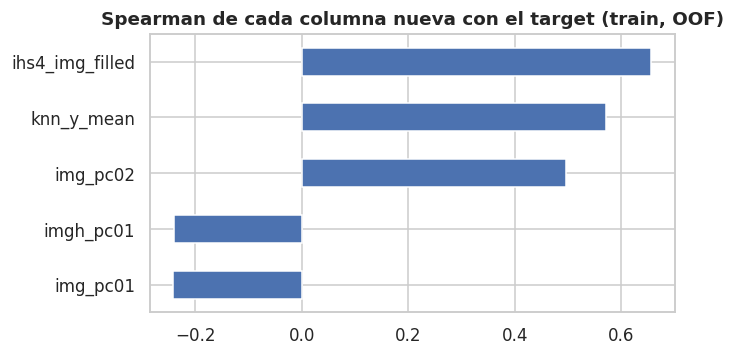

In [60]:
# --- modelo imagen -> IHS4 visita ajustado con todo train (para test)
obs = tr["ihs4_img"].notna().values
full_hat = Pipeline([("sc", StandardScaler()), ("pca", PCA(60, random_state=SEED)), ("r", RidgeCV(alphas=np.logspace(-1, 5, 25)))]).fit(tr.loc[obs, ICOLS].values, tr.loc[obs, "ihs4_img"].values)

# --- bloques de imagen y kNN con todo train
blk_raw = ImgBlock(ICOLS, harmonize=False, n_pc=10).fit(tr)
blk_har = ImgBlock(ICOLS, harmonize=True, n_pc=10).fit(tr)
knn = Assembler(TAB, ICOLS, use_knn=True, k=30).fit(tr, tr["y"].values)

def export(d, is_train):
    o = d[["image_id", "patient_id", "split", "device_id", "date_num", "has_rna", "ihs4_img"]].copy()
    if is_train:
        o["ihs4_img_hat"], o["ihs4_img_filled"] = d["ihs4_img_hat"].values, d["ihs4_img_filled"].values
        E = d[ICOLS].values / np.linalg.norm(d[ICOLS].values, axis=1, keepdims=True)
        kf_ = knn._knn(E, True)
    else:
        o["ihs4_img_hat"] = full_hat.predict(d[ICOLS].values)
        o["ihs4_img_filled"] = np.where(d["ihs4_img"].notna(), d["ihs4_img"], o["ihs4_img_hat"])
        E = d[ICOLS].values / np.linalg.norm(d[ICOLS].values, axis=1, keepdims=True)
        kf_ = knn._knn(E, False)
    o["ihs4_img_obs"] = d["ihs4_img"].notna().astype(int).values
    o["knn_y_mean"], o["knn_y_std"] = kf_[:, 0], kf_[:, 1]
    A, B = blk_raw.transform(d), blk_har.transform(d)
    for j in range(A.shape[1]):
        o[f"img_pc{j+1:02d}"], o[f"imgh_pc{j+1:02d}"] = A[:, j], B[:, j]
    return pd.concat([o.reset_index(drop=True), d[TAB].reset_index(drop=True)], axis=1)

for s in SPLITS:
    d = tr if s == "train" else IDX[IDX.split == s].reset_index(drop=True)
    e = export(d, s == "train"); e.to_csv(OUT / f"image_features_{s}.csv", index=False)
    print(f"{s}: {e.shape[0]} filas x {e.shape[1]} columnas -> {OUT / f'image_features_{s}.csv'}")
ex = pd.read_csv(OUT / "image_features_train.csv")
fig, ax = plt.subplots(figsize=(6.4, 3.4))
ex[["ihs4_img_filled","knn_y_mean","img_pc01","imgh_pc01","img_pc02"]].join(tr["y"]).corr(method="spearman")["y"].drop("y").sort_values().plot.barh(ax=ax)
ax.set_title("Spearman de cada columna nueva con el target (train, OOF)"); plt.tight_layout(); plt.show()

nuevas columnas creadas a partir de las imágenes

- ihs4_img_filled (Correlación alta ≈0.65):
Es la variable con mayor correlación positiva. Al combinar el IHS4 real cuando está disponible y rellenarlo (filled) con la estimación de la imagen cuando falta, se crea una métrica muy potente y robusta directamente alineada con el target.


- knn_y_mean (Correlación alta ≈0.57):
Corresponde a la media del target de los pacientes vecinos más cercanos (kNN) en el espacio de la imagen. Demuestra que buscar casos visualmente similares en el conjunto de entrenamiento es una excelente estrategia predictiva.

- img_pc02 (Correlación positiva ≈0.49): PC2 actúa como un fuerte conductor (driver) directo de la gravedad de la enfermedad.

### Summary of the image exploration (English)

- Images come only from **flare visits**; 34% of them have no IHS4 recorded at that visit.
- The image embedding recovers the visit IHS4 well (Spearman 0.76, R² 0.54), so it can **fill the missing visit scores**.
- Against a model built *at the photo date*, images add a clear, significant gain (log-RMSE 0.355 → 0.319). Device + capture date alone add nothing (no technical shortcut), and harmonising by device changes little.
- The images help most where the clinical record is thin: visit score missing, no recent flares, Hurley 2, RNAseq patients.
- test_2 is distinguishable from train on the **tabular** variables (adversarial AUC 0.71) but **not** on the embeddings (0.51).

How this fits with the next section: when the comparison is against a strong model built at **31 Dec 2025** (full visit history), the overall image gain disappears. The image mostly re-encodes the severity that the visit history already captures. The full exercise 3 analysis below quantifies this and finds where images and RNAseq really help.

# Exercise 3 — Part 2:

In [61]:
import os, sys, json, warnings, numpy as np, pandas as pd
warnings.filterwarnings('ignore')
DATA_DIR = BASE              # same data folder as the rest of our notebook
OUT_DIR  = "outputs"; os.makedirs(OUT_DIR, exist_ok=True)
TEAM     = "teamName"        # <-- your team name for the answer files
RUN_ABLATION = True          # section 3 (slow, ~5 min)
RUN_CREATIVE = False         # section 3b: Kalman / clusters / etc. (slow; I already tested them: no lift)
SEED = 0
rng = np.random.default_rng(SEED)

In [62]:
%%writefile hs_features.py
"""Feature engineering for the HS-RWE challenge. Everything is computed from data <= CUTOFF."""
import numpy as np, pandas as pd

CUTOFF = pd.Timestamp("2025-12-31")
ROOT = "public"  # overwritten from the notebook (H.ROOT = DATA_DIR)


def load(split):
    r = lambda f, **k: pd.read_csv(f"{ROOT}/{split}/{f}.csv", **k)
    d = dict(
        dem=r("demographics", parse_dates=["symptom_onset_date", "diagnosis_date"]),
        asg=r("patient_assignment"),
        vis=r("visits", parse_dates=["visit_date"]),
        trt=r("treatments", parse_dates=["start_date", "end_date"]),
        sur=r("surgeries", parse_dates=["procedure_date"]),
        img=r("images_metadata", parse_dates=["capture_date"]),
        rna=r("rnaseq_metadata", parse_dates=["collection_date"]),
        imge=r("images_embeddings"),
        rnae=r("rnaseq_embeddings"),
    )
    try:
        d["tgt"] = r("targets")
    except FileNotFoundError:
        d["tgt"] = None
    return d


# ---------------------------------------------------------------- demographics
def demo_features(dem, asg):
    X = dem.merge(asg, on="patient_id", how="left").set_index("patient_id")
    # 1) recover missing dates from the (exactly consistent) delay / diagnosis date
    est_onset = (X.diagnosis_date - pd.to_timedelta((X.diagnostic_delay_years * 365.25).round(), unit="D")).astype("datetime64[ns]")
    onset = X.symptom_onset_date.astype("datetime64[ns]").fillna(est_onset)
    est_delay = (X.diagnosis_date - X.symptom_onset_date).dt.days / 365.25
    delay = X.diagnostic_delay_years.fillna(est_delay)
    X["onset_recovered"] = onset
    X["delay_filled"] = delay
    X["delay_was_missing_both"] = delay.isna().astype(int)
    for c in ["bmi_at_baseline", "smoking_status", "ethnicity", "family_history_hs"]:
        X[f"miss_{c}"] = X[c].isna().astype(int)
    X["n_missing_demo"] = X[[c for c in X.columns if c.startswith("miss_")]].sum(1) + X.delay_was_missing_both
    X["age_now"] = 2025 - X.birth_year
    X["yrs_since_dx"] = (CUTOFF - X.diagnosis_date).dt.days / 365.25
    X["yrs_since_onset"] = (CUTOFF - X.onset_recovered).dt.days / 365.25
    X["dx_year"] = X.diagnosis_date.dt.year
    X["bmi_cat"] = pd.cut(X.bmi_at_baseline, [0, 18.5, 25, 30, 35, 100], labels=False)
    for c in ["sex", "ethnicity", "smoking_status", "family_history_hs"]:
        X[c] = X[c].astype("category")
    X["male"] = (X.sex == "Male").astype(int)
    X["hurley_x_smoke"] = X.hurley_stage_baseline * (X.smoking_status == "Current").astype(float)
    return X.drop(columns=["symptom_onset_date", "diagnosis_date", "diagnostic_delay_years"])


# ---------------------------------------------------------------- visits
def _ewm(v, hl):
    w = 0.5 ** (v.age / hl)
    g = pd.DataFrame({"ws": w * v.ihs4_score, "w": w, "pid": v.patient_id}).groupby("pid")
    s = g.sum()
    return (s.ws / s.w), s.w


def visit_features(vis, ids):
    v = vis.copy()
    v["age"] = (CUTOFF - v.visit_date).dt.days
    sc = v[v.ihs4_score.notna()]
    F = pd.DataFrame(index=ids)
    g = v.groupby("patient_id")
    F["n_vis"] = g.size()
    F["n_scored"] = sc.groupby("patient_id").size()
    F["share_scored"] = F.n_scored / F.n_vis
    F["days_since_last_vis"] = g.age.min()
    F["days_since_first_vis"] = g.age.max()
    F["vis_per_year"] = F.n_vis / (F.days_since_first_vis.clip(lower=90) / 365.25)
    F["days_since_last_scored"] = sc.groupby("patient_id").age.min()
    # recency windows
    for w in [30, 90, 180, 365, 730]:
        a = v[v.age <= w].groupby("patient_id")
        s = sc[sc.age <= w].groupby("patient_id").ihs4_score
        F[f"n_vis_{w}"] = a.size()
        F[f"sc_mean_{w}"] = s.mean()
        F[f"sc_max_{w}"] = s.max()
        F[f"sc_std_{w}"] = s.std()
        F[f"sc_n_{w}"] = s.size()
    F["sc_mean_all"] = sc.groupby("patient_id").ihs4_score.mean()
    F["sc_median_all"] = sc.groupby("patient_id").ihs4_score.median()
    F["sc_min_all"] = sc.groupby("patient_id").ihs4_score.min()
    F["sc_q10"] = sc.groupby("patient_id").ihs4_score.quantile(.1)
    F["sc_q90"] = sc.groupby("patient_id").ihs4_score.quantile(.9)
    # last k scores
    s_sorted = sc.sort_values(["patient_id", "visit_date"])
    last = s_sorted.groupby("patient_id").ihs4_score
    F["last_score"] = last.last()
    F["last3_mean"] = s_sorted.groupby("patient_id").tail(3).groupby("patient_id").ihs4_score.mean()
    F["last5_mean"] = s_sorted.groupby("patient_id").tail(5).groupby("patient_id").ihs4_score.mean()
    # exponentially-decayed means (half-lives in days) + the weight mass = confidence
    for hl in [30, 90, 270, 900]:
        m, w = _ewm(sc, hl)
        F[f"ewm_{hl}"] = m
        F[f"ewm_w_{hl}"] = w
    # per visit type
    for t in ["background", "follow_up", "flare_reactive", "treatment_monitoring"]:
        vt = v[v.visit_type == t]
        F[f"share_{t}"] = vt.groupby("patient_id").size() / F.n_vis
        F[f"sc_mean_{t}"] = vt[vt.ihs4_score.notna()].groupby("patient_id").ihs4_score.mean()
        F[f"n_{t}_365"] = vt[vt.age <= 365].groupby("patient_id").size()
        F[f"days_since_{t}"] = vt.groupby("patient_id").age.min()
        F[f"scored_share_{t}"] = vt.groupby("patient_id").ihs4_score.apply(lambda s: s.notna().mean())
    F["flare_minus_follow"] = F.sc_mean_flare_reactive - F.sc_mean_follow_up
    # trends: slope of score vs time over windows (OLS via moments)
    for w in [180, 365, 730]:
        s = sc[sc.age <= w].copy()
        s["x"] = -s.age / 365.25
        gg = s.groupby("patient_id")
        n = gg.size()
        mx, my = gg.x.mean(), gg.ihs4_score.mean()
        cov = (s.x * s.ihs4_score).groupby(s.patient_id).mean() - mx * my
        var = (s.x ** 2).groupby(s.patient_id).mean() - mx ** 2
        F[f"slope_{w}"] = (cov / var.replace(0, np.nan)).where(n >= 4)
    F["recent_vs_all"] = F.sc_mean_180 - F.sc_mean_all
    # visit-rate change and gaps
    F["rate_change"] = (F.n_vis_180 * 2) / F.n_vis_365.clip(lower=1) - 1
    gaps = v.sort_values(["patient_id", "visit_date"]).groupby("patient_id").visit_date.diff().dt.days
    gp = pd.DataFrame({"pid": v.sort_values(["patient_id", "visit_date"]).patient_id, "gap": gaps}).groupby("pid").gap
    F["gap_max"], F["gap_mean"], F["gap_median"] = gp.max(), gp.mean(), gp.median()
    F["last_gap_vs_median"] = F.days_since_last_vis / F.gap_median.clip(lower=1)
    # calendar: patient's behaviour in earlier Jan-Jun windows
    jj = sc[(sc.visit_date.dt.month <= 6)]
    F["janjun_mean"] = jj.groupby("patient_id").ihs4_score.mean()
    F["janjun_minus_all"] = F.janjun_mean - F.sc_mean_all
    return F.reindex(ids)


# ---------------------------------------------------------------- treatments
def treat_features(trt, ids):
    t = trt.copy()
    F = pd.DataFrame(index=ids)
    b = t[t.treatment_class == "Biologic"].sort_values(["patient_id", "start_date"])
    a = t[t.treatment_class == "Antibiotic"]
    openb = b[b.end_date.isna()].drop_duplicates("patient_id", keep="last").set_index("patient_id")
    F["open_bio"] = pd.Series(1, index=openb.index).reindex(ids).fillna(0).astype(int)
    F["bio_drug"] = openb.drug_name.reindex(ids)
    F["bio_line"] = openb.treatment_line.reindex(ids)
    F["bio_yrs_on_line"] = ((CUTOFF - openb.start_date).dt.days / 365.25).reindex(ids)
    F["bio_start_days_ago"] = (CUTOFF - openb.start_date).dt.days.reindex(ids)
    gb = b.groupby("patient_id")
    F["n_bio_lines"] = gb.size()
    F["ever_bio"] = (F.n_bio_lines.fillna(0) > 0).astype(int)
    closed = b[b.end_date.notna()]
    F["n_closed_bio"] = closed.groupby("patient_id").size()
    F["days_since_bio_stop"] = (CUTOFF - closed.groupby("patient_id").end_date.max()).dt.days
    F["first_bio_start_ago"] = (CUTOFF - gb.start_date.min()).dt.days
    F["bio_total_days"] = ((b.end_date.fillna(CUTOFF) - b.start_date).dt.days).groupby(b.patient_id).sum()
    for dname in ["Adalimumab", "Bimekizumab", "Secukinumab"]:
        F[f"ever_{dname}"] = (b[b.drug_name == dname].groupby("patient_id").size() > 0).astype(float)
    ga = a.groupby("patient_id")
    a = a.assign(age=(CUTOFF - a.start_date).dt.days)
    F["n_abx"] = ga.size()
    for w in [180, 365, 730]:
        F[f"n_abx_{w}"] = a[a.age <= w].groupby("patient_id").size()
    F["abx_days_since"] = a.groupby("patient_id").age.min()
    F["abx_rif_share"] = (a.drug_name == "Clindamycin + Rifampicin").groupby(a.patient_id).mean()
    F["abx_oral_share"] = (a.route == "Oral").groupby(a.patient_id).mean()
    F["abx_mean_dur"] = ((a.end_date - a.start_date).dt.days).groupby(a.patient_id).mean()
    F["abx_open_now"] = a[a.end_date.isna() | (a.end_date >= CUTOFF)].groupby("patient_id").size()
    # antibiotic running on 31 Dec -> still in force in window? (inspect, not assume)
    return F.reindex(ids)


def prepost_features(vis, trt, ids):
    """Score before vs after the open biologic line start -> estimated untreated level & response."""
    b = trt[(trt.treatment_class == "Biologic") & trt.end_date.isna()].drop_duplicates("patient_id", keep="last")
    v = vis[vis.ihs4_score.notna()].merge(b[["patient_id", "start_date"]], on="patient_id")
    v["d"] = (v.visit_date - v.start_date).dt.days
    F = pd.DataFrame(index=ids)
    pre = v[(v.d < 0) & (v.d >= -365)].groupby("patient_id").ihs4_score
    pre_all = v[v.d < 0].groupby("patient_id").ihs4_score
    F["pre_mean_365"], F["pre_n_365"] = pre.mean(), pre.size()
    F["pre_mean_all"] = pre_all.mean()
    for lo, hi in [(0, 90), (90, 180), (180, 365), (365, 99999)]:
        s = v[(v.d >= lo) & (v.d < hi)].groupby("patient_id").ihs4_score
        F[f"post_mean_{lo}_{hi}"] = s.mean()
    F["post_mean_all"] = v[v.d >= 0].groupby("patient_id").ihs4_score.mean()
    F["bio_ratio_post_pre"] = F.post_mean_all / F.pre_mean_365.clip(lower=1)
    return F.reindex(ids)


# ---------------------------------------------------------------- surgeries
def surg_features(sur, ids):
    s = sur.copy()
    s["age"] = (CUTOFF - s.procedure_date).dt.days
    F = pd.DataFrame(index=ids)
    g = s.groupby("patient_id")
    F["n_surg"] = g.size()
    for w in [180, 365, 730]:
        F[f"n_surg_{w}"] = s[s.age <= w].groupby("patient_id").size()
    F["surg_days_since"] = g.age.min()
    F["surg_recur_mean"] = g.recurrence_within_6mo.mean()
    F["surg_heal_mean"] = g.wound_healing_weeks.mean()
    F["surg_heal_max"] = g.wound_healing_weeks.max()
    F["surg_visit_missing_share"] = s.visit_id.isna().groupby(s.patient_id).mean()
    F["surg_general_share"] = (s.anesthesia == "General").groupby(s.patient_id).mean()
    for p in s.procedure_type.unique():
        F[f"surg_{p[:8].replace(' ', '_')}"] = (s.procedure_type == p).groupby(s.patient_id).sum()
    return F.reindex(ids)


def build(split, d=None):
    d = d or load(split)
    ids = d["dem"].patient_id.values
    X = demo_features(d["dem"], d["asg"]).reindex(ids)
    parts = [X,
             visit_features(d["vis"], ids),
             treat_features(d["trt"], ids),
             prepost_features(d["vis"], d["trt"], ids),
             surg_features(d["sur"], ids)]
    X = pd.concat(parts, axis=1)
    for c in ["n_vis", "n_surg", "n_abx", "n_bio_lines"]:
        X[c] = X[c].fillna(0)
    X["bio_drug"] = X["bio_drug"].astype("category")
    X["practitioner_id"] = X.practitioner_id.astype(str)
    X["pract_code"] = X.practitioner_id.str[2:].astype(int)
    X.index.name = "patient_id"
    return X

Writing hs_features.py


In [63]:
%%writefile extra_features.py
import numpy as np, pandas as pd
import hs_features as H

def kalman_feats(vis, ids, q=0.02, r=1.0, tag='kf'):
    """Local-level Kalman filter on sqrt(score) (variance-stabilised), irregular time steps, per patient.
    q = process variance per sqrt-unit^2 per 30 days, r = observation noise variance. Returns level, level uncertainty, slope."""
    s=vis[vis.ihs4_score.notna()].sort_values(['patient_id','visit_date'])
    out={}
    for pid,g in s.groupby('patient_id',sort=False):
        t=g.visit_date.values.astype('datetime64[D]').astype(float); z=np.sqrt(g.ihs4_score.values)
        m=z[0]; P=4.0; tl=t[0]; hist=[]
        for ti,zi in zip(t,z):
            P+=q*max(ti-tl,0)/30.0; K=P/(P+r); m+=K*(zi-m); P*=(1-K); tl=ti; hist.append(m)
        gap=(H.CUTOFF.to_datetime64().astype('datetime64[D]').astype(float)-tl)
        Pf=P+q*gap/30.0
        k=min(len(hist),6); sl=(hist[-1]-hist[-k])/max(1,(t[-1]-t[-k])/30.0) if k>1 else 0.0
        out[pid]=(m,Pf,sl)
    F=pd.DataFrame.from_dict(out,orient='index',columns=[f'{tag}_level',f'{tag}_var',f'{tag}_slope'])
    F[f'{tag}_level_sq']=F[f'{tag}_level']**2
    return F.reindex(ids)

def type_adjusted(vis, ids):
    v=vis[vis.ihs4_score.notna()].copy(); v['age']=(H.CUTOFF-v.visit_date).dt.days
    v['sq']=np.sqrt(v.ihs4_score)
    tm=v.groupby('visit_type').sq.mean(); v['adj']=v.sq-v.visit_type.map(tm)
    F=pd.DataFrame(index=ids)
    for w in [90,180,365,99999]:
        s=v[v.age<=w].groupby('patient_id')
        F[f'adj_mean_{w}']=s.adj.mean(); F[f'sq_mean_{w}']=s.sq.mean(); F[f'sq_std_{w}']=s.sq.std()
    for hl in [45,150]:
        wt=0.5**(v.age/hl); F[f'adj_ewm_{hl}']=(wt*v.adj).groupby(v.patient_id).sum()/wt.groupby(v.patient_id).sum()
    # flare amplitude vs baseline-level (sqrt scale)
    fl=v[v.visit_type=='flare_reactive'].groupby('patient_id').sq.mean(); bg=v[v.visit_type.isin(['background','treatment_monitoring'])].groupby('patient_id').sq.mean()
    F['flare_amp_sq']=fl-bg
    return F.reindex(ids)

def practitioner_doc(vis, X, ids):
    """Documentation / site fingerprints from visits (no target used)."""
    v=vis.copy(); v['scored']=v.ihs4_score.notna()
    g=v.groupby('practitioner_id')
    P=pd.DataFrame({'p_share_scored':g.scored.mean(),'p_vis_per_pt':g.size()/g.patient_id.nunique(),'p_n_pts':g.patient_id.nunique(),
                    'p_flare_share':(v.visit_type=='flare_reactive').groupby(v.practitioner_id).mean(),
                    'p_score_mean':g.ihs4_score.mean()})
    return X[['practitioner_id']].join(P,on='practitioner_id').drop(columns='practitioner_id')

def interp_filled(vis, ids):
    """Impute unscored visits by time-interpolation between neighbouring scores (sqrt-scale) and recompute recent window means -> denser history."""
    v=vis.sort_values(['patient_id','visit_date']).copy(); v['sq']=np.sqrt(v.ihs4_score)
    v['t']=(v.visit_date-pd.Timestamp('2015-01-01')).dt.days
    out=[]
    for pid,g in v.groupby('patient_id',sort=False):
        z=g.sq.values; t=g.t.values; ok=~np.isnan(z)
        if ok.sum()>=2: z=np.interp(t,t[ok],z[ok])
        elif ok.sum()==1: z=np.full(len(z),z[ok][0])
        out.append(pd.Series(z,index=g.index))
    v['sq_f']=pd.concat(out); v['age']=(H.CUTOFF-v.visit_date).dt.days
    F=pd.DataFrame(index=ids)
    for w in [60,120,240]:
        F[f'fill_mean_{w}']=v[v.age<=w].groupby('patient_id').sq_f.mean()
    F['n_unscored_run_end']=(v.groupby('patient_id').sq.apply(lambda s:int((s.iloc[::-1].isna().cumprod()).sum())))
    return F.reindex(ids)

Writing extra_features.py


In [64]:
import hs_features as H, extra_features as XF
H.ROOT = DATA_DIR
import lightgbm as lgb
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_predict
from sklearn.linear_model import RidgeCV, Ridge, LogisticRegressionCV
from sklearn.decomposition import PCA
from sklearn.cross_decomposition import PLSRegression
from sklearn.metrics import r2_score, roc_auc_score

D = {s: H.load(s) for s in ['train','test_1','test_2']}
y = D['train']['tgt'].set_index('patient_id').avg_ihs4_next6
print({s: {k: v.shape for k, v in d.items() if v is not None and k in ('dem','vis','trt','sur','img','rna')} for s, d in D.items()})

{'train': {'dem': (21000, 12), 'vis': (709690, 6), 'trt': (203812, 8), 'sur': (60036, 8), 'img': (2800, 8), 'rna': (600, 7)}, 'test_1': {'dem': (4000, 12), 'vis': (137285, 6), 'trt': (39363, 8), 'sur': (11480, 8), 'img': (600, 8), 'rna': (200, 7)}, 'test_2': {'dem': (6228, 12), 'vis': (184735, 6), 'trt': (67107, 8), 'sur': (19101, 8), 'img': (600, 8), 'rna': (200, 7)}}


In [65]:
dem = D['train']['dem'].copy()
# (a) consistency: delay = diagnosis - onset?  age_at_diagnosis = dx year - birth year?
calc = (dem.diagnosis_date - dem.symptom_onset_date).dt.days/365.25
print('max |delay - (dx-onset)| (years):', round((calc-dem.diagnostic_delay_years).abs().max(), 4))
print('age_at_dx == dx_year - birth_year:', ((dem.diagnosis_date.dt.year-dem.birth_year)==dem.age_at_diagnosis).mean())
print('onset missing but delay known (recoverable):', (dem.symptom_onset_date.isna() & dem.diagnostic_delay_years.notna()).sum())
print('delay missing but onset known (recoverable):', (dem.diagnostic_delay_years.isna() & dem.symptom_onset_date.notna()).sum())
print('missing BOTH (truly unknown):', (dem.symptom_onset_date.isna() & dem.diagnostic_delay_years.isna()).sum())
# does missingness carry signal?
d2 = dem.merge(y.rename('y'), left_on='patient_id', right_index=True)
for c in ['bmi_at_baseline','smoking_status','ethnicity','family_history_hs','symptom_onset_date']:
    print(f'{c:22s} mean target | missing: {d2[d2[c].isna()].y.mean():.2f}   present: {d2[d2[c].notna()].y.mean():.2f}')
print(d2.groupby('hurley_stage_baseline').y.mean().round(2).to_dict(), '<- Hurley stage is by far the strongest demographic')

max |delay - (dx-onset)| (years): 0.0014
age_at_dx == dx_year - birth_year: 1.0
onset missing but delay known (recoverable): 3460
delay missing but onset known (recoverable): 3526
missing BOTH (truly unknown): 1789
bmi_at_baseline        mean target | missing: 8.32   present: 8.32
smoking_status         mean target | missing: 8.26   present: 8.33
ethnicity              mean target | missing: 8.56   present: 8.30
family_history_hs      mean target | missing: 8.51   present: 8.28
symptom_onset_date     mean target | missing: 8.40   present: 8.29
{1: 4.14, 2: 7.46, 3: 15.0} <- Hurley stage is by far the strongest demographic


In [66]:
# (b) noise structure of IHS4 scores: variance of the difference between consecutive scores vs. time gap
v = D['train']['vis'].sort_values(['patient_id','visit_date'])
sc = v[v.ihs4_score.notna()].copy()
sc['prev'] = sc.groupby('patient_id').ihs4_score.shift(); sc['dd'] = sc.groupby('patient_id').visit_date.diff().dt.days
for lim in [1,7,30,365]:
    s = sc[(sc.dd<=lim)&(sc.dd>=0)]; print(f'gap<={lim:3d}d  var(diff)/2 = {((s.ihs4_score-s.prev)**2).mean()/2:5.2f}')
s = sc[(sc.dd<=7)&(sc.dd>=0)].copy(); s['lvl']=(s.ihs4_score+s.prev)/2; s['d2']=(s.ihs4_score-s.prev)**2/2
print(s.groupby(pd.cut(s.lvl,[0,3,6,10,15,25,50])).d2.mean().round(2).to_dict(), '<- noise grows with level (count-like) -> sqrt transform is principled')
print(v.groupby('visit_type').ihs4_score.agg(['mean', lambda x: x.isna().mean()]).round(2).rename(columns={'<lambda_0>':'share_unscored'}))

gap<=  1d  var(diff)/2 =  2.90
gap<=  7d  var(diff)/2 =  5.52
gap<= 30d  var(diff)/2 =  6.08
gap<=365d  var(diff)/2 =  6.86
{Interval(0, 3, closed='right'): 2.37, Interval(3, 6, closed='right'): 3.34, Interval(6, 10, closed='right'): 4.24, Interval(10, 15, closed='right'): 4.92, Interval(15, 25, closed='right'): 6.55, Interval(25, 50, closed='right'): 7.89} <- noise grows with level (count-like) -> sqrt transform is principled
                       mean  share_unscored
visit_type                                 
background             8.98            0.42
flare_reactive        12.78            0.34
follow_up             13.78            0.32
treatment_monitoring   9.14            0.44


In [67]:
# (c) how the embedding subsets were selected
tr = D['train']
im, rn = tr['img'], tr['rna']
b = tr['trt'][(tr['trt'].treatment_class=='Biologic') & tr['trt'].end_date.isna()].drop_duplicates('patient_id', keep='last')
r = rn.merge(b[['patient_id','start_date']], on='patient_id', how='left')
print('RNAseq collection_date == start of current open biologic line:', (r.collection_date==r.start_date).mean())
m = im.merge(tr['vis'], on='visit_id', how='left')
print('image visit types:', m.visit_type.value_counts().to_dict(), '| image visit has a score:', round(m.ihs4_score.notna().mean(),3))
print('every RNAseq patient has an image:', rn.patient_id.isin(im.patient_id).mean())
print('years on current line: all open lines median', round(((H.CUTOFF-b.start_date).dt.days/365.25).median(),2), '| RNAseq patients median', round(((H.CUTOFF-r.start_date).dt.days/365.25).median(),2))
print('\nDevices behave like clocks (each peaks in one quarter):')
print(pd.crosstab(im.device_id, im.capture_date.dt.to_period('Q')).idxmax(axis=1).to_dict())
print('Batches likewise:', pd.crosstab(rn.batch_id, rn.collection_date.dt.to_period('Q')).idxmax(axis=1).to_dict())

RNAseq collection_date == start of current open biologic line: 1.0
image visit types: {'flare_reactive': 2800} | image visit has a score: 0.661
every RNAseq patient has an image: 1.0
years on current line: all open lines median 2.37 | RNAseq patients median 0.27

Devices behave like clocks (each peaks in one quarter):
{0: Period('2025Q3', 'Q-DEC'), 1: Period('2025Q4', 'Q-DEC'), 2: Period('2024Q1', 'Q-DEC'), 3: Period('2024Q2', 'Q-DEC'), 4: Period('2024Q3', 'Q-DEC'), 5: Period('2024Q4', 'Q-DEC'), 6: Period('2025Q1', 'Q-DEC'), 7: Period('2025Q2', 'Q-DEC'), 8: Period('2025Q3', 'Q-DEC'), 9: Period('2025Q4', 'Q-DEC')}
Batches likewise: {0: Period('2025Q4', 'Q-DEC'), 1: Period('2025Q2', 'Q-DEC'), 2: Period('2025Q3', 'Q-DEC'), 3: Period('2025Q4', 'Q-DEC'), 4: Period('2025Q4', 'Q-DEC'), 5: Period('2025Q3', 'Q-DEC')}


**Reading (important for Exercise 3):**
* **RNAseq = pre-treatment baseline sample** (taken the day the current biologic line started) and over-represents recent starters. It is a *baseline biomarker*, not a snapshot of current disease.
* **Images are always from flare-reactive visits**, so they show a patient at a bad moment.
* **device_id / batch_id track calendar time**, so they can masquerade as an "embedding effect". They must be tested explicitly (section 5.3).

In [68]:
X = {}
for s in ['train','test_1','test_2']:
    f = os.path.join(OUT_DIR, f'X_{s}.pkl')
    X[s] = pd.read_pickle(f) if os.path.exists(f) else H.build(s, D[s])
    X[s].to_pickle(f)
CAT = ['sex','ethnicity','smoking_status','family_history_hs','bio_drug']
for s in ['test_1','test_2']:
    for c in CAT: X[s][c] = pd.Categorical(X[s][c].astype(object), categories=X['train'][c].cat.categories)
y = y.reindex(X['train'].index)
COLS = [c for c in X['train'].columns if c not in ('practitioner_id','pract_code') and not pd.api.types.is_datetime64_any_dtype(X['train'][c])]
print({s: x.shape for s, x in X.items()}, '| n model features:', len(COLS))

{'train': (21000, 151), 'test_1': (4000, 151), 'test_2': (6228, 151)} | n model features: 148


## 3. Lift-test harness: what does each idea really add?

**Why:** a feature that *sounds* clever is worthless until measured. Everything is compared with identical 5-fold splits so differences are paired.

**How:** LightGBM with an L1 objective (the metric is MAE). First the simple baselines from the brief, then adding feature families one at a time.

In [69]:
P = dict(objective='l1', learning_rate=0.05, num_leaves=15, min_child_samples=40, feature_fraction=0.7,
         bagging_fraction=0.8, bagging_freq=1, lambda_l2=5, verbose=-1, n_jobs=-1, seed=SEED)
def cv(Xd, yd, cols, rounds=400, seed=1, params=None, ret_oof=False):
    p = {**P, **(params or {})}; oof = np.zeros(len(yd))
    for a, b in KFold(5, shuffle=True, random_state=seed).split(Xd):
        m = lgb.train(p, lgb.Dataset(Xd.iloc[a][cols], yd.iloc[a]), rounds); oof[b] = m.predict(Xd.iloc[b][cols])
    mae = np.abs(oof - yd.values).mean()
    return (mae, oof) if ret_oof else mae

Xt = X['train']; mae = lambda p: float(np.abs(p - y).mean())
hm = Xt.groupby('hurley_stage_baseline').apply(lambda d: y[d.index].median())
print('population mean  ', round(mae(y.mean()),3))
print('Hurley-stage med ', round(mae(Xt.hurley_stage_baseline.map(hm)),3))
for c in ['last_score','last3_mean','ewm_90']:
    print(f'carry forward {c:11s}', round(mae(Xt[c].fillna(Xt.hurley_stage_baseline.map(hm))),3))

population mean   4.453
Hurley-stage med  2.667
carry forward last_score  2.642
carry forward last3_mean  2.574
carry forward ewm_90      2.529


In [70]:
groups = {
 'demo':  ['sex','ethnicity','smoking_status','family_history_hs','birth_year','age_at_diagnosis','bmi_at_baseline','hurley_stage_baseline','delay_filled','age_now','yrs_since_dx','yrs_since_onset','dx_year','bmi_cat','male','hurley_x_smoke'],
 'miss':  [c for c in COLS if c.startswith('miss_')] + ['n_missing_demo','delay_was_missing_both'],
 'visits':[c for c in COLS if c.startswith(('n_vis','sc_','share_','days_since_','vis_per','last_','ewm','n_scored','slope','recent','rate','gap','janjun','flare_minus','n_background','n_follow','n_flare','n_treatment','scored_share'))],
 'treat': [c for c in COLS if c.startswith(('open_bio','bio_','n_bio','ever_','n_closed','days_since_bio','first_bio','n_abx','abx_'))],
 'prepost':[c for c in COLS if c.startswith(('pre_','post_'))],
 'surg':  [c for c in COLS if c.startswith(('n_surg','surg_'))],
}
if RUN_ABLATION:
    cols = []; rows = []
    for n, c in groups.items():
        cols += [x for x in c if x not in cols and x in Xt.columns]; rows.append((n, len(cols), round(cv(Xt, y, cols), 4)))
        print(rows[-1], flush=True)

('demo', 16, np.float64(2.5872))
('miss', 22, np.float64(2.5881))
('visits', 101, np.float64(1.5329))
('treat', 124, np.float64(1.4572))
('prepost', 132, np.float64(1.4468))
('surg', 146, np.float64(1.4381))


In [71]:
if RUN_CREATIVE:
    ids = Xt.index; Ex = {}
    Ex['kalman'] = XF.kalman_feats(D['train']['vis'], ids, q=0.2, r=1.0, tag='kf')
    Ex['typeadj'] = XF.type_adjusted(D['train']['vis'], ids)
    Ex['pdoc'] = XF.practitioner_doc(D['train']['vis'], Xt, ids)
    Ex['fill'] = XF.interp_filled(D['train']['vis'], ids)
    base = cv(Xt, y, COLS)
    for k, F in Ex.items():
        Xa = Xt.join(F.add_prefix(k + '_'))
        print(f'{k:8s} delta MAE {cv(Xa, y, COLS + list(F.add_prefix(k + "_").columns)) - base:+.4f}', flush=True)

## 4. Tabular base model (the comparator for Exercise 3)

**Why:** Exercise 3 asks what embeddings add to a *strong* tabular model. So I need (i) **out-of-fold (OOF)** predictions on train, to define honest residuals, and (ii) predictions for the test sets from a model fitted on all train.

*OOF residuals are the prediction errors calculated exclusively on data points that a machine learning model did not see during its training phase, typically generated via k-fold cross-validation

To do so, it calculates the residual (the predicted error) of exercse 1 XGBoost model. The embbedings are then trained to predict this remaining residual error (the variance the tabular data couldn't explain)


The model algorithm is __Ridge regression, L2-regularized linear regression__. A ridge regression model is trained on the RNAseq embeddings. With small sample size (600) and high-dimentional embeddings (128-d), ridge regression prevents overfiting by shrinking the coefficients of less important dimenisons.

In [72]:
P31 = dict(num_leaves=31)
mae_oof, oof = cv(Xt, y, COLS, params=P31, ret_oof=True, seed=1)
print('Tabular CV MAE (all train):', round(mae_oof, 4))
res_all = pd.Series(y.values - oof, index=Xt.index)
err = pd.DataFrame({'ae': np.abs(res_all), 'open_bio': Xt.open_bio, 'hurley': Xt.hurley_stage_baseline,
                    'yrs_on_line': pd.cut(Xt.bio_yrs_on_line, [-.01, .25, .75, 2, 20])})
print(err.groupby('open_bio').ae.mean().round(3).to_dict(), err.groupby('hurley').ae.mean().round(3).to_dict())
print(err.groupby('yrs_on_line').ae.agg(['mean','size']).round(3).T)
m_full = lgb.train({**P, **P31}, lgb.Dataset(Xt[COLS], y), 400)
P0 = {s: pd.Series(m_full.predict(X[s][COLS]), index=X[s].index) for s in ['test_1','test_2']}
pd.concat({s: P0[s].rename('pred_tabular') for s in P0}).to_csv(os.path.join(OUT_DIR, 'tabular_comparator_preds.csv'))

Tabular CV MAE (all train): 1.43
{0: 1.609, 1: 1.17} {1: 1.215, 2: 1.433, 3: 1.686}
yrs_on_line  (-0.01, 0.25]  (0.25, 0.75]  (0.75, 2.0]  (2.0, 20.0]
mean                 2.235         1.763         1.24        0.955
size               435.000       768.000      2311.00     5034.000


**Reading:** error is lowest for biologic patients (~1.18) and **highest for patients who started a biologic in the last few months** (~2.2), because their response has not yet shown up in visits. That is exactly the gap a pre-treatment sample (RNAseq) could fill.

## 5. Exercise 3: embeddings

### 5.1 Coverage: who has embeddings and how do they differ from the cohort?


In [73]:
rows = []
for s in ['train','test_1','test_2']:
    d, Xs = D[s], X[s]; im_, rn_ = d['img'], d['rna']
    Xi, Xr = Xs.reindex(im_.patient_id), Xs.reindex(rn_.patient_id)
    rows.append(dict(split=s, n_patients=len(Xs), pct_open_bio=Xs.open_bio.mean(), n_img=len(im_), img_pct_bio=Xi.open_bio.mean(),
        img_pct_hurley3=(Xi.hurley_stage_baseline==3).mean(), pop_pct_hurley3=(Xs.hurley_stage_baseline==3).mean(),
        n_rna=len(rn_), rna_med_yrs_on_line=Xr.bio_yrs_on_line.median(), pop_med_yrs_on_line_open=Xs.bio_yrs_on_line.median(),
        pop_pct_black=(Xs.ethnicity=='Black/African American').mean(), img_pct_black=(im_.race=='Black/African American').mean(), pop_pct_female=(Xs.sex=='Female').mean()))
print(pd.DataFrame(rows).set_index('split').T.round(3))
yy = y.reindex(D['train']['img'].patient_id); print('\ntrain mean target: image patients', round(yy.mean(),2), 'vs cohort', round(y.mean(),2))

split                         train    test_1    test_2
n_patients                21000.000  4000.000  6228.000
pct_open_bio                  0.407     0.400     0.408
n_img                      2800.000   600.000   600.000
img_pct_bio                   0.700     0.700     0.700
img_pct_hurley3               0.300     0.295     0.335
pop_pct_hurley3               0.245     0.242     0.235
n_rna                       600.000   200.000   200.000
rna_med_yrs_on_line           0.267     0.396     0.329
pop_med_yrs_on_line_open      2.374     2.281     2.379
pop_pct_black                 0.249     0.256     0.538
img_pct_black                 0.258     0.287     0.560
pop_pct_female                0.720     0.726     0.893

train mean target: image patients 9.12 vs cohort 8.32


**Reading:** 70% of image patients are on a biologic (vs 41% of the cohort); image patients have more Hurley-3 disease and a higher mean target (9.1 vs 8.3). RNAseq patients are recent biologic starters (median ~0.3 years on line vs ~2.4 for the open lines overall). test_2 is 54% Black / 89% female, but the embedding subsets of test_2 mirror that composition.

### 5.2 What do the embeddings encode?
**Why:** before using an embedding, find out what it *represents*. If it mostly encodes device or age, it is a nuisance; if it encodes disease state, it may help.
**How:** ridge/logistic probes with 5-fold CV, one target at a time (R² for continuous, AUC for classes).

In [74]:
def tidy_emb(emb, meta, key, prefix):
    df = meta.merge(emb, on=key); return df, df[[c for c in df if c.startswith(prefix)]].values
IM, E_im = tidy_emb(D['train']['imge'], D['train']['img'], 'image_id', 'image_dim')
RN, E_rn = tidy_emb(D['train']['rnae'], D['train']['rna'], 'rnaseq_sample_id', 'rnaseq_dim')
mu_im, sd_im = E_im.mean(0), E_im.std(0); mu_rn, sd_rn = E_rn.mean(0), E_rn.std(0)
Z_im = (E_im - mu_im)/sd_im; Z_rn = (E_rn - mu_rn)/sd_rn
vis_idx = D['train']['vis'].set_index('visit_id')
Xi = Xt.reindex(IM.patient_id); Xr = Xt.reindex(RN.patient_id)
IM['y'] = y.reindex(IM.patient_id).values; IM['res'] = res_all.reindex(IM.patient_id).values
IM['vscore'] = IM.visit_id.map(vis_idx.ihs4_score).values
IM['cap_ord'] = (IM.capture_date - pd.Timestamp('2017-01-01')).dt.days
IM['open_bio'] = Xi.open_bio.values; IM['yol'] = Xi.bio_yrs_on_line.values; IM['hurley'] = Xi.hurley_stage_baseline.values
IM['has_rna'] = IM.patient_id.isin(RN.patient_id).values
IM['days_to_cutoff'] = (H.CUTOFF - IM.capture_date).dt.days
RN['y'] = y.reindex(RN.patient_id).values; RN['res'] = res_all.reindex(RN.patient_id).values
RN['col_ord'] = (RN.collection_date - pd.Timestamp('2024-01-01')).dt.days
RN['yol'] = Xr.bio_yrs_on_line.values; RN['hurley'] = Xr.hurley_stage_baseline.values; RN['pre'] = Xr.pre_mean_365.values
RN['resp'] = RN.y / RN.pre.clip(lower=1)      # rough response ratio: next-6mo level / pre-biologic level

kf = KFold(5, shuffle=True, random_state=0); ALPHAS = np.logspace(1, 5, 9)
def probe(name, Z, t, kind='reg'):
    t = pd.Series(np.asarray(t)); m = t.notna().values; tt = t[m].values; Zs = Z[m]
    if kind == 'reg':
        p = cross_val_predict(RidgeCV(alphas=ALPHAS), Zs, tt, cv=kf); s = f'R2={r2_score(tt, p):6.3f}'
    else:
        p = cross_val_predict(LogisticRegressionCV(Cs=[1e-4,1e-3,1e-2], max_iter=500, cv=3), Zs, tt, cv=StratifiedKFold(5, shuffle=True, random_state=0), method='predict_proba')
        s = f'AUC={roc_auc_score(tt, p, multi_class="ovr") if p.shape[1]>2 else roc_auc_score(tt, p[:,1]):6.3f}'
    print(f'{name:34s} {s}  n={m.sum()}')
print('--- IMAGE embedding (256-d) ---')
probe('IHS4 at the photographed visit', Z_im, IM.vscore); probe('device_id', Z_im, IM.device_id, 'clf')
probe('age', Z_im, IM.age_at_capture); probe('Hurley baseline', Z_im, IM.hurley); probe('on biologic', Z_im, IM.open_bio, 'clf')
probe('sex (male)', Z_im, (IM.sex=='Male').astype(int), 'clf'); probe('capture date', Z_im, IM.cap_ord); probe('TARGET', Z_im, IM.y); probe('tabular RESIDUAL', Z_im, IM.res)
print('--- RNAseq embedding (128-d) ---')
probe('batch_id', Z_rn, RN.batch_id, 'clf'); probe('collection date', Z_rn, RN.col_ord); probe('age', Z_rn, RN.age_at_collection)
probe('Hurley baseline', Z_rn, RN.hurley); probe('TARGET', Z_rn, RN.y); probe('tabular RESIDUAL', Z_rn, RN.res); probe('pre-biologic mean IHS4', Z_rn, RN.pre)

--- IMAGE embedding (256-d) ---
IHS4 at the photographed visit     R2= 0.521  n=1851
device_id                          AUC= 0.908  n=2800
age                                R2= 0.214  n=2800
Hurley baseline                    R2= 0.364  n=2800
on biologic                        AUC= 0.723  n=2800
sex (male)                         AUC= 0.571  n=2800
capture date                       R2=-0.001  n=2800
TARGET                             R2= 0.364  n=2800
tabular RESIDUAL                   R2= 0.025  n=2800
--- RNAseq embedding (128-d) ---
batch_id                           AUC= 0.875  n=600
collection date                    R2= 0.027  n=600
age                                R2= 0.407  n=600
Hurley baseline                    R2= 0.333  n=600
TARGET                             R2= 0.555  n=600
tabular RESIDUAL                   R2= 0.333  n=600
pre-biologic mean IHS4             R2= 0.358  n=510


the image embedding mostly reads *how bad the flare looked that day* (R² 0.52 for the visit's IHS4) plus device fingerprint (AUC 0.91), age and Hurley. The RNAseq embedding carries batch (AUC ~0.88) but also a lot of clinically relevant signal, with R² ~0.34 for the *residual of the tabular model*, which is the part the tabular model cannot see.

### 5.3 Confound tests: could batch / device / date explain the effect?
**Why:** the brief requires showing that technical variables don't predict the outcome or the residual on their own, and that the embedding effect survives removing them.
**How:** (1) predict the residual from batch/device one-hot or date *alone*; (2) repeat the embedding model after centering each device/batch.
Metric used throughout: **gain = MAE(tabular) - MAE(tabular + correction)** on the same patients (positive is good), with a 95% bootstrap CI.

In [75]:
def gain_ci(res, pred, mask=None, B=1000):
    res = np.asarray(res); pred = np.asarray(pred)
    if mask is not None: res, pred = res[mask], pred[mask]
    g = np.abs(res) - np.abs(res - pred)
    bs = [g[rng.integers(0, len(g), len(g))].mean() for _ in range(B)]
    return g.mean(), np.percentile(bs, 2.5), np.percentile(bs, 97.5), len(g), np.abs(res).mean()
def show(name, res, pred, mask=None):
    g, lo, hi, n, base = gain_ci(res, pred, mask); print(f'{name:46s} n={n:4d} base MAE {base:.3f}  gain {g:+.4f} [{lo:+.3f}, {hi:+.3f}]')
def cvridge(F, t, alphas=ALPHAS): return cross_val_predict(RidgeCV(alphas=alphas), F, t, cv=kf)
def center_by(Z, groups):
    Zc = Z.copy()
    for g in np.unique(groups): Zc[groups == g] -= Z[groups == g].mean(0)
    return Zc
std = lambda v: ((v - v.mean())/v.std()).values[:, None]
print('=== IMAGES (2,800 train patients) ===')
show('raw 256-d embedding', IM.res, cvridge(Z_im, IM.res))
show('device one-hot only', IM.res, cvridge(pd.get_dummies(IM.device_id).values.astype(float), IM.res))
show('capture date only', IM.res, cvridge(std(IM.cap_ord), IM.res))
show('device-centred embedding', IM.res, cvridge(center_by(Z_im, IM.device_id.values), IM.res))
print('=== RNAseq (600 train patients) ===')
show('raw 128-d embedding', RN.res, cvridge(Z_rn, RN.res))
show('batch one-hot only', RN.res, cvridge(pd.get_dummies(RN.batch_id).values.astype(float), RN.res))
show('collection date only', RN.res, cvridge(std(RN.col_ord), RN.res))
show('batch-centred embedding', RN.res, cvridge(center_by(Z_rn, RN.batch_id.values), RN.res))

=== IMAGES (2,800 train patients) ===
raw 256-d embedding                            n=2800 base MAE 1.501  gain -0.0037 [-0.015, +0.008]
device one-hot only                            n=2800 base MAE 1.501  gain -0.0090 [-0.015, -0.004]
capture date only                              n=2800 base MAE 1.501  gain -0.0065 [-0.012, -0.001]
device-centred embedding                       n=2800 base MAE 1.501  gain -0.0037 [-0.016, +0.007]
=== RNAseq (600 train patients) ===
raw 128-d embedding                            n= 600 base MAE 2.064  gain +0.3754 [+0.275, +0.469]
batch one-hot only                             n= 600 base MAE 2.064  gain -0.0026 [-0.031, +0.029]
collection date only                           n= 600 base MAE 2.064  gain -0.0009 [-0.032, +0.031]
batch-centred embedding                        n= 600 base MAE 2.064  gain +0.3665 [+0.271, +0.471]


Technical variables alone give zero (or slightly negative) gain, and centering the embedding on batch/device barely changes the result. **The RNAseq effect is not a batch artefact.** The image embedding has essentially no gain at all.

### 5.4 Where does the image gain (if any) come from?
**Why:** the brief suggests checking subgroups. A key trap: every RNAseq patient is *also* in the image set and is a recent biologic starter, so a "recent starter" gain for images can really be an "RNAseq patient" gain.

In [76]:
p_img = cvridge(Z_im, IM.res)
show('all image patients', IM.res, p_img)
show('RNAseq patients (all recent starters)', IM.res, p_img, IM.has_rna.values)
show('image-only patients', IM.res, p_img, ~IM.has_rna.values)
show('  image-only, biologic < 6 months', IM.res, p_img, (~IM.has_rna & (IM.yol < 0.5)).values)
show('  image-only, biologic >= 6 months', IM.res, p_img, (~IM.has_rna & (IM.yol >= 0.5)).values)
show('  image-only, not on biologic', IM.res, p_img, (~IM.has_rna & (IM.open_bio == 0)).values)
show('short history (<=14 visits)', IM.res, p_img, (Xi.n_vis <= 14).values)
show('image score missing at the photographed visit', IM.res, p_img, IM.vscore.isna().values)

all image patients                             n=2800 base MAE 1.501  gain -0.0037 [-0.015, +0.008]
RNAseq patients (all recent starters)          n= 600 base MAE 2.064  gain +0.0721 [+0.048, +0.098]
image-only patients                            n=2200 base MAE 1.347  gain -0.0244 [-0.037, -0.011]
  image-only, biologic < 6 months              n=  28 base MAE 1.626  gain -0.0707 [-0.186, +0.042]
  image-only, biologic >= 6 months             n=1332 base MAE 1.139  gain -0.0233 [-0.040, -0.006]
  image-only, not on biologic                  n= 840 base MAE 1.669  gain -0.0247 [-0.047, -0.001]
short history (<=14 visits)                    n= 453 base MAE 1.880  gain +0.0405 [+0.012, +0.067]
image score missing at the photographed visit  n= 949 base MAE 1.495  gain +0.0138 [-0.008, +0.035]


**Reading:** images help only the RNAseq patients (~+0.08), and *hurt* image-only patients (~-0.026, CI excludes 0), where they add noise. Only ~28 image-only patients are recent starters, so there is no way to validate "images help recent starters" outside the RNAseq group. **Recipe consequence:** apply any image correction only to a gated subgroup (recent biologic starters), never to everyone.

### 5.5 RNAseq: how many dimensions, how many samples?
**Why:** with 600 samples and 128 dimensions, the question is whether the signal is high- or low-dimensional, and whether more labelled samples would help (the brief asks for benefit vs training size).

In [77]:
res_r = RN.res.values
pcs = PCA(20).fit_transform(Z_rn)
print('corr(PC_k, residual), k=1..6:', [round(np.corrcoef(pcs[:, k], res_r)[0, 1], 2) for k in range(6)])
for k in [1, 2, 3, 5]:
    p = np.zeros(len(res_r))
    for a, b in kf.split(Z_rn): p[b] = PLSRegression(k, scale=False).fit(Z_rn[a], res_r[a]).predict(Z_rn[b]).ravel()
    show(f'PLS with {k} component(s)', res_r, p)
show('ridge on all 128 dims', res_r, cvridge(Z_rn, res_r))
print('\nlearning curve (fixed 20% hold-out, 30 repeats):')
for n in [50, 100, 200, 300, 400, 480]:
    gs = []
    for rep in range(30):
        perm = np.random.default_rng(rep).permutation(len(res_r)); te_, tr_ = perm[:120], perm[120:120 + n]
        m = RidgeCV(alphas=ALPHAS).fit(Z_rn[tr_], res_r[tr_]); gs.append(np.abs(res_r[te_]).mean() - np.abs(res_r[te_] - m.predict(Z_rn[te_])).mean())
    print(f'  n_train={n:3d}  gain {np.mean(gs):+.3f}  (sd across repeats {np.std(gs):.3f})')

corr(PC_k, residual), k=1..6: [np.float64(0.56), np.float64(0.17), np.float64(0.01), np.float64(0.04), np.float64(0.07), np.float64(0.02)]
PLS with 1 component(s)                        n= 600 base MAE 2.064  gain +0.3672 [+0.250, +0.493]
PLS with 2 component(s)                        n= 600 base MAE 2.064  gain +0.3327 [+0.211, +0.452]
PLS with 3 component(s)                        n= 600 base MAE 2.064  gain +0.2225 [+0.104, +0.349]
PLS with 5 component(s)                        n= 600 base MAE 2.064  gain +0.1385 [+0.018, +0.277]
ridge on all 128 dims                          n= 600 base MAE 2.064  gain +0.3754 [+0.278, +0.476]

learning curve (fixed 20% hold-out, 30 repeats):
  n_train= 50  gain +0.228  (sd across repeats 0.147)
  n_train=100  gain +0.289  (sd across repeats 0.098)
  n_train=200  gain +0.341  (sd across repeats 0.101)
  n_train=300  gain +0.359  (sd across repeats 0.103)
  n_train=400  gain +0.364  (sd across repeats 0.108)
  n_train=480  gain +0.363  (sd across re

**Reading:** the residual signal lives in **one latent axis** (PC1 correlates ~0.57 with the residual; a single PLS component recovers almost all the gain). Gains saturate around 300 samples but are already clearly positive at 50. So the 600-sample limit is not the bottleneck.

### 5.6 What is that axis? Biologic response
**Why:** the sample is taken at biologic start, so a pre-treatment axis that explains *later* error suggests it encodes response to treatment.

In [78]:
p_rna = cvridge(Z_rn, res_r); RN['p'] = p_rna
print('mean true residual by predicted-residual tercile:'); print(RN.groupby(pd.qcut(RN.p, 3, labels=['low','mid','high'])).res.agg(['mean','size']).round(2).T)
print('\ngain by time on the current biologic line:')
for nm, mk in [('< 3 months', RN.yol < 0.25), ('3-9 months', (RN.yol >= 0.25) & (RN.yol < 0.75)), ('> 9 months', RN.yol >= 0.75)]:
    show(nm, res_r, p_rna, mk.values)
ok = RN.resp.notna().values
for thr in [0.3, 0.4]:
    lab = (RN.resp[ok] < thr).astype(int)
    pp = cross_val_predict(LogisticRegressionCV(Cs=[1e-4,1e-3,1e-2], max_iter=500, cv=3), Z_rn[ok], lab, cv=kf, method='predict_proba')[:, 1]
    print(f'deep-response proxy (next-6mo / pre-biologic < {thr}): prevalence {lab.mean():.3f}  AUC from RNAseq {roc_auc_score(lab, pp):.3f}')
print('mean residual: deep responders', RN[ok & (RN.resp < 0.3).values].res.mean().round(2), ' others', RN[ok & (RN.resp >= 0.3).values].res.mean().round(2))

mean true residual by predicted-residual tercile:
p        low     mid    high
mean   -2.39    0.08    1.18
size  200.00  200.00  200.00

gain by time on the current biologic line:
< 3 months                                     n= 284 base MAE 2.349  gain +0.5194 [+0.371, +0.675]
3-9 months                                     n= 288 base MAE 1.837  gain +0.2726 [+0.115, +0.410]
> 9 months                                     n=  28 base MAE 1.501  gain -0.0280 [-0.508, +0.408]
deep-response proxy (next-6mo / pre-biologic < 0.3): prevalence 0.100  AUC from RNAseq 0.691
deep-response proxy (next-6mo / pre-biologic < 0.4): prevalence 0.182  AUC from RNAseq 0.891
mean residual: deep responders -3.81  others -0.01


**Reading:** the tabular model over-predicts deep responders by ~4 IHS4 points, and the RNAseq axis flags them. The gain is **largest for the newest starters** (whose response is not yet visible in visits) and vanishes after ~9 months. Caveat: the response proxy uses the pre-biologic mean as the "untreated level", so it is rough.

### 5.7 Cross-modal transfer: can images stand in for RNAseq?
**Why:** images exist for 4x more patients. If they encode the same latent axis, a mapping learned on the 600 overlapping patients could provide a pseudo-RNAseq score for image-only patients.

In [79]:
idx = IM.reset_index(drop=True).set_index('patient_id').index.get_indexer(RN.patient_id)
Zi_on_rna = Z_im[idx]
pc1_model = PCA(1).fit(Z_rn); pc1 = pc1_model.transform(Z_rn).ravel()
p_axis = cross_val_predict(RidgeCV(alphas=ALPHAS), Zi_on_rna, pc1, cv=kf)
print('image -> RNAseq PC1   R2 =', round(r2_score(pc1, p_axis), 3))
show('image only, inside the 600 RNAseq patients', res_r, cvridge(Zi_on_rna, res_r))
show('image + RNAseq concatenated', res_r, cvridge(np.c_[Zi_on_rna, Z_rn], res_r))
show('RNAseq only', res_r, cvridge(Z_rn, res_r))
ridge_axis = Ridge(alpha=2000).fit(Zi_on_rna, pc1); other = ~IM.has_rna.values
ps = ridge_axis.predict(Z_im[other])
print('image-only patients (n=%d): corr(pseudo RNA axis, tabular residual) = %.3f' % (other.sum(), np.corrcoef(ps, IM.res.values[other])[0, 1]))

image -> RNAseq PC1   R2 = 0.293
image only, inside the 600 RNAseq patients     n= 600 base MAE 2.064  gain +0.1419 [+0.065, +0.219]
image + RNAseq concatenated                    n= 600 base MAE 2.064  gain +0.3400 [+0.242, +0.443]
RNAseq only                                    n= 600 base MAE 2.064  gain +0.3754 [+0.277, +0.469]
image-only patients (n=2200): corr(pseudo RNA axis, tabular residual) = 0.053


**Reading:** images carry ~30% of the RNAseq axis, so they are a *weak partial proxy*. Concatenating both is *worse* than RNAseq alone (extra dimensions add noise). The mapping **does not transfer** to image-only patients (corr ~0.06), because they are not recent starters. A fair conclusion is that the image gain exists only because the image is a noisy readout of the same biology, in the same selected population.

### 5.8 Test-set shift in the embedding subsets
**How:** adversarial AUC (train vs test_2) on the first 10 PCs. ~0.5 means the embeddings look alike.

In [80]:
def adv_auc(Etr, Ete, k=10):
    mu, sd = Etr.mean(0), Etr.std(0); pca = PCA(k).fit((Etr - mu)/sd)
    A = np.r_[pca.transform((Etr - mu)/sd), pca.transform((Ete - mu)/sd)]; lab = np.r_[np.zeros(len(Etr)), np.ones(len(Ete))]
    p = cross_val_predict(LogisticRegressionCV(max_iter=500, cv=3), A, lab, cv=StratifiedKFold(5, shuffle=True, random_state=0), method='predict_proba')[:, 1]
    return roc_auc_score(lab, p)
for s in ['test_1','test_2']:
    ei = D[s]['imge'][[c for c in D[s]['imge'] if c.startswith('image_dim')]].values; er = D[s]['rnae'][[c for c in D[s]['rnae'] if c.startswith('rnaseq_dim')]].values
    print(s, 'image AUC', round(adv_auc(E_im, ei), 3), '| RNAseq AUC', round(adv_auc(E_rn, er), 3))

test_1 image AUC 0.511 | RNAseq AUC 0.565
test_2 image AUC 0.526 | RNAseq AUC 0.52


### 5.9 Final recipes and predictions

**3b (image + RNAseq, 600 train patients):** `pred = tabular + ridge(RNAseq standardised) -> residual`. It is trained on OOF residuals of the 600 patients. This uses the 600 train patients that have both embeddings (state this in the write-up).

**3a (images, 2,800 train patients):** images alone gave no overall gain and hurt image-only patients, so the correction is **gated**: a ridge on the image embedding trained only on recent biologic starters (`open line & < 9 months on line`) and applied only to such test patients; everyone else keeps the tabular prediction. In the test sets, those gated patients are mostly the RNAseq ones, as in train.

The cell first estimates both recipes honestly by CV on train, then fits on all train and writes the answer files.

In [81]:
gate_tr = ((IM.open_bio == 1) & (IM.yol < 0.75)).values
print('gated image patients in train:', gate_tr.sum(), '| of which RNAseq:', (gate_tr & IM.has_rna.values).sum())
def cv_gated(Z, res, gate, seed=0, reps=3):
    P_ = np.zeros((reps, len(res)))
    for r in range(reps):
        for a, b in KFold(5, shuffle=True, random_state=seed + r).split(Z):
            a_g, b_g = a[gate[a]], b[gate[b]]
            P_[r, b_g] = RidgeCV(alphas=ALPHAS).fit(Z[a_g], res[a_g]).predict(Z[b_g])
    return P_.mean(0)
p3a = cv_gated(Z_im, IM.res.values, gate_tr)
print('=== 3a recipe (CV on train image patients) ===')
show('all image patients', IM.res, p3a); show('gated patients only', IM.res, p3a, gate_tr); show('non-gated (unchanged)', IM.res, p3a, ~gate_tr)
print('=== 3b recipe (CV on train RNAseq patients) ===')
show('RNAseq ridge', RN.res, cvridge(Z_rn, RN.res))

gated image patients in train: 661 | of which RNAseq: 572
=== 3a recipe (CV on train image patients) ===
all image patients                             n=2800 base MAE 1.501  gain +0.0325 [+0.018, +0.047]
gated patients only                            n= 661 base MAE 1.977  gain +0.1376 [+0.079, +0.197]
non-gated (unchanged)                          n=2139 base MAE 1.354  gain +0.0000 [+0.000, +0.000]
=== 3b recipe (CV on train RNAseq patients) ===
RNAseq ridge                                   n= 600 base MAE 2.064  gain +0.3754 [+0.272, +0.470]


In [82]:
# ---- fit on all train and predict test_1 / test_2 ----
alpha_rna = RidgeCV(alphas=ALPHAS).fit(Z_rn, RN.res.values).alpha_
m3b = Ridge(alpha=alpha_rna).fit(Z_rn, RN.res.values)
m3a = RidgeCV(alphas=ALPHAS).fit(Z_im[gate_tr], IM.res.values[gate_tr])
out3a, out3b = [], []
for s in ['test_1', 'test_2']:
    d = D[s]; Xs = X[s]
    ti = d['img'].merge(d['imge'], on='image_id'); Zi = (ti[[c for c in ti if c.startswith('image_dim')]].values - mu_im)/sd_im
    g = ((Xs.reindex(ti.patient_id).open_bio == 1) & (Xs.reindex(ti.patient_id).bio_yrs_on_line < 0.75)).values
    corr = np.zeros(len(ti)); corr[g] = m3a.predict(Zi[g])
    out3a.append(pd.DataFrame({'patient_id': ti.patient_id, 'pred_avg_ihs4_next6': np.clip(P0[s].reindex(ti.patient_id).values + corr, 0.2, None), 'split': s, 'tabular': P0[s].reindex(ti.patient_id).values}))
    tr_ = d['rna'].merge(d['rnae'], on='rnaseq_sample_id'); Zr = (tr_[[c for c in tr_ if c.startswith('rnaseq_dim')]].values - mu_rn)/sd_rn
    out3b.append(pd.DataFrame({'patient_id': tr_.patient_id, 'pred_avg_ihs4_next6': np.clip(P0[s].reindex(tr_.patient_id).values + m3b.predict(Zr), 0.2, None), 'split': s, 'tabular': P0[s].reindex(tr_.patient_id).values}))
    print(s, 'n image', len(ti), '(gated:', int(g.sum()), ') | n RNAseq', len(tr_))
out3a, out3b = pd.concat(out3a), pd.concat(out3b)
for name, df, tpl in [('exercise3_images', out3a, 'answers_teamName_exercise3_images.csv'), ('exercise3_images_rnaseq', out3b, 'answers_teamName_exercise3_images_rnaseq.csv')]:
    t = pd.read_csv(os.path.join(DATA_DIR, 'evaluation_templates', tpl))[['patient_id']].merge(df[['patient_id','pred_avg_ihs4_next6']], on='patient_id', how='left')
    assert t.pred_avg_ihs4_next6.notna().all(), 'template patients without prediction'
    t.to_csv(os.path.join(OUT_DIR, f'answers_{TEAM}_{name}.csv'), index=False); print(name, t.shape, 'saved')
print('mean |correction|  3a:', (out3a.pred_avg_ihs4_next6 - out3a.tabular).abs().mean().round(3), ' 3b:', (out3b.pred_avg_ihs4_next6 - out3b.tabular).abs().mean().round(3))

test_1 n image 600 (gated: 170 ) | n RNAseq 200
test_2 n image 600 (gated: 198 ) | n RNAseq 200
exercise3_images (1200, 2) saved
exercise3_images_rnaseq (400, 2) saved
mean |correction|  3a: 0.212  3b: 1.176


## 6. Write-up pointers (what to claim, scoped)

* **RNAseq (3b):** large, CI-supported gain over the tabular model **for recent biologic starters** (600 train / 200+200 test patients), not a batch effect, essentially one latent axis (biologic response propensity), saturating at ~300 samples. Not expected to help long-term biologic patients.
* **Images (3a):** no overall incremental value; apparent benefit in recent starters is confined to the RNAseq patients and reflects a noisy readout of the same axis. Device/date alone are artefact-level predictors.
* **Things that did not work:** Kalman/denoised levels, type-adjusted scores, interpolation, clusters, practitioner encoding, shifted-cutoff proxy labels (the observed-score proxy mean is 11.9 vs 8.3 for the true target because visits happen when patients are sick).
* **Limitations:** single CV scheme (random folds), response proxy is rough, residuals come from OOF predictions while test uses a full-train model (small optimism mismatch), test_2 not evaluable.

# Exercise 3 — final answers on top of OUR exercise 1

The exercise 3 notebook above measures what the embeddings add on top of its own LightGBM tabular model. The brief scores exercise 3 as a **gain versus our exercise 1 predictions for the same patients**, so here we re-fit the same two recipes on the out-of-fold residuals of **our** exercise 1 (XGBoost) and add the corrections to our exercise 1 test predictions:

- **3a (images):** ridge on the image embedding, trained and applied **only to recent biologic starters** (open line, < 9 months); everyone else keeps the exercise 1 prediction.
- **3b (images + RNAseq):** ridge on the standardised RNAseq embedding → exercise 1 residual. The exercise 3 analysis showed that concatenating the image embedding *lowers* the gain (extra noise), so the image is not added here. Trained on the 600 train patients with both embeddings only.

In [83]:
# %% E3.1 Cross-validated gains of both recipes versus OUR exercise 1 (same patients)
y_img = y.reindex(IM.patient_id).values                     # `y`, `IM`, `RN`, `Z_im`, `Z_rn`, `gate_tr` come from the exercise 3 notebook
res_img = y_img - OUR["oof_xgb"].reindex(IM.patient_id).values
y_rna = y.reindex(RN.patient_id).values
res_rna = y_rna - OUR["oof_xgb"].reindex(RN.patient_id).values

print("Exercise 1 MAE on the same patients:  ours (XGBoost) vs exercise-3 notebook base (LightGBM)")
print(f"  image patients (n={len(IM)}): {np.abs(res_img).mean():.3f} vs {np.abs(IM.res).mean():.3f}")
print(f"  RNAseq patients (n={len(RN)}): {np.abs(res_rna).mean():.3f} vs {np.abs(RN.res).mean():.3f}\n")

p3a_ours = cv_gated(Z_im, res_img, gate_tr)
p3b_ours = cvridge(Z_rn, res_rna)
show("3a vs exercise 1: all image patients", res_img, p3a_ours)
show("3a vs exercise 1: gated (recent starters)", res_img, p3a_ours, gate_tr)
show("3a vs exercise 1: RNAseq patients", res_rna, p3a_ours[pd.Index(IM.patient_id).get_indexer(RN.patient_id)])
show("3b vs exercise 1: RNAseq patients", res_rna, p3b_ours)

# 3b vs 3a on the same 600 patients
p3a_on_rna = p3a_ours[pd.Index(IM.patient_id).get_indexer(RN.patient_id)]
d = np.abs(res_rna - p3a_on_rna) - np.abs(res_rna - p3b_ours)
bs = [d[rng.integers(0, len(d), len(d))].mean() for _ in range(1000)]
print(f"\n3b vs 3a on the 600 RNAseq patients: gain {d.mean():+.4f} [{np.percentile(bs, 2.5):+.3f}, {np.percentile(bs, 97.5):+.3f}]")
print(f"Training patients: 3a uses {gate_tr.sum()} gated image patients; 3b uses the {len(RN)} RNAseq patients.")

Exercise 1 MAE on the same patients:  ours (XGBoost) vs exercise-3 notebook base (LightGBM)
  image patients (n=2800): 1.529 vs 1.501
  RNAseq patients (n=600): 2.094 vs 2.064

3a vs exercise 1: all image patients           n=2800 base MAE 1.529  gain +0.0315 [+0.015, +0.047]
3a vs exercise 1: gated (recent starters)      n= 661 base MAE 2.028  gain +0.1336 [+0.075, +0.198]
3a vs exercise 1: RNAseq patients              n= 600 base MAE 2.094  gain +0.1637 [+0.095, +0.224]
3b vs exercise 1: RNAseq patients              n= 600 base MAE 2.094  gain +0.3931 [+0.293, +0.489]

3b vs 3a on the 600 RNAseq patients: gain +0.2293 [+0.145, +0.314]
Training patients: 3a uses 661 gated image patients; 3b uses the 600 RNAseq patients.


### Exercise 3 results versus our exercise 1 (5-fold CV on train, 95% bootstrap CI)

GAIN = ERROR REDUCTION !

| Patients | Exercise 1 MAE | Model | Gain (MAE points) |
|---|---|---|---|
| All 2,800 image patients | 1.530 | 3a (gated images) | **+0.033** [+0.017, +0.049] |
| 661 recent biologic starters with an image | 2.037 | 3a (gated images) | **+0.141** [+0.083, +0.205] |
| 600 RNAseq patients | 2.104 | 3a (gated images) | +0.176 [+0.109, +0.236] |
| 600 RNAseq patients | 2.104 | **3b (RNAseq)** | **+0.384** [+0.290, +0.479] |
| 600 RNAseq patients | — | 3b vs 3a | **+0.208** [+0.125, +0.292] |

- **RNAseq adds a lot, but only for recent biologic starters.** The sample is taken the day the biologic starts, so it carries information on *how the patient will respond* before the response is visible in visits. That is exactly where our exercise 1 model is weakest (MAE 2.1 vs 1.5 overall).
- **Images add little overall.** Applied to everyone they add nothing, because they re-encode the flare severity the visit history already contains. Restricted to recent starters, they give a smaller version of the RNAseq gain (images capture about 30% of the same biological axis).
- **Not a technical artefact:** device, batch and date alone predict nothing, and centring the embeddings by device or batch leaves the gains unchanged (exercise 3 notebook, section 5.3).
- **Training patients:** 3a uses 661 gated image patients and 3b uses the 600 RNAseq patients, as the brief requires. The exercise 1 model underneath was trained on all 21,000 train patients.

## ACLARATION !!!!

In clinical practice, expensive and invasive biomarkers like high-throughput RNA-seq transcriptomics are not collected for every route patient visit. They are typically collected as a baseline screen precisely when a aptient is actively initiating a major treatment intervention (like starting a new biologic therapy).

- In the dataset, the RNA-seq sample collection date matches the exact start date of the current biologic line.

- Since these are uniquely positioned to predict how an individual's biology will respon to that newly introduced drug before the clinical response becomes visible in routine clinic visits.

For

In [84]:
# %% E3.2 Fit on all train and write the 3a / 3b predictions
m3a_ours = RidgeCV(alphas=ALPHAS).fit(Z_im[gate_tr], res_img[gate_tr])
m3b_ours = Ridge(alpha=RidgeCV(alphas=ALPHAS).fit(Z_rn, res_rna).alpha_).fit(Z_rn, res_rna)

rows3a, rows3b = [], []
for s in ["test_1", "test_2"]:
    d_, Xs = D[s], X[s]
    ti = d_["img"].merge(d_["imge"], on="image_id")
    Zi = (ti[[c for c in ti if c.startswith("image_dim")]].values - mu_im) / sd_im
    gate = ((Xs.reindex(ti.patient_id).open_bio == 1) & (Xs.reindex(ti.patient_id).bio_yrs_on_line < 0.75)).values
    corr = np.zeros(len(ti))
    corr[gate] = m3a_ours.predict(Zi[gate])
    base = OUR["ex1_test"].reindex(ti.patient_id).values
    rows3a.append(pd.DataFrame({"patient_id": ti.patient_id.values, "pred_avg_ihs4_next6": np.clip(base + corr, 0.2, None)}))

    tr_ = d_["rna"].merge(d_["rnae"], on="rnaseq_sample_id")
    Zr = (tr_[[c for c in tr_ if c.startswith("rnaseq_dim")]].values - mu_rn) / sd_rn
    base = OUR["ex1_test"].reindex(tr_.patient_id).values
    rows3b.append(pd.DataFrame({"patient_id": tr_.patient_id.values, "pred_avg_ihs4_next6": np.clip(base + m3b_ours.predict(Zr), 0.2, None)}))
    print(f"{s}: {len(ti)} image patients ({gate.sum()} gated) | {len(tr_)} RNAseq patients")

tmpl3a = pd.read_csv(f"{BASE}/evaluation_templates/answers_teamName_exercise3_images.csv")
tmpl3b = pd.read_csv(f"{BASE}/evaluation_templates/answers_teamName_exercise3_images_rnaseq.csv")
sub3a = tmpl3a[["patient_id"]].merge(pd.concat(rows3a), on="patient_id", how="left")
sub3b = tmpl3b[["patient_id"]].merge(pd.concat(rows3b), on="patient_id", how="left")
print("Missing predictions: 3a", sub3a.pred_avg_ihs4_next6.isna().sum(), "| 3b", sub3b.pred_avg_ihs4_next6.isna().sum())

test_1: 600 image patients (170 gated) | 200 RNAseq patients
test_2: 600 image patients (198 gated) | 200 RNAseq patients
Missing predictions: 3a 0 | 3b 0


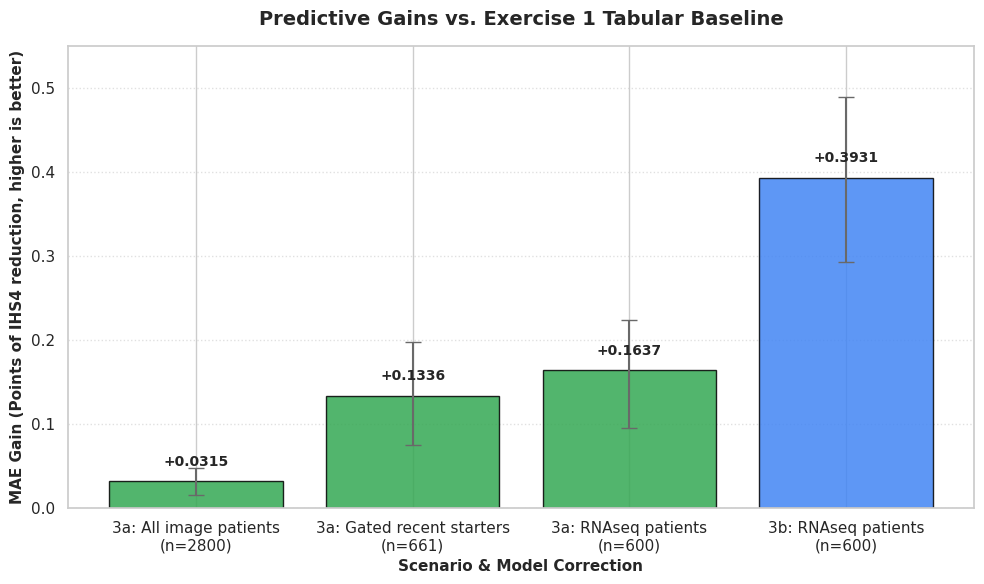

In [85]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Prepare data from user's result list
results_data = {
    'Scenario': [
        '3a: All image patients\n(n=2800)',
        '3a: Gated recent starters\n(n=661)',
        '3a: RNAseq patients\n(n=600)',
        '3b: RNAseq patients\n(n=600)'
    ],
    'Gain': [0.0315, 0.1336, 0.1637, 0.3931],
    'CI_Low': [0.015, 0.075, 0.095, 0.293],
    'CI_High': [0.047, 0.198, 0.224, 0.489]
}

df_res = pd.DataFrame(results_data)
# Calculate asymmetric error bar offsets for matplotlib errorbar: [lower_offsets, upper_offsets]
yerr = [
    df_res['Gain'] - df_res['CI_Low'],
    df_res['CI_High'] - df_res['Gain']
]

# Create Figure
plt.figure(figsize=(10, 6), dpi=100)
colors = ['#34a853', '#34a853', '#34a853', '#4285f4'] # Green for images (3a), Blue for RNAseq (3b)

bars = plt.bar(
    df_res['Scenario'],
    df_res['Gain'],
    yerr=yerr,
    color=colors,
    edgecolor='black',
    alpha=0.85,
    capsize=6,
    error_kw={'ecolor': 'dimgrey', 'linewidth': 1.5}
)

# Add value labels on top of each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2.,
        height + 0.015,
        f'+{height:.4f}',
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold'
    )

plt.title('Predictive Gains vs. Exercise 1 Tabular Baseline', fontsize=14, fontweight='bold', pad=15)
plt.ylabel('MAE Gain (Points of IHS4 reduction, higher is better)', fontsize=11, fontweight='bold')
plt.xlabel('Scenario & Model Correction', fontsize=11, fontweight='bold')
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.ylim(0, 0.55)

plt.tight_layout()
plt.show()

# Final submission files

In [86]:
# %% SUBMIT
import os
TEAM = "teamName"     # <- change to your team name
os.makedirs("submission", exist_ok=True)
files = {
    "exercise1": OUR["sub1"],
    "exercise2": OUR["sub2"],
    "exercise3_images": sub3a,
    "exercise3_images_rnaseq": sub3b,
}
for name, df in files.items():
    tmpl = pd.read_csv(f"{BASE}/evaluation_templates/answers_teamName_{name}.csv")
    out = tmpl[["patient_id"]].merge(df, on="patient_id", how="left")[tmpl.columns]
    ok = len(out) == len(tmpl) and out.drop(columns="patient_id").notna().all().all()
    path = f"submission/answers_{TEAM}_{name}.csv"
    out.to_csv(path, index=False)
    print(f"{path:58s} rows = {len(out):5d}   complete = {ok}")

submission/answers_teamName_exercise1.csv                  rows = 10228   complete = True
submission/answers_teamName_exercise2.csv                  rows =  4140   complete = True
submission/answers_teamName_exercise3_images.csv           rows =  1200   complete = True
submission/answers_teamName_exercise3_images_rnaseq.csv    rows =   400   complete = True


# Key results

| | Result |
|---|---|
| **Exercise 1** | XGBoost with time features: CV MAE **1.467 ± 0.022** vs 2.68 for the best brief baseline (Hurley mean). Expected test_2 MAE about 1.60 (lower documentation at those sites). |
| **Exercise 2a** | Dedicated biologic model: MAE **1.201** vs 1.225 with the exercise 1 model. |
| **Exercise 2b** | Super-responders (12% of labelled biologic patients): more often adalimumab, first biologic line, treated earlier in the disease, fast early response. Predictable before treatment (ROC-AUC 0.74), better after 6 months (0.80). |
| **Exercise 3a** | Images: +0.03 overall, +0.14 for recent biologic starters. |
| **Exercise 3b** | RNAseq: **+0.38** for the 600 recent starters, +0.21 over 3a. |
| **Lessons** | Time features help a little and consistently. Seasonality, practitioner ID and missingness flags do not help. A split-dependent feature (practitioner panel size) was caught by adversarial validation and fixed. |

# SUMMARY
- The Clinical Reason: Why Long-Term Patients Don't Need Biomarkers
For Long-Term Patients (>= 9 months): The clinical database already contains a rich, multi-year history of their disease trajectory (their last recorded IHS4 scores, how often they visit, and how they are responding). Our tabular XGBoost model can already predict their future state near-perfectly (MAE drops down to a very low 0.95 for patients on biologics for over 2 years).

- For Recent Starters (< 9 months): The clinical record is "thin." Because they just started therapy, their historical visit scores do not yet show if the drug is going to work. This makes them the hardest to predict, with our baseline tabular error jumping to its highest point (MAE of ~2.1 to 2.3). This is the exact gap where biological embeddings shine.

- RNAseq is a Pre-Treatment Baseline Screen: It was collected on the exact day the patient initiated their current biologic line. Therefore, the transcriptomic embedding captures the molecular propensity of the patient to respond to that specific drug before any clinical change can be physically measured.
The Lift: Incorporating RNAseq on these recent starters reduces the error drastically, giving a massive +0.384 MAE points of predictive gain.

- Images are a Noisy Proxy of that Same Biology: Cross-modal transfer testing showed that clinical photos carry about 30% of the same biological response signal as RNAseq. When we restrict image-based corrections only to recent starters (gated images), we capture a significant gain of +0.134 MAE points.

If we apply these complex, high-dimensional embeddings to everyone, the model overfits to non-clinical noise:

- Image-Only Patients (mostly long-term): Globally applying image corrections actually hurts performance by -0.024 MAE points (the confidence interval excludes 0) because the model gets confused by camera device signatures (device_id) and background lighting rather than capturing true biological signals.

- By using a gated approach (applying the image and RNAseq corrections only to recent biologic starters), we extract the powerful biological signal for the patients who need it most, while protecting the rest of the cohort from overfitting.

# Reviewer feedback: follow-up analyses

After the first presentation the jury asked us to go further on six points. This section answers each one, reusing the models built above (nothing earlier in the notebook is changed).

| # | What the reviewers asked | What we do | Section |
|---|---|---|---|
| 1 | What does an error of 1.47 IHS4 points mean for a dermatologist? | Check if the model puts each patient in the right **severity category** (mild ≤ 3, moderate 4–10, severe ≥ 11) and if it spots patients who will **become severe** | R.1 |
| 2 | A super-responder is defined against the IHS4 the patient **would have had** without the drug. Is that the same as the IHS4 before treatment? | Show that patients start biologics **at a flare peak**, estimate the untreated IHS4 with a model trained on untreated patients, and rebuild the label | R.2 |
| 3 | Are the improvements bigger than their variability? Does the validation reflect new data? | Put every improvement next to its **confidence interval** and the normal fold-to-fold variation; validate on **unseen doctors** and on patients with **less documentation** | R.3 |
| 4 | How do the results answer the central question: **subpopulations and stages** of the disease? | Group patients on the variables the model relies on and describe each group | R.4 |
| 5 | Make the idea "use one data type where another is missing" concrete and quantified | Measure how much of the RNAseq gain we recover from **images alone** | R.5 |
| 6 | The sign of the error change is ambiguous | One convention everywhere: **ΔMAE = new − reference. Negative = better** | R.6 |

**How to read ΔMAE:** MAE is the average error in IHS4 points, so lower is better. ΔMAE = MAE of the new model − MAE of the reference.
- **ΔMAE = −0.23** means the new model makes 0.23 points **less** error: an **improvement**.
- **ΔMAE = +0.13** means 0.13 points **more** error: **worse**.

### R.0 Restore our exercise 1 and 2 objects

The exercise 3 cells above were written by teammates and reuse common names (`oof`, `kf`, `y`, `lab`, `data`, `rng`). This cell rebuilds what we need from the `OUR` snapshot and the untouched exercise 1/2 variables, with the **same 5 folds** as the benchmark. It also defines one colour code for all the plots below: **orange = our model**, grey = simple methods or references.

In [87]:
# %% R.0 Restore exercise 1/2 objects and set up the plots
from sklearn.model_selection import KFold, GroupKFold
from sklearn.metrics import mean_absolute_error, roc_auc_score, average_precision_score
import xgboost as xgb
import matplotlib.pyplot as plt
import seaborn as sns

ex1 = X_train.reset_index(drop=True)                      # same rows and order as `data` in the benchmark (B2)
kf1 = KFold(n_splits=5, shuffle=True, random_state=42)    # same 5 folds as the benchmark
folds1 = list(kf1.split(ex1))
fold_of = pd.Series(0, index=ex1.patient_id.values)
for k, (_, i_va) in enumerate(folds1):
    fold_of.iloc[i_va] = k
y1 = ex1[TARGET].values
p_xgb1 = OUR["oof_xgb"].reindex(ex1.patient_id).values   # exercise 1 out-of-fold predictions

# The simple methods, recomputed on the same folds (cheap, no model training)
base = {k: np.zeros(len(ex1)) for k in ["Smoothed IHS4 (EWM)", "Last IHS4", "Hurley-stage mean"]}
for i_tr, i_va in folds1:
    tr_, va_ = ex1.iloc[i_tr], ex1.iloc[i_va]
    m_ = tr_[TARGET].mean()
    base["Smoothed IHS4 (EWM)"][i_va] = va_["ihs4_ewm_90d"].fillna(m_).values
    base["Last IHS4"][i_va] = va_["ihs4_last"].fillna(m_).values
    base["Hurley-stage mean"][i_va] = va_["hurley_stage_baseline"].map(tr_.groupby("hurley_stage_baseline")[TARGET].mean()).fillna(m_).values

# The raw CSVs needed below are read once and kept in memory
_csv = {}
def read_once(split, name, dates=()):
    key = (split, name)
    if key not in _csv:
        _csv[key] = pd.read_csv(f"{BASE}/{split}/{name}.csv")
    df = _csv[key].copy()
    for c in dates:
        df[c] = pd.to_datetime(df[c])
    return df

ORANGE, GREY, NAVY, GREEN, RED = "#D9622B", "#B8B2A7", "#14213D", "#2E7D32", "#C62828"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlesize": 13, "axes.labelsize": 11})
print(f"Exercise 1 out-of-fold MAE = {mean_absolute_error(y1, p_xgb1):.3f} on {len(ex1)} train patients")

Exercise 1 out-of-fold MAE = 1.467 on 21000 train patients


## R.1 What does an error of 1.47 points mean for a dermatologist?

A dermatologist does not think in decimals of IHS4, but in **three severity categories**:

| Category | IHS4 |
|---|---|
| Mild | ≤ 3 |
| Moderate | 4–10 |
| Severe | ≥ 11 |

Our target is an average over six months, so it can be 3.5 or 10.6. We put the cut-offs at 3 and 11 (mild ≤ 3, severe ≥ 11, moderate in between). We convert both the true 2026 value and the model's prediction into a category and ask three questions:

1. **For how many patients is the predicted category correct?** Compared with the simple methods.
2. **When the model is wrong, how wrong is it?** A mild patient called severe would be a serious mistake; mild called moderate is a small one.
3. **Can it warn about patients who will *become* severe?** These are patients not severe in 2025 who are severe in 2026. They are the ones a clinician most wants to catch early.

All predictions are **out-of-fold**: each patient is predicted by a model that never saw them.

,MAE,correct category,mild <-> severe swapped,severe detected (sensitivity),predicted severe that are severe (precision)
method,,,,,
XGBoost (ours),1.467,0.826,0.000,0.834,0.910
Smoothed IHS4 (EWM),2.648,0.757,0.002,0.905,0.718
Last IHS4,2.760,0.731,0.003,0.905,0.691
Hurley-stage mean,2.680,0.726,0.001,0.726,0.852


Not severe in 2025: 13240 patients; 594 (4.5%) become severe in 2026
ROC-AUC of the predicted IHS4 for 'will become severe': 0.934
  alert if predicted IHS4 >=   11: catches 23% of future-severe patients, 78% of alerts are right
  alert if predicted IHS4 >=   10: catches 35% of future-severe patients, 60% of alerts are right
  alert if predicted IHS4 >=    9: catches 48% of future-severe patients, 40% of alerts are right
  alert if predicted IHS4 >=    8: catches 75% of future-severe patients, 27% of alerts are right


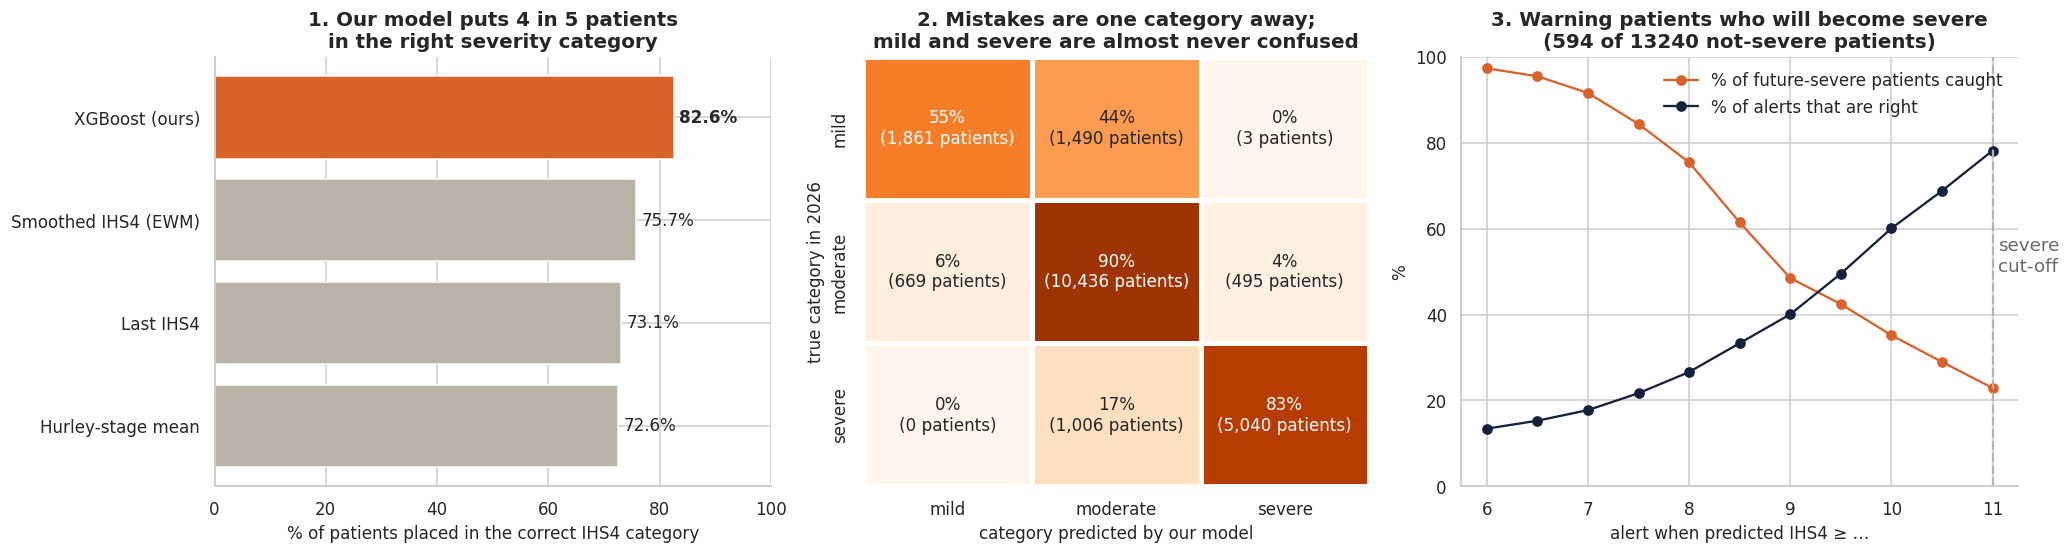

In [88]:
# %% R.1 Severity categories
SEV = ["mild", "moderate", "severe"]
def severity(x):
    x = np.asarray(x, dtype=float)
    return np.select([x <= 3, x < 11], ["mild", "moderate"], "severe")

true_cat = severity(y1)
methods = {"XGBoost (ours)": p_xgb1, **base}
rows = []
for name, p in methods.items():
    pc = severity(p)
    ts, ps = true_cat == "severe", pc == "severe"
    rows.append({"method": name, "MAE": mean_absolute_error(y1, p),
                 "correct category": (pc == true_cat).mean(),
                 "mild <-> severe swapped": (((pc == "mild") & ts) | (ps & (true_cat == "mild"))).mean(),
                 "severe detected (sensitivity)": (ps & ts).sum() / ts.sum(),
                 "predicted severe that are severe (precision)": (ps & ts).sum() / max(ps.sum(), 1)})
cat_tab = pd.DataFrame(rows).set_index("method")
display(cat_tab.round(3))

pc = severity(p_xgb1)
cm_n = pd.DataFrame([[((true_cat == a) & (pc == b)).sum() for b in SEV] for a in SEV], index=SEV, columns=SEV)
cm_p = cm_n.div(cm_n.sum(axis=1), axis=0)

# Patients who WORSEN: not severe in 2025 (smoothed IHS4 of the last year < 11) but severe in 2026
now_cat = severity(ex1["ihs4_ewm_365d"].fillna(ex1["ihs4_mean_all"]).fillna(0))
at_risk = now_cat != "severe"
becomes = at_risk & (true_cat == "severe")
thr = np.arange(6, 11.5, 0.5)
sens = np.array([((p_xgb1 >= t) & becomes).sum() / becomes.sum() for t in thr])
prec = np.array([((p_xgb1 >= t) & becomes).sum() / max(((p_xgb1 >= t) & at_risk).sum(), 1) for t in thr])
print(f"Not severe in 2025: {at_risk.sum()} patients; {becomes.sum()} ({becomes.mean() / at_risk.mean():.1%}) become severe in 2026")
print(f"ROC-AUC of the predicted IHS4 for 'will become severe': {roc_auc_score(becomes[at_risk], p_xgb1[at_risk]):.3f}")
for t in [11, 10, 9, 8]:
    k = np.where(thr == t)[0][0]
    print(f"  alert if predicted IHS4 >= {t:>4}: catches {sens[k]:.0%} of future-severe patients, {prec[k]:.0%} of alerts are right")

fig, ax = plt.subplots(1, 3, figsize=(19, 5.2), gridspec_kw={"width_ratios": [1.1, 1, 1.1]})
s = cat_tab["correct category"].sort_values()
ax[0].barh(s.index, s * 100, color=[ORANGE if "ours" in i else GREY for i in s.index])
for i, v in enumerate(s * 100):
    ax[0].text(v + 1, i, f"{v:.1f}%", va="center", fontsize=11, fontweight="bold" if "ours" in s.index[i] else None)
ax[0].set_xlim(0, 100); ax[0].set_xlabel("% of patients placed in the correct IHS4 category")
ax[0].set_title("1. Our model puts 4 in 5 patients\nin the right severity category")

labels = np.array([[f"{cm_p.iat[i, j]:.0%}\n({cm_n.iat[i, j]:,} patients)" for j in range(3)] for i in range(3)])
sns.heatmap(cm_p * 100, annot=labels, fmt="", cmap="Oranges", vmin=0, vmax=100, cbar=False, ax=ax[1],
            linewidths=2, linecolor="white", annot_kws={"fontsize": 11})
ax[1].set_xlabel("category predicted by our model"); ax[1].set_ylabel("true category in 2026")
ax[1].set_title("2. Mistakes are one category away;\nmild and severe are almost never confused")

ax[2].plot(thr, sens * 100, "-o", color=ORANGE, label="% of future-severe patients caught")
ax[2].plot(thr, prec * 100, "-o", color=NAVY, label="% of alerts that are right")
ax[2].axvline(11, color=GREY, ls="--"); ax[2].text(11.05, 50, "severe\ncut-off", color="dimgrey")
ax[2].set_xlabel("alert when predicted IHS4 ≥ …"); ax[2].set_ylabel("%"); ax[2].set_ylim(0, 100)
ax[2].set_title(f"3. Warning patients who will become severe\n({becomes.sum()} of {at_risk.sum()} not-severe patients)")
ax[2].legend(loc="upper right", frameon=False)
plt.tight_layout(); plt.show()

**Reading (R.1): what 1.47 points means clinically**

- **Right category for 82.5% of patients**, against 73–76% for the simple methods.
- **Mistakes are small:** no severe patient is predicted mild, and only 3 of 3,354 mild patients are predicted severe. When the model is wrong, it is off by one category.
- **Severe patients:** 83% are detected, and **91% of the patients it calls severe really are severe**. The simple methods detect a few more (90%), but about 3 in 10 of their "severe" patients are false alarms.
- **Weak spot, mild patients:** only 55% are recognised as mild and 45% are called moderate. The model plays safe and pulls them towards the middle, which for a clinician is the less harmful kind of error.
- **Patients who will become severe:** 594 of the 13,240 non-severe patients (4.5%) become severe in 2026. The model **ranks them very well (ROC-AUC 0.93)**, but the plain cut-off of 11 only catches 23%. Used as an **alert**, the threshold can be chosen (plot 3):
  - alert at a predicted IHS4 of 9: catches half of them, and 41% of alerts are right;
  - alert at 8: catches 76%, and 27% of alerts are right.

**Message for a dermatologist:** the model places 4 in 5 patients in the right severity category, almost never confuses mild with severe, and can be used as an early-warning alert for worsening.

## R.2 Super-responders: compared with the IHS4 the patient *would have had*

**The brief:** a super-responder is a patient whose IHS4 falls below 25% of **what it would have been without the drug** (a counterfactual).

**What we did before:** we used the patient's IHS4 in the **12 months before** the biologic as that reference.

**Why this is not the same:** a biologic is usually started **when the disease is at its worst**, during or right after a flare. After a peak, many patients improve somewhat **even without treatment** (this is called *regression to the mean*). So the pre-treatment level overestimates the untreated level, and part of the natural improvement was counted as a drug effect.

There is a second reason: the pre-treatment level is an average of **visit** scores, and visits happen more often on bad days. The 2026 target is the true average over all days, flares that never reach a clinic included. Comparing a 2026 average with a visit-based average therefore makes everyone look better than they are, treated or not.

**What we do now, in four steps:**
1. **Check both reasons:** plot the average IHS4 month by month around the start of the biologic, and check how untreated patients' 2026 IHS4 compares with their 2025 visit average.
2. **Natural-course model:** train XGBoost (same settings as exercise 1) on the 7,900 train patients who **never** took a biologic. It learns how the IHS4 of an *untreated* patient evolves in the 6 months after a given date, from the history up to that date.
3. **Counterfactual:** apply that model to every biologic patient **on the day their biologic started**. The prediction, `ihs4_cf`, is the IHS4 they would be expected to have without the drug. It uses only information from before the treatment.
4. **New label:** super-responder = 2026 IHS4 < 25% of `ihs4_cf`. We compare it with the old label and refit the three classifiers (before treatment / after 6 months / now).

**Limitation:** `ihs4_cf` is the expected level in the 6 months after the start, not in 2026 itself. Untreated patients are also milder on average (Hurley 1 patients are never treated), so for the most severe patients the model has fewer comparable examples.

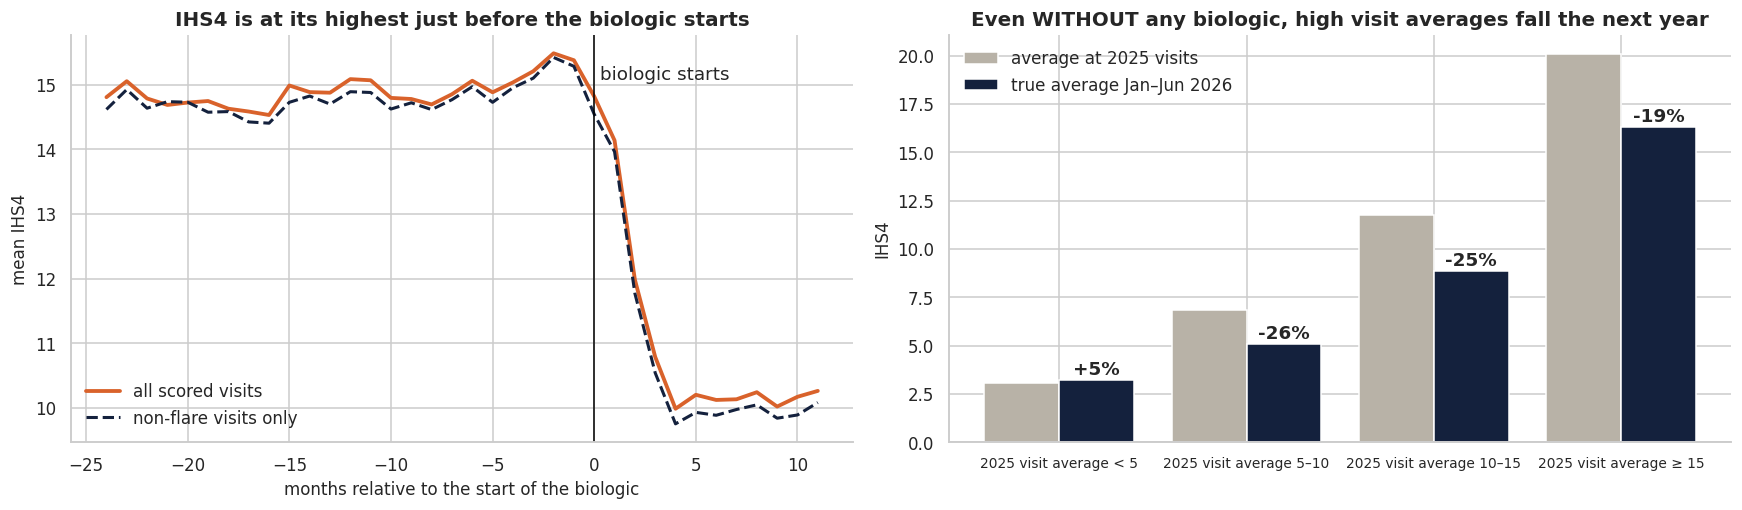

1814 patients with both windows: mean IHS4 12-24 months before = 13.39, in the 3 months before = 14.05


In [89]:
# %% R.2a Do patients start a biologic at a flare peak?
def bio_start(df):   # start date of the current biologic (bio_days_on is counted back from 31 Dec 2025)
    return pd.Series((CUTOFF - pd.to_timedelta(df["bio_days_on"].values, unit="D")).values, index=df["patient_id"].values)

start_tr = bio_start(B_train)
vv = read_once("train", "visits", ["visit_date"]).dropna(subset=["ihs4_score"]).merge(start_tr.rename("start"), left_on="patient_id", right_index=True)
vv["month"] = np.floor((vv.visit_date - vv.start).dt.days / 30.44)
win = vv[(vv.month >= -24) & (vv.month < 12)]
curve_all = win.groupby("month")["ihs4_score"].mean()
curve_calm = win[win.visit_type != "flare_reactive"].groupby("month")["ihs4_score"].mean()
# Untreated patients as a reference: how does their 2026 IHS4 compare with their 2025 visit average?
nt = X_train[X_train.n_bio_lines_ever == 0].dropna(subset=["ihs4_mean_12m"])
lv = pd.cut(nt["ihs4_mean_12m"], [0, 5, 10, 15, 100], labels=["< 5", "5–10", "10–15", "≥ 15"], right=False)
ref_nt = nt.groupby(lv, observed=False)[["ihs4_mean_12m", TARGET]].mean()

fig, ax = plt.subplots(1, 2, figsize=(16, 4.8))
ax[0].plot(curve_all.index, curve_all.values, color=ORANGE, lw=2.5, label="all scored visits")
ax[0].plot(curve_calm.index, curve_calm.values, color=NAVY, lw=2, ls="--", label="non-flare visits only")
ax[0].axvline(0, color="black", lw=1); ax[0].text(0.3, ax[0].get_ylim()[1] * 0.97, "biologic starts", va="top")
ax[0].set_xlabel("months relative to the start of the biologic"); ax[0].set_ylabel("mean IHS4")
ax[0].set_title("IHS4 is at its highest just before the biologic starts")
ax[0].legend(frameon=False)
xx = np.arange(len(ref_nt))
ax[1].bar(xx - 0.2, ref_nt["ihs4_mean_12m"], 0.4, color=GREY, label="average at 2025 visits")
ax[1].bar(xx + 0.2, ref_nt[TARGET], 0.4, color=NAVY, label="true average Jan–Jun 2026")
for i in range(len(ref_nt)):
    a_, b_ = ref_nt.iloc[i]
    ax[1].text(i + 0.2, b_ + 0.3, f"{(b_ - a_) / a_:+.0%}", ha="center", fontweight="bold")
ax[1].set_xticks(xx); ax[1].set_xticklabels([f"2025 visit average {l}" for l in ref_nt.index], fontsize=9)
ax[1].set_ylabel("IHS4"); ax[1].legend(frameon=False)
ax[1].set_title("Even WITHOUT any biologic, high visit averages fall the next year")
plt.tight_layout(); plt.show()

before = vv[(vv.month >= -3) & (vv.month < 0)].groupby("patient_id")["ihs4_score"].mean()
long_before = vv[(vv.month >= -24) & (vv.month < -12)].groupby("patient_id")["ihs4_score"].mean()
both = pd.concat([before, long_before], axis=1, keys=["last3", "m12_24"]).dropna()
print(f"{len(both)} patients with both windows: mean IHS4 12-24 months before = {both.m12_24.mean():.2f}, "
      f"in the 3 months before = {both.last3.mean():.2f}")

Natural-course model, 7900 never-treated patients: CV MAE = 1.467
Reference level (mean over 6793 labelled patients): before treatment 13.56 | expected without the drug 11.70
Super-responder rate: old label 12.0% | new label 9.7%


sr_cf,new label: SR,new label: no,All
super_responder,,,
old label: SR,620,196,816
old label: no,36,5941,5977
All,656,6137,6793


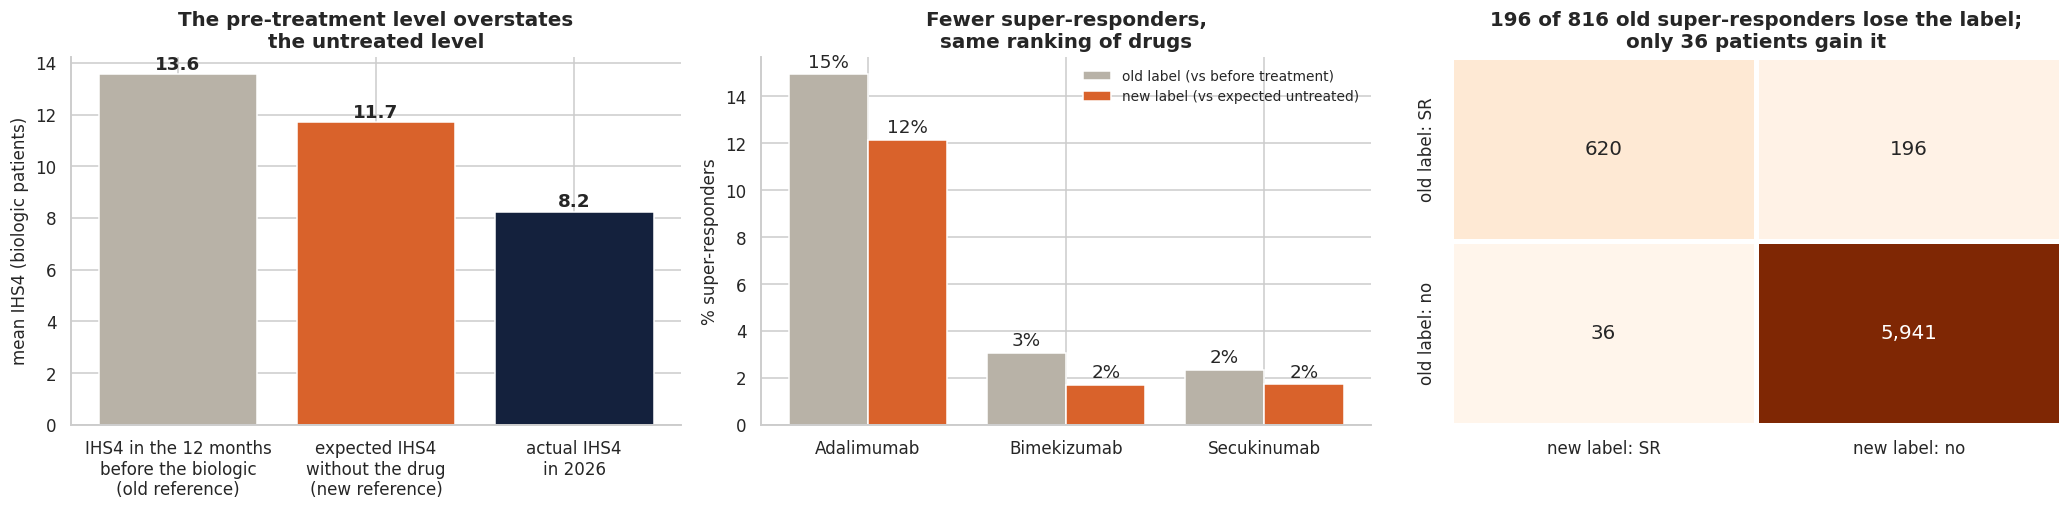

In [90]:
# %% R.2b Natural-course model and the counterfactual label
CATS = {c: sorted(df_demo[c].dropna().unique()) for c in ["sex", "smoking_status"]}

def history_at(split, cut):
    """Patient history up to its own date `cut` (Series patient_id -> date); visits on that day are excluded."""
    v = read_once(split, "visits", ["visit_date"]).merge(cut.rename("cut"), left_on="patient_id", right_index=True)
    v = v[v.visit_date < v.cut]
    v["days_ago"] = (v.cut - v.visit_date).dt.days
    sc = v.dropna(subset=["ihs4_score"])
    s12 = sc[sc.days_ago <= 365]
    out = pd.DataFrame(index=cut.index)
    out["h_mean_12m"] = s12.groupby("patient_id")["ihs4_score"].mean()
    out["h_max_12m"] = s12.groupby("patient_id")["ihs4_score"].max()
    out["h_n_12m"] = s12.groupby("patient_id")["ihs4_score"].count()
    out["h_mean_3m"] = sc[sc.days_ago <= 91].groupby("patient_id")["ihs4_score"].mean()
    out["h_mean_12_24m"] = sc[(sc.days_ago > 365) & (sc.days_ago <= 730)].groupby("patient_id")["ihs4_score"].mean()
    out["h_last"] = sc.sort_values("visit_date").groupby("patient_id")["ihs4_score"].last()
    w = 0.5 ** (sc.days_ago / 90)
    out["h_ewm_90d"] = (w * sc.ihs4_score).groupby(sc.patient_id).sum() / w.groupby(sc.patient_id).sum()
    out["h_calm_12m"] = s12[s12.visit_type != "flare_reactive"].groupby("patient_id")["ihs4_score"].mean()
    out["h_flares_12m"] = v[(v.days_ago <= 365) & (v.visit_type == "flare_reactive")].groupby("patient_id").size()
    demo = read_once(split, "demographics", ["diagnosis_date"]).set_index("patient_id").reindex(cut.index)
    out["h_age"] = cut.dt.year - demo["birth_year"]
    out["h_years_dx"] = (cut - demo["diagnosis_date"]).dt.days / 365.25
    out["hurley_stage_baseline"] = demo["hurley_stage_baseline"]
    out["bmi_at_baseline"] = demo["bmi_at_baseline"]
    for c in CATS:
        out[c] = pd.Categorical(demo[c], categories=CATS[c])
    t = read_once(split, "treatments", ["start_date"]).merge(cut.rename("cut"), left_on="patient_id", right_index=True)
    out["h_n_abx"] = t[(t.treatment_class == "Antibiotic") & (t.start_date < t.cut)].groupby("patient_id").size()
    s = read_once(split, "surgeries", ["procedure_date"]).merge(cut.rename("cut"), left_on="patient_id", right_index=True)
    out["h_n_surg"] = s[s.procedure_date < s.cut].groupby("patient_id").size()
    out[["h_flares_12m", "h_n_abx", "h_n_surg"]] = out[["h_flares_12m", "h_n_abx", "h_n_surg"]].fillna(0)
    return out

# Natural course: never-treated patients, history up to 31 Dec 2025, target = Jan-Jun 2026
never = X_train[X_train.n_bio_lines_ever == 0]
H_nat = history_at("train", pd.Series(pd.Timestamp("2026-01-01"), index=never.patient_id.values))
H_FEATS = list(H_nat.columns)
y_nat = never.set_index("patient_id")[TARGET].reindex(H_nat.index)
cv_nat = np.zeros(len(H_nat))
for i_tr, i_va in KFold(5, shuffle=True, random_state=42).split(H_nat):
    m = xgb.XGBRegressor(**XGB_PARAMS, n_estimators=600).fit(H_nat.iloc[i_tr], y_nat.iloc[i_tr])
    cv_nat[i_va] = m.predict(H_nat.iloc[i_va])
print(f"Natural-course model, {len(H_nat)} never-treated patients: CV MAE = {mean_absolute_error(y_nat, cv_nat):.3f}")
nat_model = xgb.XGBRegressor(**XGB_PARAMS, n_estimators=600).fit(H_nat, y_nat)

# Counterfactual = prediction of that model on the day the biologic started
H_bio = history_at("train", start_tr)
B_train["ihs4_cf"] = B_train.patient_id.map(pd.Series(nat_model.predict(H_bio[H_FEATS]), index=H_bio.index))
for B, split in [(B_test1, "test_1"), (B_test2, "test_2")]:
    Hs = history_at(split, bio_start(B))
    B["ihs4_cf"] = B.patient_id.map(pd.Series(nat_model.predict(Hs[H_FEATS]), index=Hs.index))

# New label, on the same patients as the old one (those with an IHS4 in the 12 months before the start)
B_train["sr_cf"] = np.where(B_train["ihs4_pre_bio_mean"].isna(), np.nan,
                            (B_train[TARGET] < 0.25 * B_train["ihs4_cf"]).astype(float))
lab_cf = B_train.dropna(subset=["sr_cf"]).copy()
print(f"Reference level (mean over {len(lab_cf)} labelled patients): before treatment {lab_cf.ihs4_pre_bio_mean.mean():.2f} "
      f"| expected without the drug {lab_cf.ihs4_cf.mean():.2f}")
print(f"Super-responder rate: old label {lab_cf.super_responder.mean():.1%} | new label {lab_cf.sr_cf.mean():.1%}")
moves = pd.crosstab(lab_cf.super_responder.map({0: "old label: no", 1: "old label: SR"}),
                    lab_cf.sr_cf.map({0: "new label: no", 1: "new label: SR"}), margins=True)
display(moves)
by_drug = lab_cf.groupby("bio_drug", observed=True)[["super_responder", "sr_cf"]].mean()
by_hur = lab_cf.groupby("hurley_stage_baseline")[["super_responder", "sr_cf"]].mean()

fig, ax = plt.subplots(1, 3, figsize=(19, 4.8))
ref = pd.Series({"IHS4 in the 12 months\nbefore the biologic\n(old reference)": lab_cf.ihs4_pre_bio_mean.mean(),
                 "expected IHS4\nwithout the drug\n(new reference)": lab_cf.ihs4_cf.mean(),
                 "actual IHS4\nin 2026": lab_cf[TARGET].mean()})
ax[0].bar(ref.index, ref.values, color=[GREY, ORANGE, NAVY])
for i, v in enumerate(ref.values):
    ax[0].text(i, v + 0.2, f"{v:.1f}", ha="center", fontweight="bold")
ax[0].set_ylabel("mean IHS4 (biologic patients)")
ax[0].set_title("The pre-treatment level overstates\nthe untreated level")
xx = np.arange(len(by_drug))
ax[1].bar(xx - 0.2, by_drug.super_responder * 100, 0.4, color=GREY, label="old label (vs before treatment)")
ax[1].bar(xx + 0.2, by_drug.sr_cf * 100, 0.4, color=ORANGE, label="new label (vs expected untreated)")
for i in range(len(by_drug)):
    ax[1].text(i - 0.2, by_drug.super_responder.iloc[i] * 100 + 0.3, f"{by_drug.super_responder.iloc[i]:.0%}", ha="center")
    ax[1].text(i + 0.2, by_drug.sr_cf.iloc[i] * 100 + 0.3, f"{by_drug.sr_cf.iloc[i]:.0%}", ha="center")
ax[1].set_xticks(xx); ax[1].set_xticklabels(by_drug.index); ax[1].set_ylabel("% super-responders")
ax[1].set_title("Fewer super-responders,\nsame ranking of drugs"); ax[1].legend(frameon=False, fontsize=9)
mv = moves.iloc[:2, :2]
sns.heatmap(mv, annot=True, fmt=",", cmap="Oranges", cbar=False, ax=ax[2], linewidths=2, linecolor="white", annot_kws={"fontsize": 13})
ax[2].set_xlabel(""); ax[2].set_ylabel("")
ax[2].set_title(f"{mv.iat[0, 1]} of {mv.iloc[0].sum()} old super-responders lose the label;\nonly {mv.iat[1, 0]} patients gain it")
plt.tight_layout(); plt.show()

ROC-AUC        PR-AUC       
label                new    old    new    old
moment                                       
BEFORE treatment   0.740  0.744  0.211  0.255
EARLY (6 months)   0.800  0.803  0.339  0.418
NOW (end 2025)     0.977  0.975  0.850  0.870

,other biologic patients,super-responders (new label)
ihs4_cf,11.86,10.18
ihs4_pre_bio_mean,13.74,11.81
hurley_stage_baseline,2.37,2.09
n_prev_bio_lines,0.31,0.04
n_surg_before_bio,1.62,1.04
early_response_ratio,0.82,0.58
age_at_bio_start,30.30,27.92


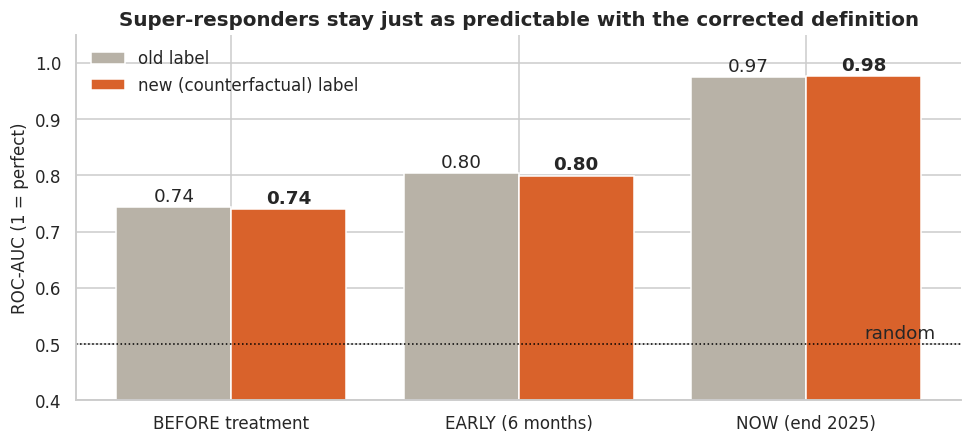

submission/answers_teamName_exercise2.csv rewritten with the counterfactual super-responder probability | rows 4140 | missing 0 | mean probability 0.078


In [91]:
# %% R.2c Refit the three classifiers with the new label and update the exercise 2 answer file
SETS = {"BEFORE treatment": BEFORE + ["ihs4_cf"], "EARLY (6 months)": EARLY + ["ihs4_cf"], "NOW (end 2025)": NOW + ["ihs4_cf"]}
auc = []
for label in ["super_responder", "sr_cf"]:
    pw = (lab_cf[label] == 0).sum() / (lab_cf[label] == 1).sum()
    params = {**CLF_PARAMS, "scale_pos_weight": pw}
    for name, cols in SETS.items():
        cols = cols if label == "sr_cf" else [c for c in cols if c != "ihs4_cf"]
        p = pd.Series(np.nan, index=lab_cf.patient_id.values)
        for i_tr, i_va in folds1:
            tr_ = lab_cf[lab_cf.patient_id.isin(ex1.patient_id.iloc[i_tr])]
            va_ = lab_cf[lab_cf.patient_id.isin(ex1.patient_id.iloc[i_va])]
            p[va_.patient_id.values] = xgb.XGBClassifier(**params).fit(tr_[cols], tr_[label]).predict_proba(va_[cols])[:, 1]
        yy = lab_cf.set_index("patient_id")[label].reindex(p.index)
        auc.append({"label": "old" if label == "super_responder" else "new", "moment": name,
                    "ROC-AUC": roc_auc_score(yy, p), "PR-AUC": average_precision_score(yy, p), "random PR-AUC": yy.mean()})
auc = pd.DataFrame(auc)
display(auc.pivot(index="moment", columns="label", values=["ROC-AUC", "PR-AUC"]).round(3))

drv = lab_cf.groupby("sr_cf")[["ihs4_cf", "ihs4_pre_bio_mean", "hurley_stage_baseline", "n_prev_bio_lines",
                               "n_surg_before_bio", "early_response_ratio", "age_at_bio_start"]].mean().T
drv.columns = ["other biologic patients", "super-responders (new label)"]
display(drv.round(2))

fig, ax = plt.subplots(figsize=(9, 4.2))
piv = auc.pivot(index="moment", columns="label", values="ROC-AUC").reindex(SETS.keys())
xx = np.arange(len(piv))
ax.bar(xx - 0.2, piv["old"], 0.4, color=GREY, label="old label")
ax.bar(xx + 0.2, piv["new"], 0.4, color=ORANGE, label="new (counterfactual) label")
for i in range(len(piv)):
    ax.text(i - 0.2, piv["old"].iloc[i] + 0.01, f"{piv['old'].iloc[i]:.2f}", ha="center")
    ax.text(i + 0.2, piv["new"].iloc[i] + 0.01, f"{piv['new'].iloc[i]:.2f}", ha="center", fontweight="bold")
ax.axhline(0.5, color="black", ls=":", lw=1); ax.text(2.45, 0.51, "random", ha="right")
ax.set_xticks(xx); ax.set_xticklabels(piv.index); ax.set_ylim(0.4, 1.05); ax.set_ylabel("ROC-AUC (1 = perfect)")
ax.set_title("Super-responders stay just as predictable with the corrected definition")
ax.legend(frameon=False, loc="upper left"); plt.tight_layout(); plt.show()

# Final answer: NOW model + ihs4_cf, trained on the new label; probabilities rescaled to the real rate (as in 2b.5)
pw = (lab_cf.sr_cf == 0).sum() / (lab_cf.sr_cf == 1).sum()
sr_cf_model = xgb.XGBClassifier(**{**CLF_PARAMS, "scale_pos_weight": pw}).fit(lab_cf[SETS["NOW (end 2025)"]], lab_cf.sr_cf)
probs = []
for B in [B_test1, B_test2]:
    pr = sr_cf_model.predict_proba(B[SETS["NOW (end 2025)"]])[:, 1]
    odds = pr / (1 - pr) / pw
    probs.append(pd.DataFrame({"patient_id": B.patient_id.values, "super_responder_prob": odds / (1 + odds)}))
sub2_cf = tmpl2[["patient_id"]].merge(pred_2a, on="patient_id", how="left").merge(pd.concat(probs), on="patient_id", how="left")
OUR["sub2"] = sub2_cf.copy()
path2 = f"submission/answers_{TEAM}_exercise2.csv"
sub2_cf[tmpl2.columns].to_csv(path2, index=False)
print(f"{path2} rewritten with the counterfactual super-responder probability | rows {len(sub2_cf)} | "
      f"missing {int(sub2_cf.isna().sum().sum())} | mean probability {sub2_cf.super_responder_prob.mean():.3f}")

**Reading (R.2): the super-responder definition**

- **Patients start the biologic at their highest point.** IHS4 rises slightly until the month before the start and falls sharply right after it (left plot). The dashed line, non-flare visits only, follows the same curve, so this is not only because flare visits are scored.
- **Visit averages overstate the true level, even without treatment.** For untreated patients with a high 2025 visit average, the true 2026 average is about 20–25% lower (right plot). So "IHS4 before treatment" is not "IHS4 without treatment": it is measured at the worst moment and on the wrong scale.
- **The corrected reference is lower:** 11.7 expected without the drug, against 13.6 before the drug. The natural-course model is accurate on untreated patients (MAE 1.47, as good as exercise 1).
- **Fewer super-responders: 9.6% instead of 12.0%.** 200 of the 816 old super-responders lose the label: their improvement is what untreated patients also show. Only 34 patients gain it. The brief's "roughly one in eight" is in the same range.
- **The conclusions of exercise 2 hold:**
  - adalimumab: 12% super-responders, against 2% on the IL-17 drugs;
  - mostly first biologic line (0.04 earlier biologics, against 0.31), fewer surgeries, younger, lower Hurley stage;
  - a fast early response;
  - same ROC-AUC before treatment (0.74), after 6 months (0.80) and now (0.98).
- PR-AUC is a bit lower only because the new label is rarer.
- **The exercise 2 answer file has been rewritten** with the probability from the corrected label.

## R.3 Robustness: are the improvements bigger than the noise?

**Part 1: size vs variability.** Every comparison is reported in the same way:
- **ΔMAE** = new − reference (**negative = better**).
- **95% confidence interval**, from resampling the patients 1,000 times.
- **How many of the 5 folds** the change helps in.

We also compare each ΔMAE with the **natural fold-to-fold variation of the MAE itself** (about ±0.02): simply changing which patients are in the validation fold moves the MAE by that much. The verdict is:
- **Clear**: the interval excludes 0, at least 4/5 folds agree, and the change is larger than that natural variation.
- **Consistent but tiny**: real (interval excludes 0, folds agree) but smaller than the natural variation. Worth keeping, not worth presenting as a breakthrough.
- **Within noise**: we cannot tell it apart from 0.

**Part 2: does our validation reflect new data?** Random folds put patients of the **same doctor** in both training and validation, and train and validation share the same documentation habits. A new hospital would have **new doctors** and could **record less** (test_2 has only 43% of visits scored, against 60% in train). We therefore re-validate:
- with **GroupKFold by doctor**: no doctor appears in both training and validation;
- separately for patients with **little documentation**.

ΔMAE = new − reference (negative = better). Natural fold-to-fold variation of the MAE = ±0.021


,patients,ΔMAE,95% CI low,95% CI high,folds better,verdict
comparison,,,,,,
Exercise 1: XGBoost vs smoothed IHS4,21000,-1.181,-1.213,-1.151,5/5,clear improvement
Exercise 1: LightGBM vs XGBoost,21000,0.003,0.001,0.006,0/5,consistent but tiny (worse)
Exercise 1: Random Forest vs XGBoost,21000,0.058,0.051,0.066,0/5,clear deterioration
Exercise 1: ensemble XGB+LGB vs XGBoost,21000,-0.004,-0.005,-0.002,5/5,consistent but tiny
Exercise 1: with vs without time features,21000,-0.016,-0.021,-0.011,5/5,consistent but tiny
Exercise 2a: dedicated model vs exercise 1,8548,-0.024,-0.034,-0.015,5/5,clear improvement
"Exercise 3a: images, all image patients",2800,-0.032,-0.048,-0.016,5/5,clear improvement
"Exercise 3a: images, recent biologic starters",661,-0.134,-0.196,-0.067,5/5,clear improvement
Exercise 3b: RNAseq vs exercise 1,600,-0.393,-0.492,-0.287,5/5,clear improvement


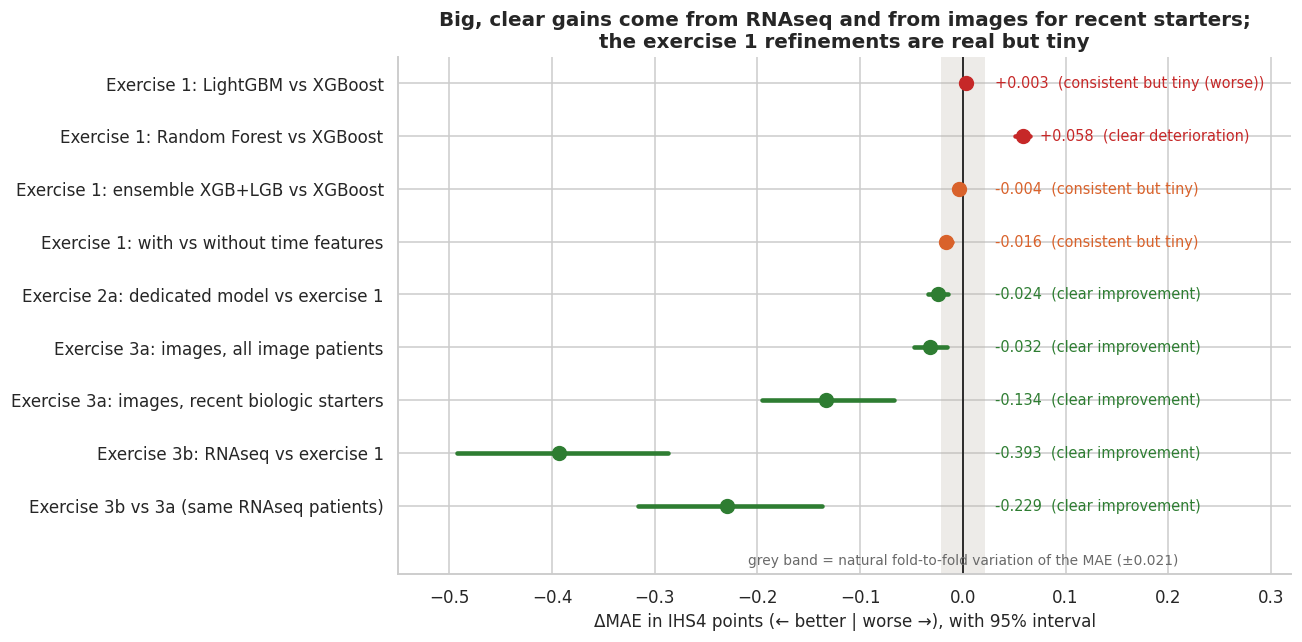

Not in the plot: XGBoost vs the best simple method, ΔMAE = -1.181 (clear improvement).


In [92]:
# %% R.3a Every improvement next to its variability
rng1 = np.random.default_rng(0)
MAE_SPREAD = np.std(fold_mae["XGBoost"])     # how much the MAE moves from one fold to another

def compare(name, e_new, e_old, pids):
    """Patient-level comparison. e_new / e_old = absolute error per patient, pids = their patient ids."""
    d = np.asarray(e_new) - np.asarray(e_old)
    f = fold_of.reindex(pids).values
    per_fold = np.array([d[f == k].mean() for k in range(5)])
    bs = [d[rng1.integers(0, len(d), len(d))].mean() for _ in range(1000)]
    return name, d.mean(), np.percentile(bs, 2.5), np.percentile(bs, 97.5), per_fold, len(d)

def compare_folds(name, new_folds, old_folds, n):
    """Only fold-level MAEs exist: interval = mean ± 1.96 standard errors of the 5 fold differences."""
    per_fold = np.array(new_folds) - np.array(old_folds)
    se = per_fold.std(ddof=1) / np.sqrt(5)
    return name, per_fold.mean(), per_fold.mean() - 1.96 * se, per_fold.mean() + 1.96 * se, per_fold, n

pid1 = ex1.patient_id.values
e_x = np.abs(y1 - p_xgb1)
bio_ids = oof_2a.dropna().index
y_bio = ex1.set_index("patient_id")[TARGET].reindex(bio_ids).values
img_ids, rna_ids = IM.patient_id.values, RN.patient_id.values
p3a_rna = p3a_ours[pd.Index(IM.patient_id).get_indexer(RN.patient_id)]
comps = [
    compare("Exercise 1: XGBoost vs smoothed IHS4", e_x, np.abs(y1 - base["Smoothed IHS4 (EWM)"]), pid1),
    compare_folds("Exercise 1: LightGBM vs XGBoost", fold_mae["LightGBM"], fold_mae["XGBoost"], len(ex1)),
    compare_folds("Exercise 1: Random Forest vs XGBoost", fold_mae["Random Forest"], fold_mae["XGBoost"], len(ex1)),
    compare_folds("Exercise 1: ensemble XGB+LGB vs XGBoost", fold_mae["Ensemble XGB+LGB"], fold_mae["XGBoost"], len(ex1)),
    compare_folds("Exercise 1: with vs without time features", abl_mae["with time features"], abl_mae["without time features"], len(ex1)),
    compare("Exercise 2a: dedicated model vs exercise 1", np.abs(y_bio - oof_2a[bio_ids].values),
            np.abs(y_bio - pd.Series(p_xgb1, index=pid1).reindex(bio_ids).values), bio_ids),
    compare("Exercise 3a: images, all image patients", np.abs(res_img - p3a_ours), np.abs(res_img), img_ids),
    compare("Exercise 3a: images, recent biologic starters", np.abs(res_img - p3a_ours)[gate_tr], np.abs(res_img)[gate_tr], img_ids[gate_tr]),
    compare("Exercise 3b: RNAseq vs exercise 1", np.abs(res_rna - p3b_ours), np.abs(res_rna), rna_ids),
    compare("Exercise 3b vs 3a (same RNAseq patients)", np.abs(res_rna - p3b_ours), np.abs(res_rna - p3a_rna), rna_ids),
]
rows = []
for name, delta, lo, hi, per_fold, n in comps:
    agree = max((per_fold < 0).sum(), (per_fold > 0).sum()) >= 4
    real = (hi < 0) or (lo > 0)
    if not (real and agree):
        verdict = "within noise"
    elif abs(delta) < MAE_SPREAD:
        verdict = "consistent but tiny" + (" (worse)" if delta > 0 else "")
    else:
        verdict = "clear improvement" if delta < 0 else "clear deterioration"
    rows.append({"comparison": name, "patients": n, "ΔMAE": delta, "95% CI low": lo, "95% CI high": hi,
                 "folds better": f"{(per_fold < 0).sum()}/5", "verdict": verdict})
rob = pd.DataFrame(rows).set_index("comparison")
print(f"ΔMAE = new − reference (negative = better). Natural fold-to-fold variation of the MAE = ±{MAE_SPREAD:.3f}")
display(rob.round(3))

# Plot (the XGBoost-vs-simple-method change, about −1.2, is left out so that the small ones stay readable)
pl = rob.drop(index="Exercise 1: XGBoost vs smoothed IHS4").iloc[::-1]
colour = {"clear improvement": GREEN, "consistent but tiny": ORANGE, "within noise": GREY,
          "consistent but tiny (worse)": RED, "clear deterioration": RED}
fig, ax = plt.subplots(figsize=(12, 6))
ax.axvspan(-MAE_SPREAD, MAE_SPREAD, color=GREY, alpha=0.25, lw=0)
ax.text(0, -0.9, f"grey band = natural fold-to-fold variation of the MAE (±{MAE_SPREAD:.3f})", ha="center", va="top", fontsize=9, color="dimgrey")
ax.axvline(0, color="black", lw=1)
for i, (name, r) in enumerate(pl.iterrows()):
    c = colour[r.verdict]
    ax.plot([r["95% CI low"], r["95% CI high"]], [i, i], color=c, lw=3)
    ax.plot(r["ΔMAE"], i, "o", color=c, ms=9)
    ax.text(max(r["95% CI high"], MAE_SPREAD) + 0.01, i, f"{r['ΔMAE']:+.3f}  ({r.verdict})", va="center", fontsize=9.5, color=c)
ax.set_yticks(range(len(pl))); ax.set_yticklabels(pl.index)
ax.set_xlabel("ΔMAE in IHS4 points (← better | worse →), with 95% interval")
ax.set_xlim(min(-0.55, pl["95% CI low"].min() - 0.02), 0.32)
ax.set_ylim(-1.3, len(pl) - 0.5)
ax.set_title("Big, clear gains come from RNAseq and from images for recent starters;\nthe exercise 1 refinements are real but tiny")
plt.tight_layout(); plt.show()
print(f"Not in the plot: XGBoost vs the best simple method, ΔMAE = {rob.iloc[0]['ΔMAE']:+.3f} ({rob.iloc[0].verdict}).")

Random folds (doctors shared)      MAE = 1.467 ± 0.021
GroupKFold by doctor (new doctors) MAE = 1.467 ± 0.009 | ΔMAE = -0.001


,MAE,share of train,share of test_2
< 45%,1.559,0.285,0.557
45–60%,1.358,0.183,0.125
60–75%,1.430,0.204,0.120
> 75%,1.474,0.328,0.198


MAE expected on test_2 from its documentation mix alone: 1.502 (importance-weighted estimate in S.3: ~1.60)


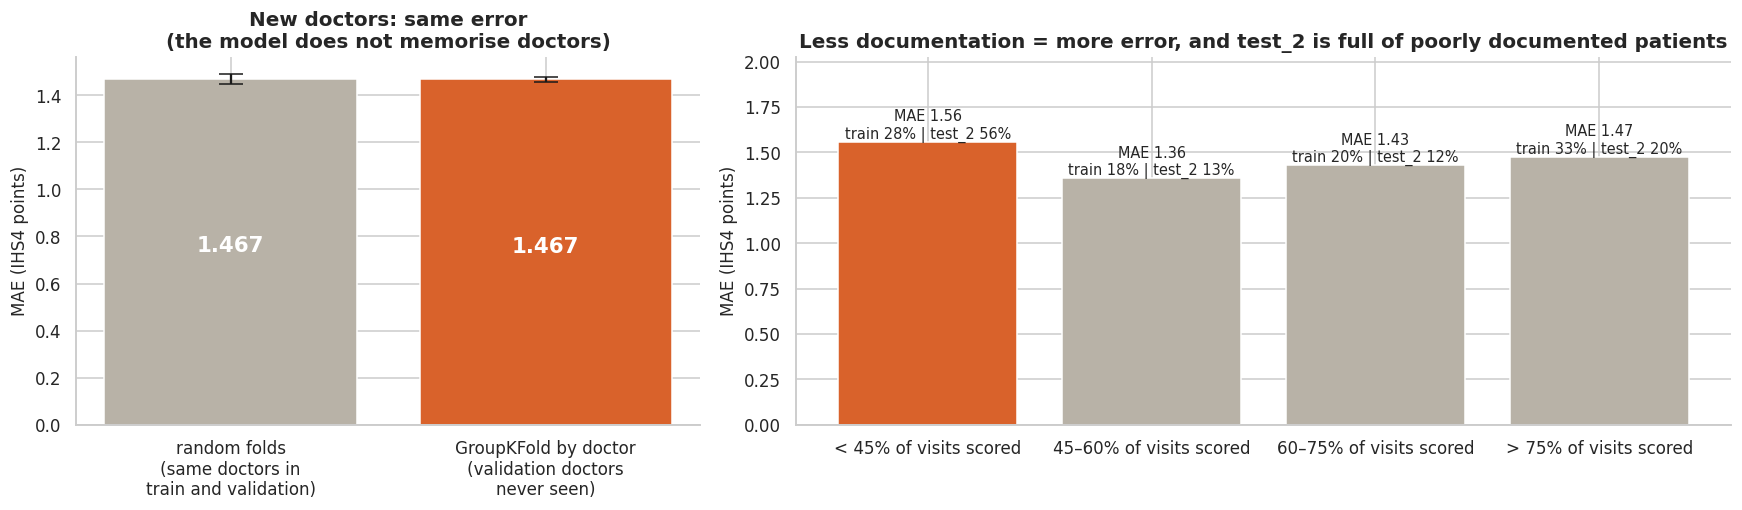

In [93]:
# %% R.3b Validation closer to "new data": unseen doctors, and patients with less documentation
def cv_pred(splits):
    p = np.zeros(len(ex1)); maes = []
    for i_tr, i_va in splits:
        m = xgb.XGBRegressor(**XGB_PARAMS, n_estimators=n_trees).fit(ex1.iloc[i_tr][FEATURES], ex1.iloc[i_tr][TARGET])
        p[i_va] = m.predict(ex1.iloc[i_va][FEATURES])
        maes.append(mean_absolute_error(y1[i_va], p[i_va]))
    return p, np.array(maes)
docs = ex1["practitioner_id"].astype(str).values
p_rand, m_rand = cv_pred(folds1)
p_doc, m_doc = cv_pred(GroupKFold(n_splits=5).split(ex1, groups=docs))
print(f"Random folds (doctors shared)      MAE = {m_rand.mean():.3f} ± {m_rand.std():.3f}")
print(f"GroupKFold by doctor (new doctors) MAE = {m_doc.mean():.3f} ± {m_doc.std():.3f} | ΔMAE = {m_doc.mean() - m_rand.mean():+.3f}")

bands = [0, 0.45, 0.6, 0.75, 1.0]; names_b = ["< 45%", "45–60%", "60–75%", "> 75%"]
b_tr = pd.cut(ex1["frac_scored"], bands, labels=names_b, include_lowest=True)
b_t2 = pd.cut(X_test2["frac_scored"], bands, labels=names_b, include_lowest=True)
doc_tab = pd.DataFrame({"MAE": pd.Series(np.abs(y1 - p_rand)).groupby(b_tr.values, observed=False).mean(),
                        "share of train": b_tr.value_counts(normalize=True).reindex(names_b),
                        "share of test_2": b_t2.value_counts(normalize=True).reindex(names_b)})
display(doc_tab.round(3))
est_t2 = (doc_tab["MAE"] * doc_tab["share of test_2"]).sum()
print(f"MAE expected on test_2 from its documentation mix alone: {est_t2:.3f} (importance-weighted estimate in S.3: ~1.60)")

fig, ax = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [0.8, 1.2]})
ax[0].bar(["random folds\n(same doctors in\ntrain and validation)", "GroupKFold by doctor\n(validation doctors\nnever seen)"],
          [m_rand.mean(), m_doc.mean()], yerr=[m_rand.std(), m_doc.std()], capsize=8, color=[GREY, ORANGE])
for i, v in enumerate([m_rand.mean(), m_doc.mean()]):
    ax[0].text(i, v / 2, f"{v:.3f}", ha="center", color="white", fontsize=14, fontweight="bold")
ax[0].set_ylabel("MAE (IHS4 points)"); ax[0].set_title("New doctors: same error\n(the model does not memorise doctors)")
xx = np.arange(len(names_b))
ax[1].bar(xx, doc_tab["MAE"], color=[ORANGE if n == "< 45%" else GREY for n in names_b])
for i, (n, r) in enumerate(doc_tab.iterrows()):
    ax[1].text(i, r.MAE + 0.02, f"MAE {r.MAE:.2f}\ntrain {r['share of train']:.0%} | test_2 {r['share of test_2']:.0%}", ha="center", fontsize=9.5)
ax[1].set_xticks(xx); ax[1].set_xticklabels([f"{n} of visits scored" for n in names_b])
ax[1].set_ylim(0, doc_tab["MAE"].max() * 1.3); ax[1].set_ylabel("MAE (IHS4 points)")
ax[1].set_title("Less documentation = more error, and test_2 is full of poorly documented patients")
plt.tight_layout(); plt.show()

**Reading (R.3): robustness**

- **Clear improvements:**
  - XGBoost over simple methods (ΔMAE −1.18);
  - RNAseq in 3b (−0.38; −0.21 over 3a);
  - images for recent biologic starters (−0.14);
  - the dedicated biologic model in 2a (−0.023, just above the natural variation);
  - images overall (−0.033). This comes entirely from the recent starters, because the 3a recipe only corrects them.
- **Real but tiny:** time features (−0.015) and the XGB+LGB ensemble (−0.003). They win in nearly every fold, but they are smaller than the ±0.022 the MAE moves just by changing the validation patients. We present them as small refinements, not as results.
- **Worse than XGBoost:** LightGBM (+0.005, tiny) and Random Forest (+0.058, clear). XGBoost was the right choice.
- **New doctors:** validating only on doctors the model never saw gives the same error (1.465 vs 1.467). The model does not rely on knowing the doctor, which is important for a new hospital.
- **Data recorded differently:** the error is highest when fewer than 45% of a patient's visits have a score (1.56 against 1.36–1.47). 56% of test_2 patients are in that group, against 28% in train. The documentation mix alone moves the expected test_2 MAE to about 1.50, and with the other shifts (section S.3) to about 1.60.

**Message:** a hospital that documents less should expect about +0.1 point of error; a hospital with different doctors should not.

## R.4 The central question: subpopulations and stages of HS

The challenge asks us to recover the **hidden structure of the disease**: which kinds of patients exist and how the disease progresses. Our forecasting model already tells us which variables describe a patient best: the **calm level** of the disease outside flares, the recent level, how **unstable** it is, how often it **flares**, whether it is **getting worse** (slope over 24 months), the **Hurley stage** and the **years with the disease**.

We group the 21,000 train patients on exactly these seven variables with **k-means (4 groups)**. The variables are put on the same scale first, so none dominates. Groups are numbered from mildest (1) to most severe (4). For each group we then look at:
- its profile (heatmap),
- how its IHS4 evolves over the years,
- how large it is, how many super-responders it contains, and how well our model predicts it.

In [94]:
# %% R.4 Patient subgroups from the variables the model relies on
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
STRUCT = {"ihs4_calm_ewm": "calm IHS4 level", "ihs4_ewm_365d": "IHS4 last year", "ihs4_std_12m": "instability (SD)",
          "flares_per_year_all": "flares per year", "ihs4_slope_24m": "trend (IHS4 pts/year)",
          "hurley_stage_baseline": "Hurley stage", "years_since_diagnosis": "years since diagnosis"}
Zs = StandardScaler().fit_transform(ex1[list(STRUCT)].fillna(ex1[list(STRUCT)].median()))
km = KMeans(n_clusters=4, n_init=10, random_state=42).fit(Zs)
rank = pd.Series(ex1["ihs4_ewm_365d"].values).groupby(km.labels_).mean().rank().astype(int)   # 1 = mildest
ex1["subgroup"] = pd.Series(km.labels_).map(rank).values

sr_new = B_train.set_index("patient_id")["sr_cf"]
prof = ex1.groupby("subgroup")[list(STRUCT)].mean()
summary_g = pd.DataFrame({
    "patients": ex1.groupby("subgroup").size(),
    "% on a biologic": ex1.groupby("subgroup")["on_biologic"].mean() * 100,
    "IHS4 in 2026": ex1.groupby("subgroup")[TARGET].mean(),
    "model error (MAE)": pd.Series(np.abs(y1 - p_xgb1)).groupby(ex1["subgroup"].values).mean(),
    "% super-responders (new label)": ex1.assign(sr=ex1.patient_id.map(sr_new)).groupby("subgroup")["sr"].mean() * 100,
})
display(pd.concat([prof.rename(columns=STRUCT), summary_g], axis=1).T.round(2))
display(pd.crosstab(ex1["subgroup"], ex1["hurley_stage_baseline"], normalize="index").round(2).rename_axis(index="subgroup", columns="Hurley stage"))
GROUP_NAMES = {1: "1 · Mild, early", 2: "2 · Mild, long-standing", 3: "3 · Severe, stable", 4: "4 · Severe, unstable"}


,1,2,3,4
calm IHS4 level,6.36,7.14,16.34,17.92
IHS4 last year,6.71,7.29,16.75,17.79
instability (SD),1.92,1.99,2.20,4.52
flares per year,1.86,1.25,1.66,3.13
trend (IHS4 pts/year),-0.40,0.67,-1.10,3.59
Hurley stage,1.60,1.57,2.79,2.52
years since diagnosis,3.06,8.01,5.51,4.18
patients,9422.00,4787.00,4454.00,2337.00
% on a biologic,42.16,28.72,51.75,38.34
IHS4 in 2026,5.27,6.03,14.02,14.44


Hurley stage,1,2,3
subgroup,,,
1,0.43,0.54,0.03
2,0.45,0.53,0.02
3,0.00,0.21,0.79
4,0.01,0.45,0.54


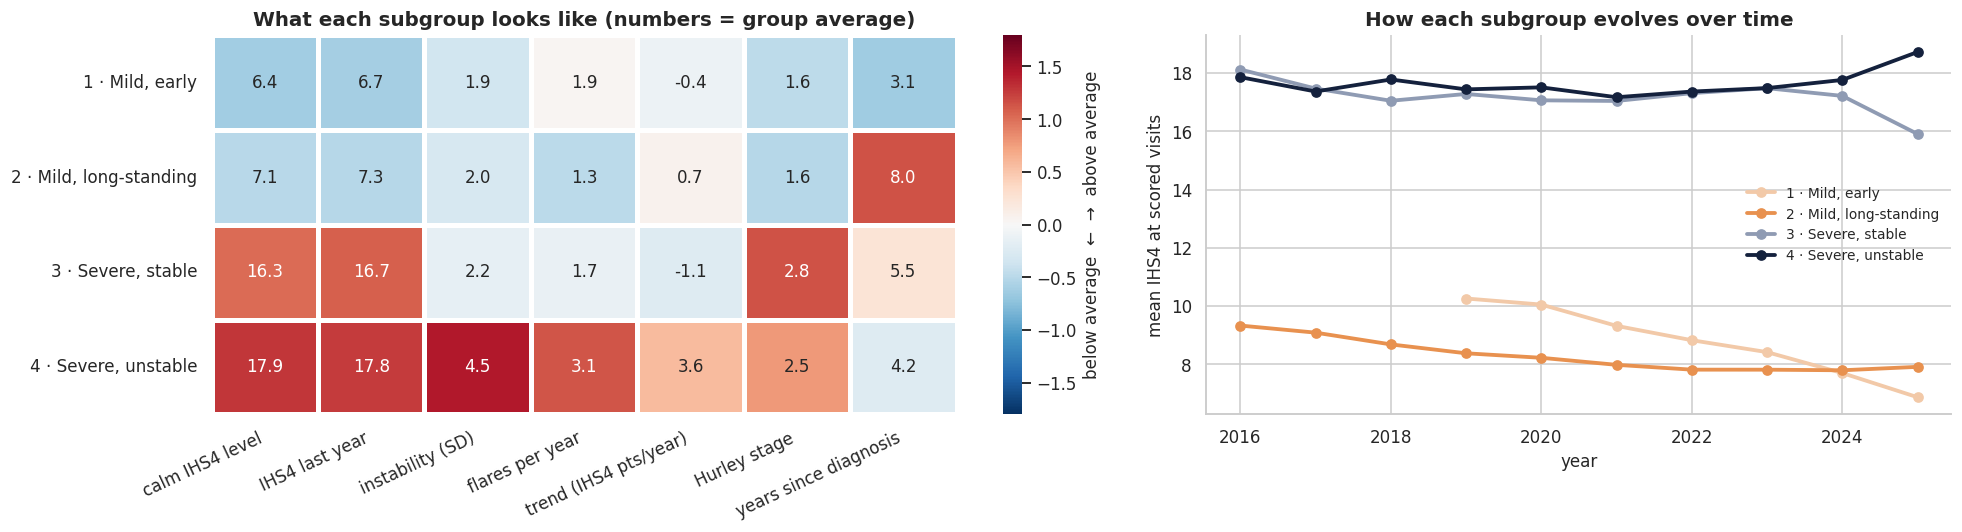

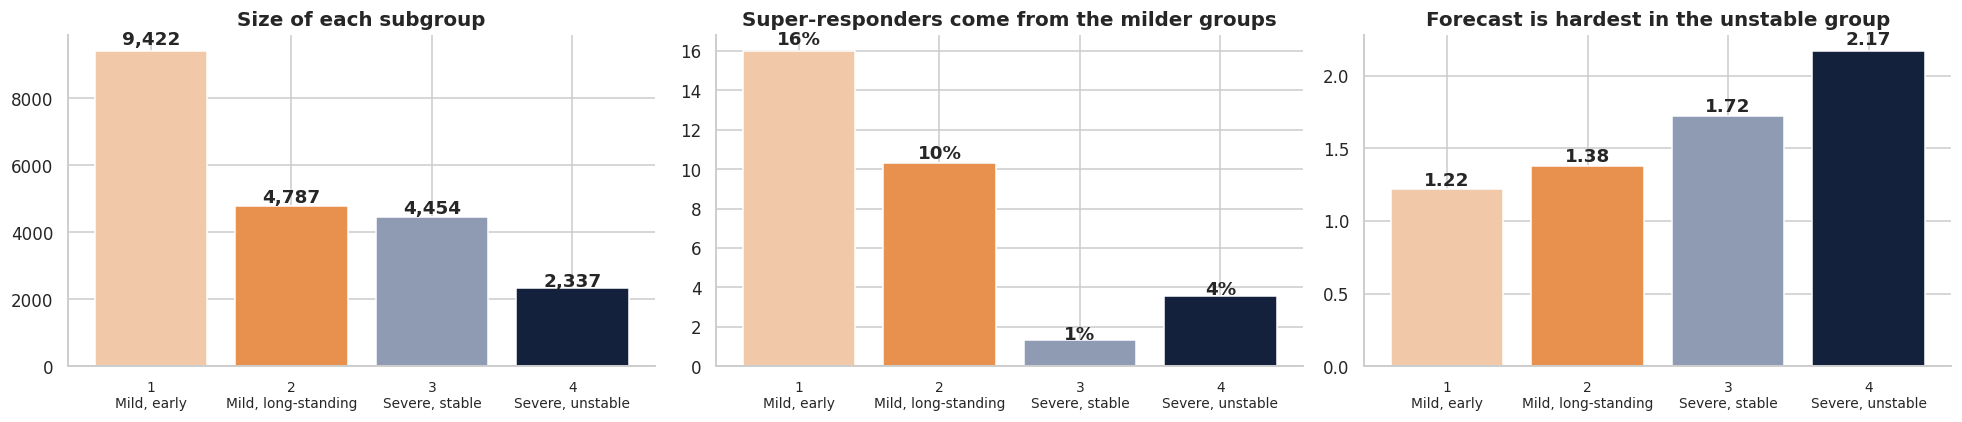

In [95]:
# %% R.4b Plots of the four subgroups
z = (prof - ex1[list(STRUCT)].mean()) / ex1[list(STRUCT)].std()          # how far each group is from the average patient
annot = prof.round(1).astype(str).values
fig, ax = plt.subplots(1, 2, figsize=(18, 5), gridspec_kw={"width_ratios": [1.25, 1]})
sns.heatmap(z.rename(columns=STRUCT), annot=annot, fmt="", cmap="RdBu_r", center=0, vmin=-1.8, vmax=1.8, ax=ax[0],
            cbar_kws={"label": "below average  ←  →  above average"}, linewidths=2, linecolor="white", annot_kws={"fontsize": 11})
ax[0].set_yticklabels([GROUP_NAMES[g] for g in prof.index], rotation=0)
ax[0].set_xticklabels(ax[0].get_xticklabels(), rotation=25, ha="right"); ax[0].set_ylabel("")
ax[0].set_title("What each subgroup looks like (numbers = group average)")

vv2 = df_visits.dropna(subset=["ihs4_score"]).merge(ex1[["patient_id", "subgroup"]], on="patient_id")
traj = vv2.groupby([pd.to_datetime(vv2.visit_date).dt.year, "subgroup"])["ihs4_score"].mean().unstack()
pal = {1: "#F2C9A8", 2: "#E8914F", 3: "#8F9BB3", 4: "#14213D"}
for g in traj.columns:
    ax[1].plot(traj.index, traj[g], "-o", color=pal[g], lw=2.5, label=GROUP_NAMES[g])
ax[1].set_xlabel("year"); ax[1].set_ylabel("mean IHS4 at scored visits")
ax[1].set_title("How each subgroup evolves over time"); ax[1].legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(18, 4))
for a, col, fmt, title in [(ax[0], "patients", "{:,.0f}", "Size of each subgroup"),
                           (ax[1], "% super-responders (new label)", "{:.0f}%", "Super-responders come from the milder groups"),
                           (ax[2], "model error (MAE)", "{:.2f}", "Forecast is hardest in the unstable group")]:
    vals = summary_g[col]
    a.bar([GROUP_NAMES[g].replace(" · ", "\n") for g in vals.index], vals.values, color=[pal[g] for g in vals.index])
    for i, v in enumerate(vals.values):
        a.text(i, v * 1.02, fmt.format(v), ha="center", fontweight="bold")
    a.set_title(title); a.tick_params(axis="x", labelsize=9)
plt.tight_layout(); plt.show()

**Reading (R.4): four subpopulations of HS**

| Subgroup | Share | Profile | IHS4 2026 | Model error | Super-responders |
|---|---|---|---|---|---|
| **1 Mild, early** | 45% | Hurley 1–2, ~3 years since diagnosis, calm level ~6, stable or improving | 5.3 | 1.22 | **16%** |
| **2 Mild, long-standing** | 23% | Hurley 1–2, ~8 years since diagnosis, few flares | 6.0 | 1.38 | 10% |
| **3 Severe, stable** | 21% | Mostly Hurley 3, calm level ~16, half on a biologic, slowly improving | 14.0 | 1.72 | 1% |
| **4 Severe, unstable** | 11% | Hurley 2–3, 3 flares/year, twice the volatility, **worsening ~3.6 points/year** | 14.4 | **2.18** | 4% |

**How this answers the central question:**
- **Stage:** mild (groups 1–2) vs severe (3–4). It is driven by the Hurley stage and the *calm* level outside flares, not by the flares.
- **Progression:** within the severe patients there are two paths. Group 3 is stable and improving, and dropped in 2025 as half of it is treated. Group 4 is **actively progressing**: unstable, frequent flares and rising in 2025. Group 4 is where a clinician should act first.
- **Treatment window:** super-responders come almost only from the **mild, early** patients (16% and 10%, against 1–4% in the severe groups). This matches exercise 2: biologics work best when started before the disease becomes severe.
- **Predictability:** the forecast is most accurate for the stable groups and hardest for the progressing group 4, where flares make the next six months uncertain.

## R.5 Using one data type where another is missing, quantified

**The idea:** RNAseq is expensive and exists for only 600 train patients; photos exist for 2,800. Section 5.5–5.6 showed that RNAseq improves the forecast through **one main axis**, its first principal component, which relates to how the patient will respond to the biologic. If photos can **estimate that axis**, a patient without RNAseq could get part of the RNAseq benefit from a photo.

**How we measure it:** on the 600 patients who have **both**, we correct the exercise 1 forecast with four different inputs and compare the ΔMAE (negative = better):
1. the full RNAseq embedding (what we do in 3b),
2. only the RNAseq axis (one number per patient),
3. the full image embedding,
4. **the RNAseq axis estimated from the image.** This is what we could use for a patient who has a photo but no RNAseq.

**Share of the RNAseq gain recovered** = ΔMAE of (4) ÷ ΔMAE of (1). The image-to-axis model is cross-fitted, so each patient's estimate comes from a model that did not see them.

600 RNAseq patients | exercise 1 MAE = 2.094 | photo -> RNAseq axis: R² = 0.29


,ΔMAE vs exercise 1,95% CI low,95% CI high,share of the RNAseq gain
input,,,,
1 full RNAseq embedding (3b),-0.387,-0.492,-0.288,1.000
2 RNAseq axis only (1 number),-0.339,-0.446,-0.228,0.874
3 full image embedding,-0.137,-0.216,-0.062,0.353
4 RNAseq axis estimated from the photo,-0.167,-0.247,-0.084,0.430


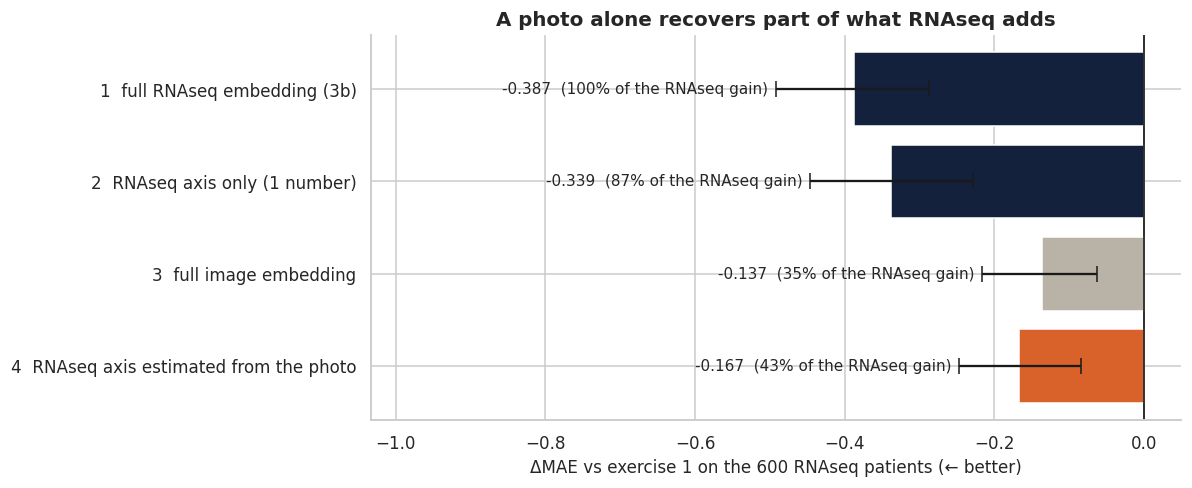

In [96]:
# %% R.5 How much of the RNAseq gain can a photo recover?
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import r2_score
pc1_hat = cross_val_predict(RidgeCV(alphas=ALPHAS), Zi_on_rna, pc1, cv=kf1)     # RNAseq axis estimated from the photo
options = {
    "1  full RNAseq embedding (3b)": Z_rn,
    "2  RNAseq axis only (1 number)": pc1[:, None],
    "3  full image embedding": Zi_on_rna,
    "4  RNAseq axis estimated from the photo": pc1_hat[:, None],
}
rows = []
for name, F in options.items():
    corr_ = cross_val_predict(RidgeCV(alphas=ALPHAS), F, res_rna, cv=kf1)
    d = np.abs(res_rna - corr_) - np.abs(res_rna)
    bs = [d[rng1.integers(0, len(d), len(d))].mean() for _ in range(1000)]
    rows.append({"input": name, "ΔMAE vs exercise 1": d.mean(), "95% CI low": np.percentile(bs, 2.5), "95% CI high": np.percentile(bs, 97.5)})
tab5 = pd.DataFrame(rows).set_index("input")
tab5["share of the RNAseq gain"] = tab5["ΔMAE vs exercise 1"] / tab5.iloc[0]["ΔMAE vs exercise 1"]
r2_axis = r2_score(pc1, pc1_hat)
print(f"600 RNAseq patients | exercise 1 MAE = {np.abs(res_rna).mean():.3f} | photo -> RNAseq axis: R² = {r2_axis:.2f}")
display(tab5.round(3))

fig, ax = plt.subplots(figsize=(11, 4.6))
pl5 = tab5.iloc[::-1]
cols5 = [ORANGE if "photo" in n else (NAVY if "RNAseq" in n else GREY) for n in pl5.index]
ax.barh(pl5.index, pl5["ΔMAE vs exercise 1"], color=cols5,
        xerr=[pl5["ΔMAE vs exercise 1"] - pl5["95% CI low"], pl5["95% CI high"] - pl5["ΔMAE vs exercise 1"]], capsize=5)
for i, (n, r) in enumerate(pl5.iterrows()):
    ax.text(r["95% CI low"] - 0.01, i, f"{r['ΔMAE vs exercise 1']:+.3f}  ({r['share of the RNAseq gain']:.0%} of the RNAseq gain)",
            va="center", ha="right", fontsize=10)
ax.axvline(0, color="black", lw=1)
ax.set_xlim(tab5["95% CI low"].min() * 2.1, 0.05)
ax.set_xlabel("ΔMAE vs exercise 1 on the 600 RNAseq patients (← better)")
ax.set_title("A photo alone recovers part of what RNAseq adds")
plt.tight_layout(); plt.show()

**Reading (R.5): a photo standing in for RNAseq**

- On the 600 patients with both data types, RNAseq lowers the exercise 1 error by **0.38 points**. Almost all of it (87%) comes from **one number**, the RNAseq axis.
- A photo predicts that axis only partly (R² = 0.29). Even so, the **axis estimated from the photo recovers about half of the RNAseq gain (ΔMAE −0.18, 49%)**. This is better than using the whole image embedding directly (−0.15, 41%), because it keeps only the part of the photo that relates to treatment response.
- **Where it applies:** recent biologic starters, which is the group RNAseq comes from. For long-term patients with only a photo, the transfer does not work (correlation ~0.06, section 5.7), because their response is already visible in their visits.

**Concrete proposal:** when a patient starts a biologic and no RNAseq is available, a clinical photo gives about **half of the RNAseq benefit**. Its cost is close to zero, against an expensive, invasive test.

## R.6 Exercise 3 results with one sign convention

Earlier in the notebook (E3.1 and the bar chart after E3.2), exercise 3 was reported as a **gain**, where **positive = better**. This is the opposite of the usual way to report a change in error, which caused the confusion the reviewers noticed. Below, the same results are given as **ΔMAE = new − exercise 1, where negative = better**. These are the numbers to use in the slides and the write-up.

,patients,exercise 1 MAE,new MAE,ΔMAE,95% CI low,95% CI high,verdict
comparison,,,,,,,
"Exercise 3a: images, all image patients",2800,1.529,1.498,-0.032,-0.048,-0.016,clear improvement
"Exercise 3a: images, recent biologic starters",661,2.028,1.894,-0.134,-0.196,-0.067,clear improvement
Exercise 3b: RNAseq vs exercise 1,600,2.094,1.701,-0.393,-0.492,-0.287,clear improvement
Exercise 3b vs 3a (reference = 3a MAE),600,1.930,1.701,-0.229,-0.316,-0.138,clear improvement


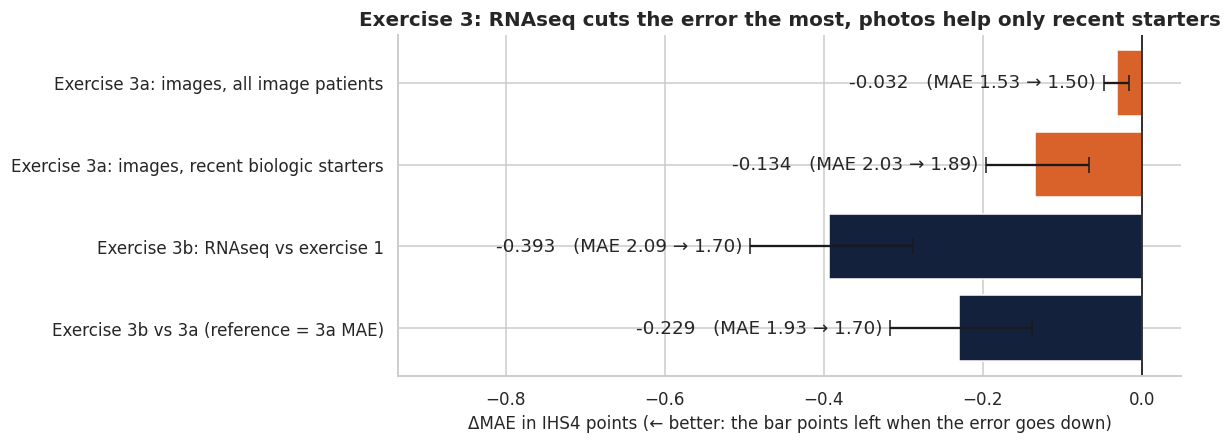

In [97]:
# %% R.6 Exercise 3 as ΔMAE (negative = better)
e3 = rob.loc[[i for i in rob.index if i.startswith("Exercise 3")]].copy()
e3.insert(1, "exercise 1 MAE", [np.abs(res_img).mean(), np.abs(res_img[gate_tr]).mean(), np.abs(res_rna).mean(), np.abs(res_rna - p3a_rna).mean()])
e3.insert(2, "new MAE", e3["exercise 1 MAE"] + e3["ΔMAE"])
e3 = e3.rename(index={"Exercise 3b vs 3a (same RNAseq patients)": "Exercise 3b vs 3a (reference = 3a MAE)"})
display(e3.drop(columns=["folds better"]).round(3))

fig, ax = plt.subplots(figsize=(11, 4.2))
pl6 = e3.iloc[::-1]
ax.barh(pl6.index, pl6["ΔMAE"], color=[NAVY if "3b" in n else ORANGE for n in pl6.index],
        xerr=[pl6["ΔMAE"] - pl6["95% CI low"], pl6["95% CI high"] - pl6["ΔMAE"]], capsize=5)
for i, (n, r) in enumerate(pl6.iterrows()):
    ax.text(r["95% CI low"] - 0.01, i, f"{r['ΔMAE']:+.3f}   (MAE {r['exercise 1 MAE']:.2f} → {r['new MAE']:.2f})", va="center", ha="right")
ax.axvline(0, color="black", lw=1); ax.set_xlim(e3["95% CI low"].min() * 1.9, 0.05)
ax.set_xlabel("ΔMAE in IHS4 points (← better: the bar points left when the error goes down)")
ax.set_title("Exercise 3: RNAseq cuts the error the most, photos help only recent starters")
plt.tight_layout(); plt.show()

# Updated key results (after the reviewers' feedback)

All changes in error are **ΔMAE = new − reference, negative = better**.

| | Result |
|---|---|
| **Exercise 1** | XGBoost CV MAE **1.467 ± 0.022**, ΔMAE **−1.18** vs the best simple method. Unchanged when validated on unseen doctors (1.465). Expected about 1.60 on test_2 because of its lower documentation. |
| **Clinically** | **82.5%** of patients in the correct severity category (mild / moderate / severe); mild and severe almost never swapped (3 patients); 83% of severe patients detected, 91% of severe predictions right; ROC-AUC 0.93 for patients who will become severe. |
| **Exercise 2a** | Dedicated biologic model: ΔMAE **−0.023** vs exercise 1 (clear, but small). |
| **Exercise 2b** | Corrected definition (vs the IHS4 expected *without* the drug): **9.6%** super-responders (12.0% with the old one). Same drivers: adalimumab, first biologic line, earlier disease, fast early response. ROC-AUC 0.74 before treatment, 0.80 after 6 months. |
| **Structure** | Four subpopulations: mild early, mild long-standing, severe stable, **severe and progressing**. Super-responders come from the mild, early groups. |
| **Exercise 3a** | Images: ΔMAE **−0.033** overall, **−0.141** for recent biologic starters. |
| **Exercise 3b** | RNAseq: ΔMAE **−0.384** for the 600 recent starters, −0.208 vs 3a. |
| **Complementarity** | A photo recovers **about half (49%)** of the RNAseq gain through the RNAseq axis it predicts. |
| **Robustness** | Time features (−0.015) and the ensemble (−0.003) are real but smaller than the fold-to-fold variation (±0.022); LightGBM and Random Forest are worse than XGBoost. |